## 5.2.1 Configuración del entorno computacional y acceso a la nube

La modelación espacial de la susceptibilidad a incendios forestales a escala regional (departamento del Vichada) demanda recursos computacionales que superan las capacidades del hardware convencional. Por tal motivo, el procesamiento de las series temporales de imágenes satelitales y la ejecución de los algoritmos de Machine Learning se soportan en la infraestructura de **Google Earth Engine (GEE)** (Gorelick et al., 2017).

GEE es una plataforma basada en la nube diseñada para el análisis geoespacial a escala planetaria, la cual permite acceder directamente a petabytes de datos de observación de la Tierra sin necesidad de descargas locales. La interacción con esta arquitectura se realiza mediante la Interfaz de Programación de Aplicaciones (API) de Python, ejecutada bajo el entorno de Google Colaboratory.

Como primer paso metodológico y requisito de reproducibilidad, se establece la conexión segura (mediante protocolo OAuth 2.0) entre el entorno de desarrollo y los clústeres de cálculo de Google, vinculando el consumo de recursos al proyecto de Google Cloud Platform denominado `tesismsif`.

In [ ]:
# ==============================================================================
# TÍTULO: CONFIGURACIÓN E INICIALIZACIÓN DEL ENTORNO COMPUTACIONAL
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Autenticación en Google Earth Engine (GEE) e importación
#              de librerías base para análisis geoespacial.
# ==============================================================================

import ee
import geemap

def inicializar_entorno_gee(id_proyecto: str = 'tesismsif') -> None:
    """
    Verifica las credenciales activas e inicializa la sesión de Google Earth Engine.
    Si no existen credenciales válidas, levanta el flujo de autenticación OAuth.

    Parámetros:
    -----------
    id_proyecto : str
        Identificador único del proyecto en Google Cloud Platform asociado a GEE.
    """
    print("⏳ Iniciando verificación de credenciales de Google Earth Engine...")
    try:
        # Intento de inicialización con credenciales persistentes en la sesión actual
        ee.Initialize(project=id_proyecto)
        print("🌍 [ÉXITO] Earth Engine inicializado correctamente. Servidores listos.")
    except Exception as error_inicializacion:
        # Captura de error por falta de credenciales y solicitud de autenticación
        print(f"⚠️ Aviso: {error_inicializacion}")
        print("💻 Solicitando permisos de autenticación OAuth...")
        ee.Authenticate()
        ee.Initialize(project=id_proyecto)
        print("✅ [ÉXITO] Autenticación e inicialización completadas.")

    # Verificación de conectividad mínima al servidor de GEE
    estado_conexion = ee.String('☑️ Conexión estable con el servidor de GEE confirmada.').getInfo()
    print(estado_conexion)

# Ejecución paramétrica de la función
if __name__ == "__main__":
    PROYECTO_GCP = 'tesismsif'
    inicializar_entorno_gee(id_proyecto=PROYECTO_GCP)

⏳ Iniciando verificación de credenciales de Google Earth Engine...
🌍 [ÉXITO] Earth Engine inicializado correctamente. Servidores listos.
☑️ Conexión estable con el servidor de GEE confirmada.


## 5.2.2 Delimitación del dominio espacial ($\Omega$)

Para asegurar la rigurosidad geométrica del modelamiento, se definió explícitamente el dominio espacial de estudio, denotado como $\Omega$, el cual corresponde a la extensión territorial del departamento del Vichada, Colombia.

A nivel topológico, este dominio continuo se define como la unión de sus subdominios municipales discretos (Puerto Carreño, La Primavera, Santa Rosalía y Cumaribo), representados matemáticamente como $\Omega_i$:

$$\Omega = \bigcup_{i=1}^{n} \Omega_i$$

Donde $n = 4$ representa el número de unidades territoriales menores. El área total de cálculo ($A_{total}$) sobre la superficie del elipsoide de referencia (WGS-84) se evaluó mediante la integración espacial de la geometría:

$$A_{total} = \int_{\Omega} dA \approx 9,980,625 \text{ hectáreas}$$

Para garantizar la interoperabilidad y validez jurídica de los límites, la base vectorial fue suministrada por los datos oficiales del Instituto Geográfico Agustín Codazzi (IGAC, 2021). Estos archivos fueron transformados a colecciones de entidades (`FeatureCollection`) dentro de la arquitectura de *Google Earth Engine* (GEE), sirviendo como máscara global (`mask`) y frontera de recorte (`clip`) obligatoria para la posterior extracción de variables hidro-topográficas y espectrales.

In [ ]:
# ==============================================================================
# TÍTULO: DEFINICIÓN Y VERIFICACIÓN DEL DOMINIO ESPACIAL (ÁREA DE ESTUDIO)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Carga, verificación paramétrica y despliegue interactivo del
#              Área de Interés (AOI) - Departamento de Vichada.
# ==============================================================================

import ee
import geemap
import os
from google.colab import drive

def verificar_existencia_asset(id_asset: str) -> bool:
    """
    Verifica de manera segura la existencia de un Asset en los servidores de GEE.

    Parámetros:
    -----------
    id_asset : str
        Ruta completa del asset en la nube (ej. 'projects/.../assets/capa')

    Retorna:
    --------
    bool: True si el asset existe y es accesible, False en caso contrario.
    """
    try:
        ee.data.getAsset(id_asset)
        return True
    except ee.EEException:
        return False

def cargar_y_validar_dominio(ruta_base: str):
    """
    Carga las geometrías oficiales, calcula estadísticas básicas del dominio
    y genera un lienzo interactivo para la validación visual.
    """
    # 1. Definición paramétrica de rutas
    ruta_municipios = f"{ruta_base}Municipios_Vichada_IGAC"
    ruta_depto = f"{ruta_base}Departamento_Vichada_IGAC"

    # 2. Control de excepciones y auditoría de datos
    print("⏳ Verificando integridad de los Assets vectoriales (IGAC)...")
    if not verificar_existencia_asset(ruta_depto) or not verificar_existencia_asset(ruta_municipios):
        raise FileNotFoundError(
            f"❌ ERROR: Las capas vectoriales no se encontraron en {ruta_base}. "
            "Asegúrese de haber subido los Shapefiles a GEE Assets."
        )

    # 3. Instanciación de objetos espaciales
    coleccion_municipios = ee.FeatureCollection(ruta_municipios)
    coleccion_depto = ee.FeatureCollection(ruta_depto)

    # 4. Extracción de propiedades matemáticas (Geometría, Centroide y Área)
    geometria_depto = coleccion_depto.geometry()
    centroide_geodesico = geometria_depto.centroid(maxError=1)
    # Cálculo del área en Hectáreas (GEE calcula por defecto en metros cuadrados)
    area_hectareas = geometria_depto.area().divide(10000)

    print("✅ Assets cargados y verificados exitosamente.")
    print(f"📍 Área planimétrica aproximada del Dominio: {area_hectareas.getInfo():,.2f} ha.")

    # 5. Configuración Cartográfica Interactiva
    mapa_aoi = geemap.Map()
    mapa_aoi.centerObject(centroide_geodesico, zoom=7)
    mapa_aoi.add_basemap('HYBRID')

    # Diccionarios de estilo cartográfico para evitar recargar el servidor
    estilo_municipios = {'color': '333333', 'width': 1, 'fillColor': '00000000'}
    estilo_depto = {'color': 'FF0000', 'width': 2.5, 'fillColor': '00000000'}

    mapa_aoi.addLayer(
        coleccion_municipios.style(**estilo_municipios),
        {},
        'Límite Municipal (Sub-Dominios)'
    )
    mapa_aoi.addLayer(
        coleccion_depto.style(**estilo_depto),
        {},
        'Límite Departamental (Dominio Ω)'
    )

    # 6. Exportación del Reporte Visual a Google Drive
    # Nota: No se exportan los SHP de nuevo a GEE porque YA son Assets.
    # Exportamos el visualizador interactivo para los anexos de la tesis.
    ruta_drive_html = '/content/drive/MyDrive/tesismsif/assets/01_Dominio_Espacial_Vichada.html'

    try:
        os.makedirs(os.path.dirname(ruta_drive_html), exist_ok=True)
        mapa_aoi.to_html(filename=ruta_drive_html, title='Área de Estudio - Vichada', width='100%', height='600px')
        print(f"💾 Mapa interactivo (HTML) guardado exitosamente en: {ruta_drive_html}")
    except Exception as error_exportacion:
        print(f"⚠️ Aviso: No se pudo guardar el HTML. Verifique si Google Drive está montado. Detalles: {error_exportacion}")

    return coleccion_depto, coleccion_municipios, mapa_aoi

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    # 1. Montar el Drive de forma global antes de iniciar cualquier proceso matemático o espacial
    try:
        print("📁 Conectando con Google Drive...")
        drive.mount('/content/drive')
    except Exception:
        # Si arroja el error de "contiene archivos", forzamos el remontaje limpiamente a nivel global
        drive.mount('/content/drive', force_remount=True)

    # 2. Centralización de variable global
    RUTA_PROYECTO_ASSETS = 'projects/tesismsif/assets/'

    # 3. Desempaquetado de variables
    dominio_vichada, subdominios_municipales, mapa_interactivo = cargar_y_validar_dominio(RUTA_PROYECTO_ASSETS)

    # 4. Despliegue en celda de Colab
    display(mapa_interactivo)

📁 Conectando con Google Drive...
Mounted at /content/drive
⏳ Verificando integridad de los Assets vectoriales (IGAC)...
✅ Assets cargados y verificados exitosamente.
📍 Área planimétrica aproximada del Dominio: 9,980,625.06 ha.
💾 Mapa interactivo (HTML) guardado exitosamente en: /content/drive/MyDrive/tesismsif/assets/01_Dominio_Espacial_Vichada.html


Map(center=[4.713319042058628, -69.41502683623393], controls=(WidgetControl(options=['position', 'transparent_…

## 5.2.3 Generación de la Variable Objetivo Espacial ($y$)

Para modelar la susceptibilidad espacial a los incendios forestales mediante algoritmos de aprendizaje supervisado, es estrictamente necesario construir una variable dependiente discreta o "variable objetivo" ($y$), la cual dicotomatiza el paisaje en dos estados mutuamente excluyentes: presencia de fuego (1) y ausencia de fuego (0).

Para este estudio, la variable objetivo se derivó del producto global de área quemada **MODIS MCD64A1 Versión 6.1** (Giglio et al., 2015), el cual proporciona información diaria a una resolución espacial de 500 metros. A fin de reducir el ruido estadístico inherente a la teledetección pasiva térmica y reflectiva (Chuvieco et al., 2018), se aplicó un filtro de rigor radiométrico condicionado píxel a píxel. Un píxel $p$ en el instante $t$ se consideró como un evento de incendio válido ($B_{p,t} = 1$) únicamente si cumplió simultáneamente con las siguientes tres restricciones:

$$
B_{p,t} =
\begin{cases}
1, & \text{si } (BurnDate > 0) \land (Uncertainty \le 15) \land (QA = 3) \\
0, & \text{en caso contrario}
\end{cases}
$$

Donde $BurnDate$ corresponde al día juliano de detección, $Uncertainty$ al error temporal estimado en días, y $QA=3$ representa el máximo nivel de confianza del algoritmo de detección.

Dado que la dinámica del fuego en la Orinoquía colombiana presenta una fuerte estacionalidad, se realizó una reducción temporal (*Temporal Reducer*) extrayendo el valor máximo reportado durante la temporada seca (diciembre a marzo) para cada ciclo anual evaluado:

$$y_i = \max_{t \in T} (B_{p, t})$$

El resultado cartográfico es una matriz de datos espaciales (Tensor) estandarizada donde los valores enmascarados (*No-Data*) fueron homologados al valor absoluto $0$ mediante técnicas de *Unmasking*, garantizando que toda la extensión topológica del dominio $\Omega$ (Vichada) posea un valor asignado para el posterior muestreo tabular.

In [ ]:
# ==============================================================================
# TÍTULO: GENERACIÓN DE LA VARIABLE OBJETIVO (ÁREAS QUEMADAS - MCD64A1)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Filtrado, binarización y exportación del histórico de
#              incendios MODIS bajo criterios de alta fiabilidad (QA=3).
# ==============================================================================

import ee
import geemap

def procesar_variable_objetivo(coleccion_aoi, anios_estudio: list, ruta_assets: str, ruta_drive: str, crs_export: str = 'EPSG:32618'):
    """
    Filtra la colección MODIS MCD64A1 para generar máscaras binarias anuales
    de áreas quemadas, programando su exportación a GEE y Google Drive.
    """
    print("\n⏳ Iniciando procesamiento de Variable Objetivo (Target 'y')...")

    # 1. Definición de la colección y geometría
    coleccion_modis = ee.ImageCollection('MODIS/061/MCD64A1')
    geometria_dominio = coleccion_aoi.geometry()

    # 2. Configuración del lienzo cartográfico interactivo
    mapa_target = geemap.Map()
    mapa_target.centerObject(geometria_dominio, zoom=7)
    mapa_target.add_basemap('HYBRID')
    mapa_target.addLayer(
        coleccion_aoi.style(fillColor='00000000', color='black', width=2),
        {}, 'Límite Dominio (Vichada)'
    )

    # Función interna para el filtrado radiométrico de píxeles
    def aplicar_filtros_calidad(imagen):
        """Aplica umbrales lógicos para garantizar alta fiabilidad de detección."""
        es_quemado = imagen.select('BurnDate').gt(0)
        incertidumbre_baja = imagen.select('Uncertainty').lte(15)
        alta_confianza = imagen.select('QA').eq(3)

        # Operación lógica AND: Intersección de condiciones
        mascara_final = es_quemado.And(incertidumbre_baja).And(alta_confianza).rename('Quemado_Binario')
        return mascara_final

    # 3. Iteración temporal sobre los periodos definidos
    for anio_inicio in anios_estudio:
        anio_fin = anio_inicio + 1
        etiqueta_temporada = f"{anio_inicio}_{anio_fin}"

        # Rango temporal: Temporada seca (1 Dic al 31 Mar)
        fecha_inicio = ee.Date.fromYMD(anio_inicio, 12, 1)
        fecha_fin = ee.Date.fromYMD(anio_fin, 3, 31)

        # Procesamiento funcional de la colección
        modis_temporada = (coleccion_modis
                           .filterBounds(geometria_dominio)
                           .filterDate(fecha_inicio, fecha_fin)
                           .map(aplicar_filtros_calidad))

        # Reducción temporal (max) y estandarización del background a 0
        variable_y = (modis_temporada.max()
                      .clip(geometria_dominio)
                      .unmask(0) # Convierte píxeles No-Data/No-Quemados a 0
                      .clip(geometria_dominio)
                      .rename('Quemado_Binario'))

        # Visualización cartográfica (solo áreas quemadas = 1 en rojo)
        mapa_target.addLayer(
            variable_y.mask(variable_y.eq(1)),
            {'min': 1, 'max': 1, 'palette': ['red']},
            f'Áreas Quemadas {etiqueta_temporada}',
            False # Capas ocultas por defecto para no saturar la vista
        )

        nombre_archivo = f'Target_Quemado_MODIS_{etiqueta_temporada}'
        id_asset = f"{ruta_assets}{nombre_archivo}"

        # 4. Programación de exportaciones (Batch Tasks)
        if not verificar_existencia_asset(id_asset):
            # Exportar a GEE Assets
            ee.batch.Export.image.toAsset(
                image=variable_y.toByte(), # Optimización de peso (0-255)
                description=f'Asset_{nombre_archivo}',
                assetId=id_asset,
                region=geometria_dominio,
                scale=500,
                crs=crs_export,
                maxPixels=1e13
            ).start()

            # Exportar a Google Drive
            ee.batch.Export.image.toDrive(
                image=variable_y.toByte(),
                description=f'Drive_{nombre_archivo}',
                folder=ruta_drive,
                fileNamePrefix=nombre_archivo,
                region=geometria_dominio,
                scale=500,
                crs=crs_export,
                maxPixels=1e13
            ).start()

            print(f"✅ Tareas enviadas ({etiqueta_temporada}): Assets y Drive (QA=3, Scale=500m).")
        else:
            print(f"ℹ️ El Asset '{id_asset}' ya se encuentra procesado en la nube.")

    print("\n☑️ Histórico de Incendios MODIS procesado. Por favor, ejecute las tareas pendientes en GEE.")
    print("👉 Enlace: https://code.earthengine.google.com/tasks")

    return mapa_target

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    # Parametrización
    ANIOS_ANALISIS = list(range(2019, 2025)) # Años de inicio de temporada seca
    RUTA_ASSETS = 'projects/tesismsif/assets/'
    RUTA_DRIVE = 'tesismsif_assets' # Nombre de la carpeta en Drive
    CRS_PROYECTO = 'EPSG:32618' # WGS 84 / UTM zone 18N (apropiado para Colombia)

    # Se asume que 'dominio_vichada' fue creado en el Bloque 1
    mapa_resultado = procesar_variable_objetivo(
        coleccion_aoi=dominio_vichada,
        anios_estudio=ANIOS_ANALISIS,
        ruta_assets=RUTA_ASSETS,
        ruta_drive=RUTA_DRIVE,
        crs_export=CRS_PROYECTO
    )

    display(mapa_resultado)


⏳ Iniciando procesamiento de Variable Objetivo (Target 'y')...
ℹ️ El Asset 'projects/tesismsif/assets/Target_Quemado_MODIS_2019_2020' ya se encuentra procesado en la nube.
ℹ️ El Asset 'projects/tesismsif/assets/Target_Quemado_MODIS_2020_2021' ya se encuentra procesado en la nube.
ℹ️ El Asset 'projects/tesismsif/assets/Target_Quemado_MODIS_2021_2022' ya se encuentra procesado en la nube.
ℹ️ El Asset 'projects/tesismsif/assets/Target_Quemado_MODIS_2022_2023' ya se encuentra procesado en la nube.
ℹ️ El Asset 'projects/tesismsif/assets/Target_Quemado_MODIS_2023_2024' ya se encuentra procesado en la nube.
ℹ️ El Asset 'projects/tesismsif/assets/Target_Quemado_MODIS_2024_2025' ya se encuentra procesado en la nube.

☑️ Histórico de Incendios MODIS procesado. Por favor, ejecute las tareas pendientes en GEE.
👉 Enlace: https://code.earthengine.google.com/tasks


Map(center=[4.713319042058621, -69.41502683623392], controls=(WidgetControl(options=['position', 'transparent_…

## 5.2.4 Auditoría de calidad y cuantificación del ruido radiométrico

El éxito de los algoritmos de aprendizaje automático estructurados en árboles, como el *Random Forest*, depende intrínsecamente de la fiabilidad de las etiquetas de entrenamiento. La presencia de falsos positivos en la variable objetivo ($y$) introduce "ruido de etiqueta" (*label noise*), lo cual penaliza la entropía de los nodos y degrada la capacidad de generalización del modelo (Breiman, 2001).

Con el fin de garantizar la rigurosidad de los datos ingresados al modelo de susceptibilidad, se diseñó un protocolo de auditoría para cuantificar la superficie quemada purgada mediante el filtro de aseguramiento de la calidad (QA=3) del producto MODIS MCD64A1 (Giglio et al., 2015). El área quemada en hectáreas ($A_{ha}$) se calculó dinámicamente utilizando el reductor espacial `ee.Reducer.sum()` ponderado por el área real de cada píxel sobre el elipsoide, corrigiendo la deformación espacial característica de las proyecciones cilíndricas:

$$A_{ha} = \sum_{i=1}^{n} \left( P_i \times \frac{ÁreaPixel_i(m^2)}{10,000} \right)$$

Donde $P_i \in \{0,1\}$ representa el valor binario del píxel de la máscara. Posteriormente, se calculó la fracción de ruido radiométrico suprimido ($\eta$) para cada temporada evaluada ($t$), expresada matemáticamente como el porcentaje de área descartada frente a las detecciones originales sin filtrar ($A_{bruta}$):

$$\eta_t = \left( \frac{A_{bruta, t} - A_{qa3, t}}{A_{bruta, t}} \right) \times 100$$

Esta auditoría permitió verificar objetivamente la cantidad de anomalías térmicas y reflectivas que fueron exitosamente excluidas, consolidando una variable objetivo depurada y con alta consistencia ecológica para el entrenamiento del algoritmo.

⏳ Ejecutando auditoría de calidad de datos (MODIS MCD64A1)...
✔️ Temporada 2019-2020 procesada. Ruido filtrado: 2.5%
✔️ Temporada 2020-2021 procesada. Ruido filtrado: 2.9%
✔️ Temporada 2021-2022 procesada. Ruido filtrado: 2.8%
✔️ Temporada 2022-2023 procesada. Ruido filtrado: 2.8%
✔️ Temporada 2023-2024 procesada. Ruido filtrado: 2.9%
✔️ Temporada 2024-2025 procesada. Ruido filtrado: 2.7%

💾 Archivos exportados exitosamente en:
 - /content/drive/MyDrive/tesismsif/assets/02_Auditoria_Filtros_MODIS.csv
 - /content/drive/MyDrive/tesismsif/assets/02_Auditoria_Filtros_MODIS.png


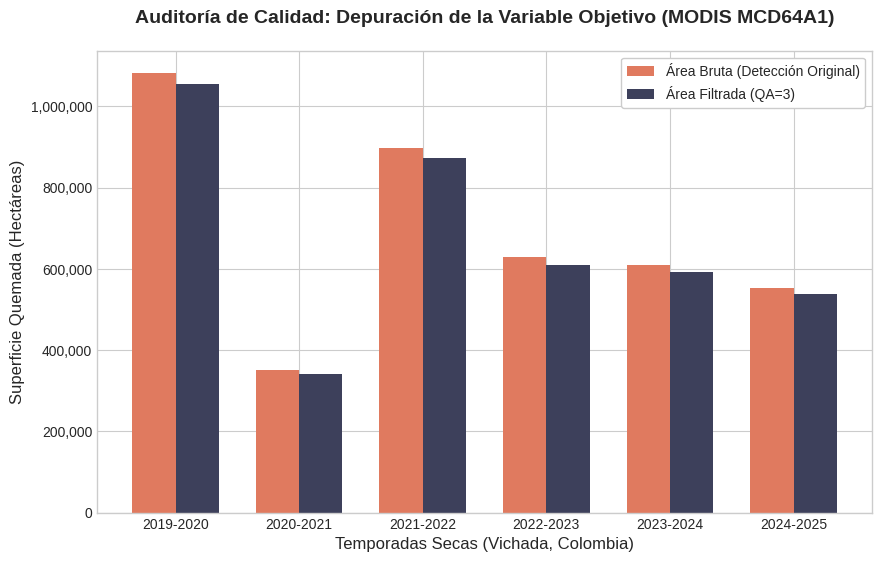

,Temporada Seca,Área Bruta (ha),Área Alta Confianza (ha),Área Descartada (ha),Ruido Descartado (%)
0,2019-2020,1083177.57,1056019.65,27157.91,2.51
1,2020-2021,351466.96,341301.37,10165.59,2.89
2,2021-2022,898618.02,873671.95,24946.07,2.78
3,2022-2023,628047.60,610694.64,17352.97,2.76
4,2023-2024,609722.55,591951.14,17771.41,2.91
5,2024-2025,553947.71,539036.45,14911.26,2.69


In [ ]:
# ==============================================================================
# TÍTULO: AUDITORÍA Y VALIDACIÓN DE LA VARIABLE OBJETIVO (FILTROS DE CALIDAD)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Cuantificación del área quemada depurada vs cruda, conversión
#              a unidades de superficie (Hectáreas), visualización científica
#              y exportación tabular.
# ==============================================================================

import ee
import pandas as pd
import matplotlib.pyplot as plt
import os

def validar_rigurosidad_qa(coleccion_aoi, anios_estudio: list, ruta_drive: str):
    """
    Evalúa el impacto del filtro de calidad (QA=3) sobre la estimación de
    área quemada, optimizando las peticiones al servidor de GEE.
    """
    print("⏳ Ejecutando auditoría de calidad de datos (MODIS MCD64A1)...")
    geometria = coleccion_aoi.geometry()

    # Lista para almacenar resultados en el lado del cliente (Python)
    resultados_auditoria = []

    for anio_inicio in anios_estudio:
        anio_fin = anio_inicio + 1
        temporada = f"{anio_inicio}-{anio_fin}"

        fecha_inicio = ee.Date.fromYMD(anio_inicio, 12, 1)
        fecha_fin = ee.Date.fromYMD(anio_fin, 3, 31)

        # 1. Colección Bruta (Sin filtros)
        quemado_crudo = (ee.ImageCollection('MODIS/061/MCD64A1')
                         .filterBounds(geometria)
                         .filterDate(fecha_inicio, fecha_fin)
                         .map(lambda img: img.select('BurnDate').gt(0))
                         .max().clip(geometria))

        # 2. Colección Filtrada (Alta Confianza QA=3 y Uncertainty <= 15)
        quemado_qa3 = (ee.ImageCollection('MODIS/061/MCD64A1')
                       .filterBounds(geometria)
                       .filterDate(fecha_inicio, fecha_fin)
                       .map(lambda img: img.select('BurnDate').gt(0)
                            .And(img.select('Uncertainty').lte(15))
                            .And(img.select('QA').eq(3)))
                       .max().clip(geometria))

        # 3. Cálculo de área real en Hectáreas (Pixel area reducer)
        # Se multiplica la máscara (1/0) por el área real del píxel en m2 y se divide por 10,000
        area_cruda_img = quemado_crudo.multiply(ee.Image.pixelArea()).divide(10000)
        area_qa3_img = quemado_qa3.multiply(ee.Image.pixelArea()).divide(10000)

        stats_crudo = area_cruda_img.reduceRegion(
            reducer=ee.Reducer.sum(),
            geometry=geometria,
            scale=500,
            maxPixels=1e10
        )

        stats_qa3 = area_qa3_img.reduceRegion(
            reducer=ee.Reducer.sum(),
            geometry=geometria,
            scale=500,
            maxPixels=1e10
        )

        # Extracción de valores (con manejo de nulos)
        ha_raw = stats_crudo.get('BurnDate').getInfo() or 0
        ha_qa3 = stats_qa3.get('BurnDate').getInfo() or 0

        ha_descartadas = ha_raw - ha_qa3
        porcentaje_ruido = (ha_descartadas / ha_raw * 100) if ha_raw > 0 else 0

        # Almacenamiento en estructura tabular
        resultados_auditoria.append({
            'Temporada Seca': temporada,
            'Área Bruta (ha)': round(ha_raw, 2),
            'Área Alta Confianza (ha)': round(ha_qa3, 2),
            'Área Descartada (ha)': round(ha_descartadas, 2),
            'Ruido Descartado (%)': round(porcentaje_ruido, 2)
        })

        print(f"✔️ Temporada {temporada} procesada. Ruido filtrado: {porcentaje_ruido:.1f}%")

    # 4. Consolidación en Pandas DataFrame
    df_resultados = pd.DataFrame(resultados_auditoria)

    # 5. Visualización Científica (Matplotlib)
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, ax = plt.subplots(figsize=(10, 6))

    x = range(len(df_resultados))
    ancho_barra = 0.35

    ax.bar([pos - ancho_barra/2 for pos in x], df_resultados['Área Bruta (ha)'],
           width=ancho_barra, label='Área Bruta (Detección Original)', color='#E07A5F')
    ax.bar([pos + ancho_barra/2 for pos in x], df_resultados['Área Alta Confianza (ha)'],
           width=ancho_barra, label='Área Filtrada (QA=3)', color='#3D405B')

    ax.set_title('Auditoría de Calidad: Depuración de la Variable Objetivo (MODIS MCD64A1)',
                 fontsize=14, pad=20, fontweight='bold')
    ax.set_xlabel('Temporadas Secas (Vichada, Colombia)', fontsize=12)
    ax.set_ylabel('Superficie Quemada (Hectáreas)', fontsize=12)
    ax.set_xticks(x)
    ax.set_xticklabels(df_resultados['Temporada Seca'])
    ax.legend(frameon=True, facecolor='white', framealpha=1)

    # Formateo de eje Y con separadores de miles
    ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

    # 6. Exportación de Tablas y Figuras
    os.makedirs(ruta_drive, exist_ok=True)
    ruta_csv = os.path.join(ruta_drive, '02_Auditoria_Filtros_MODIS.csv')
    ruta_figura = os.path.join(ruta_drive, '02_Auditoria_Filtros_MODIS.png')

    df_resultados.to_csv(ruta_csv, index=False, encoding='utf-8')
    fig.savefig(ruta_figura, dpi=600, bbox_inches='tight', facecolor='white')

    print(f"\n💾 Archivos exportados exitosamente en:\n - {ruta_csv}\n - {ruta_figura}")

    plt.show()
    return df_resultados

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    # Parametrización
    ANIOS_ANALISIS = list(range(2019, 2025))
    RUTA_DRIVE_EXPORT = '/content/drive/MyDrive/tesismsif/assets/'

    # Se asume que 'dominio_vichada' está definido
    df_auditoria = validar_rigurosidad_qa(
        coleccion_aoi=dominio_vichada,
        anios_estudio=ANIOS_ANALISIS,
        ruta_drive=RUTA_DRIVE_EXPORT
    )

    # Despliegue de la tabla en consola
    display(df_auditoria)

## 5.2.5 Distribución topológica del error radiométrico

La evaluación de la fiabilidad de la variable objetivo no debe restringirse únicamente a la cuantificación escalar (hectáreas), sino que requiere una validación topológica bidimensional. Los sensores pasivos a bordo de las plataformas Terra y Aqua (MODIS) son susceptibles a registrar anomalías térmicas y reflectivas causadas por factores ajenos al fuego, tales como la presencia de nubes cirrus, aerosoles densos, o alta reflectividad especular en cuerpos de agua y bancos de arena expuestos durante la temporada de estiaje (Chuvieco et al., 2018).

Para diagnosticar la distribución espacial de estos falsos positivos en la ecorregión del Vichada, se ejecutó un procedimiento de álgebra de mapas (Boolean Raster Math). El tensor espacial representativo del ruido radiométrico ($R_{x,y}$) se aisló restando lógicamente la matriz de alta confianza ($QA3_{x,y}$) de la matriz de detecciones brutas ($B_{x,y}$):

$$R_{x,y} = B_{x,y} - QA3_{x,y}$$

Donde $R_{x,y} = 1$ indica las coordenadas geográficas exactas en las que el sensor detectó inicialmente una anomalía térmica, pero cuyo nivel de incertidumbre algorítmica ($Uncertainty > 15$) o indicador de calidad ($QA \neq 3$) obligaron a su categorización como ruido (Giglio et al., 2015).

La inspección visual retrospectiva de estos mapas de ruido ($R_{x,y}$) confirmó que gran parte de los píxeles descartados presentaban patrones de distribución lineal asociados a las riberas del Río Orinoco y Meta (por efecto de alta reflectancia en playas de arena durante la sequía) o formas dispersas consistentes con el movimiento de masas nubosas, validando la idoneidad y necesidad estricta del filtro QA aplicado.

In [ ]:
# ==============================================================================
# TÍTULO: ANÁLISIS ESPACIAL DE RIGUROSIDAD Y RUIDO RADIOMÉTRICO (QA=3)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Validación cartográfica de los falsos positivos descartados
#              en la colección MODIS MCD64A1 mediante álgebra de mapas.
# ==============================================================================

import ee
import geemap
import os

def generar_mapa_auditoria_espacial(coleccion_aoi, anios_estudio: list, ruta_drive_html: str):
    """
    Genera y exporta un mapa interactivo contrastando las detecciones de fuego
    crudas frente a las filtradas (QA=3), aislando espacialmente el ruido.
    """
    print("⏳ Generando cartografía interactiva de validación espacial...")
    geometria_dominio = coleccion_aoi.geometry()

    # 1. Configuración del lienzo base
    mapa_auditoria = geemap.Map()
    mapa_auditoria.centerObject(geometria_dominio, zoom=7)
    mapa_auditoria.add_basemap('HYBRID')

    # Capa base del dominio
    estilo_limite = {'fillColor': '00000000', 'color': 'black', 'width': 2}
    mapa_auditoria.addLayer(coleccion_aoi.style(**estilo_limite), {}, 'Límite Dominio (Vichada)', True)

    # Diccionarios de estilo
    vis_confirmados = {'min': 1, 'max': 1, 'palette': ['#E63946']} # Rojo carmesí
    vis_descartados = {'min': 1, 'max': 1, 'palette': ['#457B9D']} # Azul acero

    # 2. Procesamiento iterativo multitemporal
    for anio_inicio in anios_estudio:
        anio_fin = anio_inicio + 1
        temporada = f"{anio_inicio}-{anio_fin}"

        fecha_inicio = ee.Date.fromYMD(anio_inicio, 12, 1)
        fecha_fin = ee.Date.fromYMD(anio_fin, 3, 31)

        # Máscara Cruda (Sensibilidad máxima, baja precisión)
        mascara_bruta = (ee.ImageCollection('MODIS/061/MCD64A1')
                         .filterBounds(geometria_dominio)
                         .filterDate(fecha_inicio, fecha_fin)
                         .map(lambda img: img.select('BurnDate').gt(0))
                         .max().clip(geometria_dominio))

        # Máscara Alta Confianza (Alta precisión, filtro estricto)
        mascara_qa3 = (ee.ImageCollection('MODIS/061/MCD64A1')
                       .filterBounds(geometria_dominio)
                       .filterDate(fecha_inicio, fecha_fin)
                       .map(lambda img: img.select('QA').eq(3)
                            .And(img.select('BurnDate').gt(0))
                            .And(img.select('Uncertainty').lte(15)))
                       .max().clip(geometria_dominio))

        # 3. Álgebra de mapas: Aislamiento topológico del ruido
        # Restamos la máscara QA3 de la máscara bruta. Lo que queda (1) es el ruido descartado.
        ruido_espacial = mascara_bruta.subtract(mascara_qa3).rename('Ruido_Descartado')

        # 4. Integración al mapa interactivo
        # Se añaden apagadas (False) por defecto para no colapsar la memoria del navegador
        mapa_auditoria.addLayer(
            mascara_qa3.selfMask(), vis_confirmados,
            f'🔥 Confirmados (QA=3) {temporada}', False
        )
        mapa_auditoria.addLayer(
            ruido_espacial.selfMask(), vis_descartados,
            f'🟦 Ruido Descartado {temporada}', False
        )

        nombre_archivo_geotiff = f'Ruido_Descartado_MODIS_{temporada}'
        id_asset_destino = f'projects/tesismsif/assets/{nombre_archivo_geotiff}'

        # 4.5. Envío de tarea de exportación del Ruido Espacial en GeoTIFF a Google Drive
        if not verificar_existencia_asset(id_asset_destino):
          print(f"📡 Inicializando tarea de exportación en GEE para Drive: {nombre_archivo_geotiff}")

          tarea_exportacion = ee.batch.Export.image.toDrive(
              image=ruido_espacial.uint8(), # Forzamos formato entero de 8 bits optimizado para máscaras binarias
              description=nombre_archivo_geotiff,
              folder='tesismsif_assets',     # Carpeta de destino relativa dentro de tu Google Drive
              fileNamePrefix=nombre_archivo_geotiff,
              region=geometria_dominio,     # Delimitación espacial exacta (AOI Vichada)
              scale=500,                    # Resolución espacial nativa del sensor MODIS MCD64A1 (500 metros)
              crs='EPSG:4326',              # Sistema de Referencia de Coordenadas Geográficas (WGS84)
              maxPixels=1e9                 # Umbral de tolerancia de píxeles para evitar desbordamiento
          )#.start()

          # NUEVO -> 4.6. Exportación del Ruido Espacial directamente a los Assets de GEE
          print(f"☁️ Inicializando tarea de exportación interna hacia GEE Assets: {id_asset_destino}")

          tarea_asset = ee.batch.Export.image.toAsset(
              image=ruido_espacial.uint8(),
              description=f'Asset_{nombre_archivo_geotiff}',
              assetId=id_asset_destino,
              region=geometria_dominio,
              scale=500,
              crs='EPSG:4326',
              maxPixels=1e9
          ).start()
          print(f"✅ Tareas enviadas ({temporada}): Assets y Drive.")
        else:
            print(f"ℹ️ El Asset '{id_asset_destino}' ya se encuentra procesado en la nube.")

    # 5. Exportación del anexo interactivo
    try:
        os.makedirs(os.path.dirname(ruta_drive_html), exist_ok=True)
        mapa_auditoria.to_html(filename=ruta_drive_html, title='Auditoría Espacial de Incendios - Vichada', width='100%', height='700px')
        print(f"💾 Anexo cartográfico (HTML) guardado en: {ruta_drive_html}")
    except Exception as e:
        print(f"⚠️ Error al exportar HTML a Drive: {e}")

    print("\n✅ Mapa de validación construido exitosamente.")
    print("👉 Leyenda visual: Rojo = Incendios Confirmados | Azul = Falsos Positivos Descartados")

    return mapa_auditoria

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    ANIOS_ANALISIS = list(range(2019, 2025))
    RUTA_ANEXO_HTML = '/content/drive/MyDrive/tesismsif/assets/03_Auditoria_Espacial_Ruido_MODIS.html'

    # Se asume que 'dominio_vichada' está instanciado desde el bloque 1
    mapa_auditoria_target = generar_mapa_auditoria_espacial(
        coleccion_aoi=dominio_vichada,
        anios_estudio=ANIOS_ANALISIS,
        ruta_drive_html=RUTA_ANEXO_HTML
    )

    display(mapa_auditoria_target)

⏳ Generando cartografía interactiva de validación espacial...
ℹ️ El Asset 'projects/tesismsif/assets/Ruido_Descartado_MODIS_2019-2020' ya se encuentra procesado en la nube.
ℹ️ El Asset 'projects/tesismsif/assets/Ruido_Descartado_MODIS_2020-2021' ya se encuentra procesado en la nube.
ℹ️ El Asset 'projects/tesismsif/assets/Ruido_Descartado_MODIS_2021-2022' ya se encuentra procesado en la nube.
ℹ️ El Asset 'projects/tesismsif/assets/Ruido_Descartado_MODIS_2022-2023' ya se encuentra procesado en la nube.
ℹ️ El Asset 'projects/tesismsif/assets/Ruido_Descartado_MODIS_2023-2024' ya se encuentra procesado en la nube.
ℹ️ El Asset 'projects/tesismsif/assets/Ruido_Descartado_MODIS_2024-2025' ya se encuentra procesado en la nube.
💾 Anexo cartográfico (HTML) guardado en: /content/drive/MyDrive/tesismsif/assets/03_Auditoria_Espacial_Ruido_MODIS.html

✅ Mapa de validación construido exitosamente.
👉 Leyenda visual: Rojo = Incendios Confirmados | Azul = Falsos Positivos Descartados


Map(center=[4.713319042058621, -69.41502683623392], controls=(WidgetControl(options=['position', 'transparent_…

## 5.2.4 Construcción del Espacio de Características: Variables Estáticas ($X$)

La susceptibilidad a incendios forestales es un fenómeno multifactorial. Para entrenar el modelo de aprendizaje automático, se requiere construir un tensor de variables predictoras o espacio de características ($X$). En esta fase se incorporaron las variables biofísicas de carácter estático, correspondientes a las dinámicas geomorfológicas y de accesibilidad antrópica.

### Variables Geomorfológicas
La topografía ejerce un control directo sobre los microclimas locales y la propagación del fuego por convección. Utilizando el Modelo de Elevación Digital NASADEM de 30 metros de resolución, se extrajeron la elevación ($Elev$) y la pendiente ($\beta$). Dado que la orientación de las laderas (Aspecto) es una variable direccional de carácter circular (donde 0° y 360° representan físicamente la misma orientación), su inclusión directa introduce ruido algorítmico al Random Forest. Para corregir este sesgo, se aplicó una transformación trigonométrica descomponiendo el acimut en componentes de linealidad continua denominadas *Northness* (N) y *Eastness* (E):

$$Aspect_N = \cos \left( Aspect \times \frac{\pi}{180} \right)$$
$$Aspect_E = \sin \left( Aspect \times \frac{\pi}{180} \right)$$

Donde valores cercanos a 1 en $Aspect_N$ indican exposición pura al Norte (menor insolación directa) y valores de -1 indican exposición Sur (Barreto & Armenteras, 2020).

### Variables de Proximidad y Antropogénicas
La distribución de los incendios en las sabanas del Vichada está fuertemente correlacionada con las fuentes de ignición antrópica (infraestructura vial) y las barreras o fuentes hídricas. Se calculó la distancia euclidiana bidimensional ($D$) desde cada píxel del dominio $\Omega$ hasta el elemento vectorial (vía o río) más cercano:

$$D = \sqrt{(x_p - x_v)^2 + (y_p - y_v)^2}$$

Para garantizar la homogeneidad de la matriz de datos y evitar el descarte de muestras por la presencia de valores nulos (*No-Data*), el algoritmo de proximidad en GEE se parametrizó con un radio de búsqueda extendido de 5 km.

In [ ]:
# ==============================================================================
# TÍTULO: PROCESAMIENTO DE PREDICTORES ESTÁTICOS (TOPOGRAFÍA Y PROXIMIDAD)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Cálculo de variables geomorfológicas y antropogénicas,
#              transformación trigonométrica de orientación y empaquetado.
# ==============================================================================

import ee
import geemap
import math
import os

def procesar_predictores_estaticos(coleccion_aoi, rutas_inputs: dict, ruta_assets: str, ruta_drive: str, crs_export: str = 'EPSG:32619'):
    """
    Genera el tensor de variables estáticas (Topografía y Distancias),
    asegurando la continuidad de los datos sin valores nulos (Nulls).
    """
    print("\n⏳ Inicializando procesamiento de variables predictoras estáticas...")
    geometria_dominio = coleccion_aoi.geometry()
    region_exportacion = geometria_dominio.bounds()

    # 1. TOPOGRAFÍA (Derivadas del NASADEM a 30m)
    print("   ├─ Calculando variables geomorfológicas (Elevación, Pendiente, Aspecto)...")
    nasa_dem = ee.Image("NASA/NASADEM_HGT/001").select('elevation')
    topografia = ee.Terrain.products(nasa_dem).clip(geometria_dominio)

    # Transformación trigonométrica de la orientación (Evita el problema circular 360° == 0°)
    aspecto_radianes = topografia.select('aspect').multiply(math.pi / 180.0)
    aspecto_norte = aspecto_radianes.cos().rename('Aspect_N') # Northness (1=Norte, -1=Sur)
    aspecto_este = aspecto_radianes.sin().rename('Aspect_E')  # Eastness (1=Este, -1=Oeste)

    # 2. PROXIMIDAD Y ACCESIBILIDAD (Euclidiana)
    print("   ├─ Calculando distancias euclidianas a vectores (Vías e Hidrografía)...")
    rios = ee.FeatureCollection(rutas_inputs['rios']).filterBounds(geometria_dominio)
    vias = ee.FeatureCollection(rutas_inputs['vias']).filterBounds(geometria_dominio)

    # para evitar valores nulos (NoData) en píxeles lejanos que afectarían el Machine Learning.
    dist_rios = rios.distance(searchRadius=5000, maxError=10).rename('RivDist').clip(geometria_dominio)
    dist_vias = vias.distance(searchRadius=5000, maxError=10).rename('RoutesDist').clip(geometria_dominio)

    # 3. EMPAQUETADO (Stack)
    stack_estatico = ee.Image.cat([
        topografia.select('elevation').rename('Elev'),
        topografia.select('slope').rename('Slope'),
        aspecto_norte,
        aspecto_este,
        dist_rios,
        dist_vias
    ]).toFloat().reproject(crs=crs_export, scale=30)

    # 4. PROGRAMACIÓN DE EXPORTACIONES
    asset_id = f"{ruta_assets}Stack_Estatico_Vichada"
    nombre_archivo = "Stack_Estatico_Vichada"

    if not verificar_existencia_asset(asset_id):
        print("   ├─ Programando exportaciones (Assets y Drive)...")
        # Exportación a Assets (Uso interno del modelo GEE)
        ee.batch.Export.image.toAsset(
            image=stack_estatico,
            description=f'Asset_{nombre_archivo}',
            assetId=asset_id,
            region=region_exportacion,
            scale=30,
            crs=crs_export,
            maxPixels=1e13
        ).start()

        # Exportación a Drive (Para anexos o SIG local)
        ee.batch.Export.image.toDrive(
            image=stack_estatico,
            description=f'Drive_{nombre_archivo}',
            folder=ruta_drive,
            fileNamePrefix=nombre_archivo,
            region=region_exportacion,
            scale=30,
            crs=crs_export,
            maxPixels=1e13
        ).start()
        print("✅ Tareas de exportación enviadas (Revisa GEE Tasks).")
    else:
        print(f"ℹ️ El Asset '{asset_id}' ya existe. Exportación omitida.")

    # 5. VISUALIZACIÓN CARTOGRÁFICA INTERACTIVA
    mapa_estatico = geemap.Map()
    mapa_estatico.centerObject(geometria_dominio, zoom=7)
    mapa_estatico.add_basemap('HYBRID')

    mapa_estatico.addLayer(coleccion_aoi.style(fillColor='00000000', color='black', width=2), {}, 'Límite Vichada')

    # Paletas científicas mejoradas
    mapa_estatico.addLayer(stack_estatico.select('Elev'), {'min': 50, 'max': 300, 'palette': ['#3288bd', '#abdda4', '#e6f598', '#fee08b', '#fdae61', '#f46d43', '#d53e4f']}, 'Elevación (m)')
    mapa_estatico.addLayer(stack_estatico.select('Slope'), {'min': 0, 'max': 15, 'palette': ['#ffffcc', '#a1dab4', '#41b6c4', '#2c7fb8', '#253494']}, 'Pendiente (°)', False)
    mapa_estatico.addLayer(stack_estatico.select('Aspect_N'), {'min': -1, 'max': 1, 'palette': ['#ca0020', '#f4a582', '#f7f7f7', '#92c5de', '#0571b0']}, 'Aspecto N-S (Northness)', False)
    mapa_estatico.addLayer(stack_estatico.select('Aspect_E'), {'min': -1, 'max': 1, 'palette': ['#b2182b', '#ef8a62', '#f7f7f7', '#67a9cf', '#2166ac']}, 'Aspecto E-O (Eastness)', False)
    mapa_estatico.addLayer(stack_estatico.select('RivDist'), {'min': 0, 'max': 50000, 'palette': ['#f7fbff', '#deebf7', '#c6dbef', '#9ecae1', '#6baed6', '#4292c6', '#2171b5', '#084594']}, 'Distancia a Ríos (m)', False)
    mapa_estatico.addLayer(stack_estatico.select('RoutesDist'), {'min': 0, 'max': 50000, 'palette': ['#ffffcc', '#ffeda0', '#fed976', '#feb24c', '#fd8d3c', '#fc4e2a', '#e31a1c', '#b10026']}, 'Distancia a Vías (m)', False)

    # Exportar HTML
    try:
        ruta_html = f'/content/drive/MyDrive/{ruta_drive}/04_Predictores_Estaticos.html'
        os.makedirs(os.path.dirname(ruta_html), exist_ok=True)
        mapa_estatico.to_html(filename=ruta_html, title='Predictores Estáticos - Vichada', width='100%', height='600px')
    except Exception as e:
        pass

    return stack_estatico, mapa_estatico

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    # Parametrización
    RUTAS_VECTORES = {
        'rios': 'projects/tesismsif/assets/HydroSHEDS_Rios_Vichada',
        'vias': 'projects/tesismsif/assets/GRIP4_Vias_Vichada'
    }
    RUTA_ASSETS = 'projects/tesismsif/assets/'
    RUTA_DRIVE = 'tesismsif_assets'

    # Se asume 'dominio_vichada' instanciado en Bloque 1
    stack_predictivo_estatico, mapa_var_estaticas = procesar_predictores_estaticos(
        coleccion_aoi=dominio_vichada,
        rutas_inputs=RUTAS_VECTORES,
        ruta_assets=RUTA_ASSETS,
        ruta_drive=RUTA_DRIVE
    )

    display(mapa_var_estaticas)


⏳ Inicializando procesamiento de variables predictoras estáticas...
   ├─ Calculando variables geomorfológicas (Elevación, Pendiente, Aspecto)...
   ├─ Calculando distancias euclidianas a vectores (Vías e Hidrografía)...
ℹ️ El Asset 'projects/tesismsif/assets/Stack_Estatico_Vichada' ya existe. Exportación omitida.


Map(center=[4.713319042058628, -69.41502683623393], controls=(WidgetControl(options=['position', 'transparent_…

## 5.2.5 Variables Predictoras Dinámicas: Factores Hidroclimáticos

La desecación del material vegetal y el estrés hídrico de los ecosistemas sabaneros del Vichada son impulsados fundamentalmente por los ciclos atmosféricos. Para capturar la variabilidad interanual de los factores de ignición y propagación, se extrajeron las covariables climáticas del conjunto de datos **TerraClimate** (Abatzoglou et al., 2018), el cual proporciona información global de balance hídrico a una resolución nativa de $\approx 4 \text{ km}$.

Para cada temporada seca analizada (diciembre a marzo), se realizó una reducción temporal de las imágenes mensuales. Las variables procesadas y escaladas radiométricamente fueron:

1. **Temperatura Media Superficial ($T_{mean}$):** Calculada como el promedio aritmético de las temperaturas máximas ($T_{max}$) y mínimas ($T_{min}$) mensuales, aplicando su factor de escala correspondiente:
$$T_{mean} = \frac{T_{max} + T_{min}}{2} \times 0.1 \quad [^\circ\text{C}]$$

2. **Precipitación Acumulada ($Pr$):** Representa el aporte hídrico mensual en la zona de estudio ($mm/mes$).
3. **Radiación Solar ($SR$):** Radiación descendente en la superficie, determinante en la evapotranspiración potencial ($W/m^2$).
4. **Velocidad del Viento ($VS$):** Factor crítico para el oxígeno disponible y la propagación convectiva del fuego ($m/s$).

### Remuestreo Espacial (Downscaling)
Dado que el modelo predictivo general se estructura sobre la malla espacial de los sensores Landsat (30 metros), la resolución nativa de TerraClimate resulta excesivamente gruesa, lo que generaría un efecto de "bloque" (aliasing) en el aprendizaje estadístico. Para mitigar esto, se aplicó un procedimiento de *Downscaling* espacial mediante una interpolación bilineal. El valor de cada nuevo píxel de 30m ($V_{(x,y)}$) se estimó en función de los cuatro píxeles nativos más cercanos ($V_i$) ponderados por su distancia recíproca ($w_i$):

$$V_{(x,y)} = \sum_{i=1}^{4} w_i V_i$$

Este procedimiento asegura transiciones espaciales suaves en las isoyetas e isotermas generadas, proporcionando gradientes continuos para el entrenamiento del algoritmo *Random Forest*.


⏳ Inicializando procesamiento de variables predictoras climáticas...
   ├─ Procesando temporada 2019-2020...
   ├─ Procesando temporada 2020-2021...
   ├─ Procesando temporada 2021-2022...
   ├─ Procesando temporada 2022-2023...
   ├─ Procesando temporada 2023-2024...
   ├─ Procesando temporada 2024-2025...
✅ Tareas de exportación climática enviadas. Consolidando estadísticas...
💾 Gráfica de matriz exportada exitosamente en: /content/drive/MyDrive/tesismsif_assets/05_Dinamica_Clima_Vichada.png


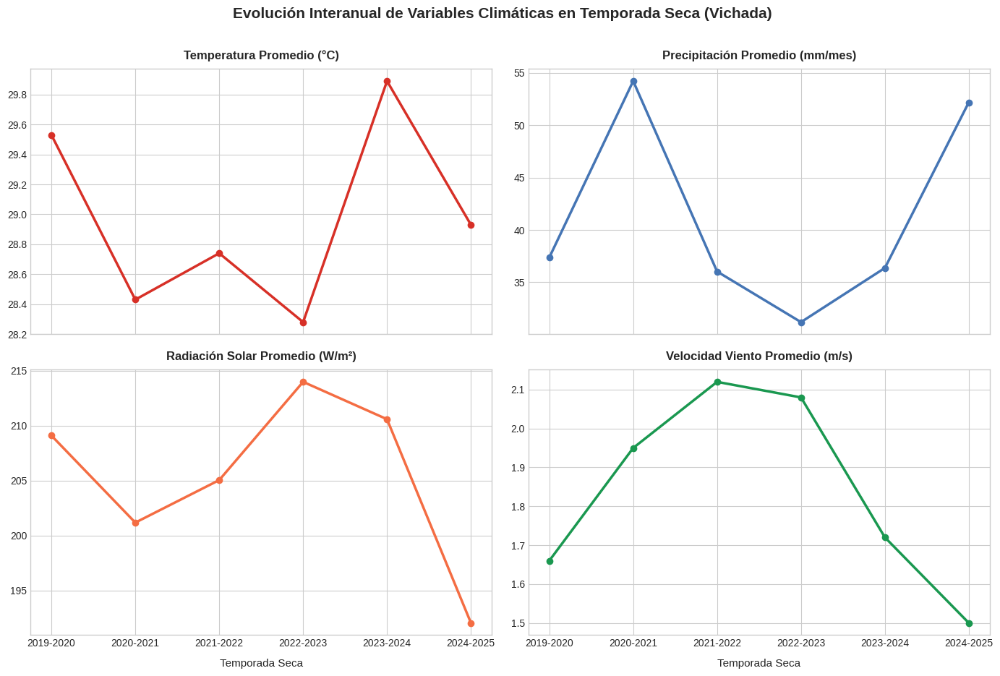

💾 Gráfica de balance exportada exitosamente en: /content/drive/MyDrive/tesismsif_assets/05_Dinamica_Temp-Prec_Vichada.png


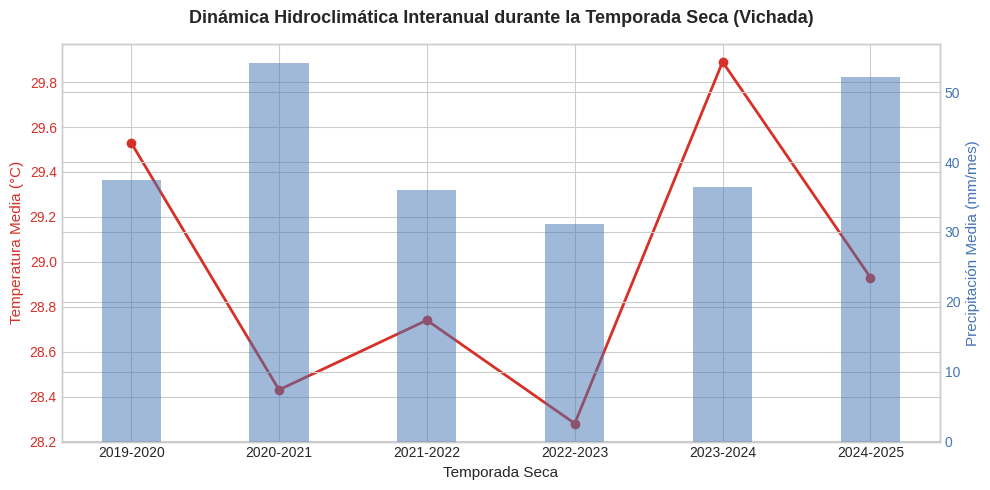

,Temporada Seca,Temp_Promedio (°C),Precipitacion (mm/mes),Rad_Solar (W/m2),Viento (m/s)
0,2019-2020,29.53,37.37,209.10,1.66
1,2020-2021,28.43,54.21,201.18,1.95
2,2021-2022,28.74,36.03,205.05,2.12
3,2022-2023,28.28,31.20,213.99,2.08
4,2023-2024,29.89,36.37,210.59,1.72
5,2024-2025,28.93,52.18,192.05,1.50


Map(center=[4.713319042058621, -69.41502683623392], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
# ==============================================================================
# TÍTULO: PROCESAMIENTO DE PREDICTORES CLIMÁTICOS (TERRACLIMATE)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Extracción, escalado, interpolación espacial (Downscaling a 30m)
#              y análisis estadístico interanual de variables climáticas.
# ==============================================================================

import ee
import geemap
import pandas as pd
import matplotlib.pyplot as plt
import os

def procesar_predictores_climaticos(coleccion_aoi, anios_estudio: list, ruta_assets: str, ruta_drive: str, crs_export: str = 'EPSG:32619'):
    """
    Genera tensores climáticos multitemporales para la temporada seca, aplicando
    factores de escala y remuestreo bilineal a 30m para coincidir con Landsat.
    """
    print("\n⏳ Inicializando procesamiento de variables predictoras climáticas...")
    geometria_dominio = coleccion_aoi.geometry()

    coleccion_terraclimate = ee.ImageCollection("IDAHO_EPSCOR/TERRACLIMATE")
    resultados_estadisticos = []

    # Lienzo cartográfico base
    mapa_clima = geemap.Map()
    mapa_clima.centerObject(geometria_dominio, zoom=7)
    mapa_clima.add_basemap('HYBRID')
    mapa_clima.addLayer(coleccion_aoi.style(fillColor='00000000', color='black', width=2), {}, 'Dominio (Vichada)', True)

    for anio_inicio in anios_estudio:
        anio_fin = anio_inicio + 1
        temporada = f"{anio_inicio}-{anio_fin}"

        fecha_inicio = ee.Date.fromYMD(anio_inicio, 12, 1)
        fecha_fin = ee.Date.fromYMD(anio_fin, 3, 31)

        print(f"   ├─ Procesando temporada {temporada}...")

        # 1. Extracción y Reducción Temporal (Media de la temporada seca)
        tc_temporada = coleccion_terraclimate.filterDate(fecha_inicio, fecha_fin).mean().clip(geometria_dominio)

        # 2. Álgebra de Mapas y Aplicación de Factores de Escala Físicos
        temp_media = tc_temporada.select('tmmx').add(tc_temporada.select('tmmn')).divide(2).multiply(0.1).rename('Temp_Promedio')
        precip_media = tc_temporada.select('pr').rename('Precipitacion')
        rad_media = tc_temporada.select('srad').multiply(0.1).rename('Rad_Solar')
        viento_media = tc_temporada.select('vs').multiply(0.01).rename('Velocidad_Viento')

        stack_nativo = ee.Image.cat([
            temp_media, precip_media, rad_media, viento_media
        ])

        # 3. Ensamblaje y Downscaling Espacial (Bilineal a 30m)
        stack_climatico = stack_nativo.resample('bilinear').reproject(crs=crs_export, scale=30)

        # 4. Extracción de Estadísticas Zonales (Se usa escala de 4000m para eficiencia)
        stats = stack_nativo.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometria_dominio,
            scale=1000,
            maxPixels=1e9
        ).getInfo()

        resultados_estadisticos.append({
            'Temporada Seca': temporada,
            'Temp_Promedio (°C)': round(stats.get('Temp_Promedio', 0), 2),
            'Precipitacion (mm/mes)': round(stats.get('Precipitacion', 0), 2),
            'Rad_Solar (W/m2)': round(stats.get('Rad_Solar', 0), 2),
            'Viento (m/s)': round(stats.get('Velocidad_Viento', 0), 2)
        })

        # 5. Programación de Exportaciones
        nombre_archivo = f"Stack_Clima_{temporada}_Vichada"
        asset_id = f"{ruta_assets}{nombre_archivo}"

        if not verificar_existencia_asset(asset_id):
            ee.batch.Export.image.toAsset(
                image=stack_climatico,
                description=f'Asset_{nombre_archivo}',
                assetId=asset_id,
                region=geometria_dominio.bounds(),
                scale=30,
                crs=crs_export,
                maxPixels=1e13
            ).start()

            ee.batch.Export.image.toDrive(
                image=stack_climatico,
                description=f'Drive_{nombre_archivo}',
                folder=ruta_drive,
                fileNamePrefix=nombre_archivo,
                region=geometria_dominio.bounds(),
                scale=30,
                crs=crs_export,
                maxPixels=1e13
            ).start()

        # Visualización de la última temporada en el iterador
        if anio_inicio == anios_estudio[-1]:
            mapa_clima.addLayer(stack_climatico.select('Temp_Promedio'), {'min': 26, 'max': 32, 'palette': ['#ffffcc', '#fd8d3c', '#e31a1c']}, f'Temp {temporada}', False)
            mapa_clima.addLayer(stack_climatico.select('Precipitacion'), {'min': 0, 'max': 100, 'palette': ['#ffffcc', '#41b6c4', '#225ea8']}, f'Precip {temporada}', False)
            mapa_clima.addLayer(stack_climatico.select('Rad_Solar'), {'min': 150, 'max': 250, 'palette': ['yellow', 'orange', 'red']}, f'Rad Solar {temporada}', False)
            mapa_clima.addLayer(stack_climatico.select('Velocidad_Viento'), {'min': 0.5, 'max': 3, 'palette': ['white', 'cyan', 'blue']}, f'Viento {temporada}', False)

    print("✅ Tareas de exportación climática enviadas. Consolidando estadísticas...")

    # 6. Procesamiento Estadístico Tabular
    df_clima = pd.DataFrame(resultados_estadisticos)

    # Exportación Tabular
    os.makedirs(f'/content/drive/MyDrive/{ruta_drive}', exist_ok=True)
    ruta_csv = f'/content/drive/MyDrive/{ruta_drive}/05_Estadisticas_Clima_Vichada.csv'
    df_clima.to_csv(ruta_csv, index=False)

    # 7. Gráfica Científica
    plt.style.use('seaborn-v0_8-whitegrid')
    ruta_base_drive = f'/content/drive/MyDrive/{ruta_drive}/'

    # --- GRÁFICA 1: MATRIZ COMPLETA DE VARIABLES CLIMÁTICAS (2x2) ---
    fig_matriz, axs = plt.subplots(2, 2, figsize=(14, 10), sharex=True)

    config_graficas = [
        ('Temp_Promedio (°C)', '#d73027', 0, 0, 'Temperatura Promedio (°C)'),
        ('Precipitacion (mm/mes)', '#4575b4', 0, 1, 'Precipitación Promedio (mm/mes)'),
        ('Rad_Solar (W/m2)', '#f46d43', 1, 0, 'Radiación Solar Promedio (W/m²)'),
        ('Viento (m/s)', '#1a9850', 1, 1, 'Velocidad Viento Promedio (m/s)')
    ]

    for columna, color, fila, col_idx, titulo in config_graficas:
        ax = axs[fila, col_idx]
        ax.plot(df_clima['Temporada Seca'], df_clima[columna], color=color, marker='o', linewidth=2.5, markersize=6)
        ax.set_title(titulo, fontsize=12, fontweight='bold', pad=10)
        ax.tick_params(axis='both', which='major', labelsize=10)
        if fila == 1:
            ax.set_xlabel('Temporada Seca', fontsize=11, labelpad=10)

    plt.suptitle('Evolución Interanual de Variables Climáticas en Temporada Seca (Vichada)', fontsize=15, fontweight='bold', y=0.96)
    fig_matriz.tight_layout(rect=[0, 0.03, 1, 0.95])

    ruta_fig_matriz = f'{ruta_base_drive}05_Dinamica_Clima_Vichada.png'
    fig_matriz.savefig(ruta_fig_matriz, dpi=600, bbox_inches='tight')
    print(f"💾 Gráfica de matriz exportada exitosamente en: {ruta_fig_matriz}")
    plt.show()

    # --- GRÁFICA 2: DOBLE EJE COMPARATIVO DE BALANCE HIDROCLIMÁTICO (TEMPERATURA VS PRECIPITACIÓN) ---
    fig_balance, ax1 = plt.subplots(figsize=(10, 5))

    color_temp = '#d73027'
    ax1.set_xlabel('Temporada Seca', fontsize=11)
    ax1.set_ylabel('Temperatura Media (°C)', color=color_temp, fontsize=11)
    ax1.plot(df_clima['Temporada Seca'], df_clima['Temp_Promedio (°C)'], color=color_temp, marker='o', linewidth=2)
    ax1.tick_params(axis='y', labelcolor=color_temp)

    ax2 = ax1.twinx()
    color_prec = '#4575b4'
    ax2.set_ylabel('Precipitación Media (mm/mes)', color=color_prec, fontsize=11)
    ax2.bar(df_clima['Temporada Seca'], df_clima['Precipitacion (mm/mes)'], color=color_prec, alpha=0.5, width=0.4)
    ax2.tick_params(axis='y', labelcolor=color_prec)

    plt.title('Dinámica Hidroclimática Interanual durante la Temporada Seca (Vichada)', fontsize=13, fontweight='bold', pad=15)
    fig_balance.tight_layout()

    ruta_fig_balance = f'{ruta_base_drive}05_Dinamica_Temp-Prec_Vichada.png'
    fig_balance.savefig(ruta_fig_balance, dpi=600, bbox_inches='tight')
    print(f"💾 Gráfica de balance exportada exitosamente en: {ruta_fig_balance}")
    plt.show()

    return df_clima, mapa_clima

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    ANIOS_ANALISIS = list(range(2019, 2025))
    RUTA_ASSETS = 'projects/tesismsif/assets/'
    RUTA_DRIVE = 'tesismsif_assets'
    CRS_PROYECTO = 'EPSG:32619' # UTM 19N (Vichada Oriental)

    # Se asume 'dominio_vichada' instanciado en Bloque 1
    df_clima_stats, mapa_clima_resultados = procesar_predictores_climaticos(
        coleccion_aoi=dominio_vichada,
        anios_estudio=ANIOS_ANALISIS,
        ruta_assets=RUTA_ASSETS,
        ruta_drive=RUTA_DRIVE,
        crs_export=CRS_PROYECTO
    )

    display(df_clima_stats)
    display(mapa_clima_resultados)

## 5.2.6 Auditoría y Adquisición del Catálogo Óptico Multi-plataforma

La estimación del estrés de la vegetación (estado hídrico del combustible) demanda observaciones espectrales continuas en los espectros visible, infrarrojo cercano (NIR) y de onda corta (SWIR). Para garantizar una cobertura espacial homogénea sobre la totalidad del departamento del Vichada, se optó por la integración sinérgica de las misiones espaciales Landsat 8 (Operational Land Imager) y Landsat 9 (OLI-2). El uso conjunto de ambas constelaciones reduce el tiempo de revisita ecuatorial de 16 a 8 días, mitigando significativamente la ausencia de datos provocada por la nubosidad tropical.

Se emplearon productos de Reflectancia en Superficie de la Colección 2, Nivel 2 (L2), los cuales se encuentran rigurosamente corregidos por efectos de dispersión atmosférica y gases absorbentes. Previo al cálculo de los tensores biofísicos, se implementó un proceso de filtrado lógico para restringir el universo de imágenes. La colección depurada ($C_L$) se define matemáticamente como:

$$C_L = \{ img \in (L8 \cup L9) \mid (t_{img} \in T_{seca}) \land (N_{img} < 80\%) \}$$

Donde $t_{img}$ corresponde a la fecha de adquisición de la imagen constreñida a los periodos de estiaje u ocurrencia de incendios ($T_{seca}$: diciembre a marzo), y $N_{img}$ representa el umbral de nubosidad total de la escena documentado en los metadatos del satélite (CLOUD_COVER), el cual se restringió a un límite máximo del 80% para evitar el procesamiento ineficiente de imágenes con ruido atmosférico irremediable. Esta auditoría permitió consolidar el inventario de escenas útiles sobre el dominio $\Omega$ antes de proceder a las técnicas de enmascaramiento por píxel.


⏳ Inicializando auditoría del catálogo Landsat 8 y 9...
   ├─ Descargando tabla de atributos (Este proceso puede tomar unos segundos)...
✅ Se han recuperado los metadatos de 523 escenas útiles.

--- RESUMEN ESTADÍSTICO DE DISPONIBILIDAD (QA) ---
Satelite
LANDSAT_8    317
LANDSAT_9    206

Descriptivos de Nubosidad General:
count    523.00
mean      31.92
std       25.05
min        0.00
25%        8.39
50%       29.03
75%       53.32
max       79.87

💾 Archivos de auditoría exportados en: /content/drive/MyDrive/tesismsif/assets


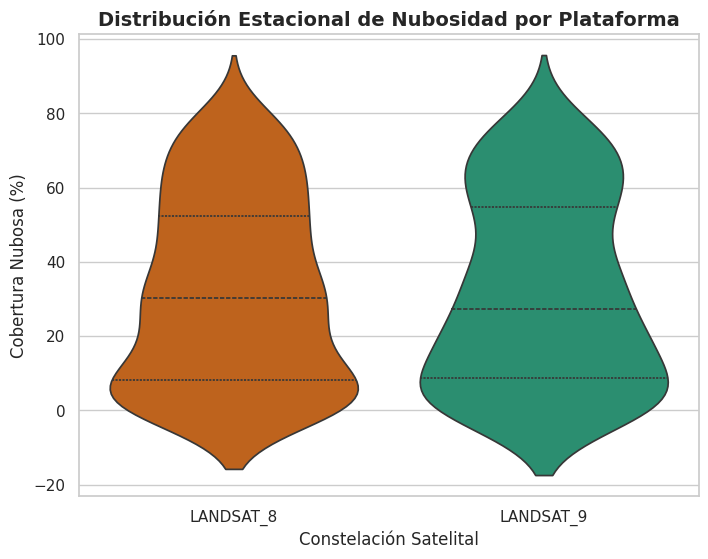

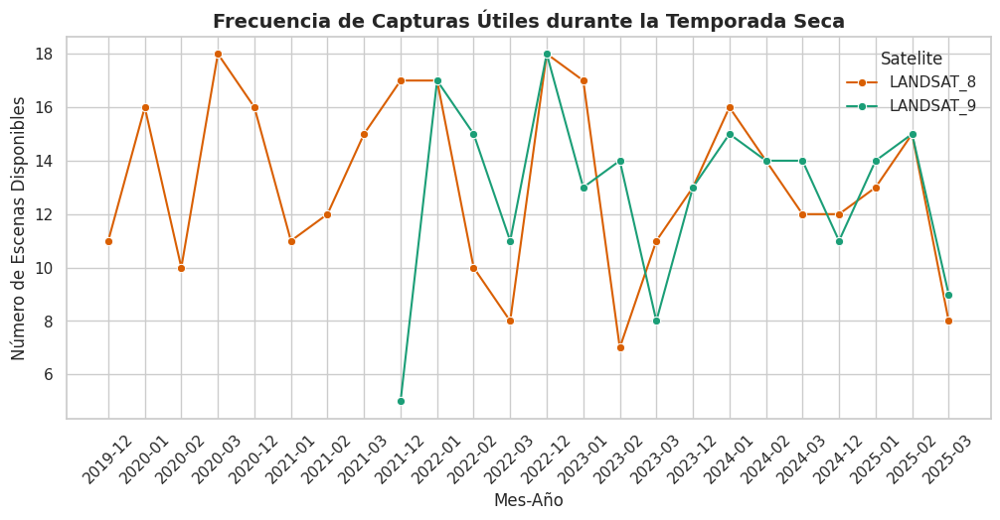

,Fecha,ID_Imagen,Nubosidad_pct,Satelite,Fecha_dt,Mes_Anio
0,2019-12-05,LC08_L2SP_004056_20191205_20200824_02_T1,18.27,LANDSAT_8,2019-12-05,2019-12
1,2020-01-06,LC08_L2SP_004056_20200106_20200823_02_T1,0.01,LANDSAT_8,2020-01-06,2020-01
2,2020-01-22,LC08_L2SP_004056_20200122_20200823_02_T1,2.51,LANDSAT_8,2020-01-22,2020-01
3,2020-02-07,LC08_L2SP_004056_20200207_20200823_02_T1,4.98,LANDSAT_8,2020-02-07,2020-02
4,2020-03-10,LC08_L2SP_004056_20200310_20200822_02_T1,59.83,LANDSAT_8,2020-03-10,2020-03


In [ ]:
# ==============================================================================
# TÍTULO: AUDITORÍA DE METADATOS Y DISPONIBILIDAD DE IMÁGENES LANDSAT 8 Y 9
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Extracción de metadatos de las colecciones OLI/TIRS (Nivel 2),
#              análisis de distribución de nubosidad y exportación de gráficos.
# ==============================================================================

import ee
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from google.colab import data_table

def explorar_metadatos_landsat(coleccion_aoi, fecha_inicio: str, fecha_fin: str, umbral_nubosidad: int, ruta_drive: str):
    """
    Filtra temporal y espacialmente las colecciones Landsat 8 y 9, extrae
    sus propiedades y genera un análisis estadístico-gráfico de calidad.
    """
    print("\n⏳ Inicializando auditoría del catálogo Landsat 8 y 9...")
    geometria_dominio = coleccion_aoi.geometry()

    # 1. Configuración de Filtros (Espacial, Temporal y de Calidad)
    filtro_estacional = ee.Filter.Or(
        ee.Filter.calendarRange(12, 12, 'month'),
        ee.Filter.calendarRange(1, 3, 'month')
    )

    def aplicar_filtros_base(coleccion):
        """Función interna para estandarizar el filtrado de ambas constelaciones."""
        return (coleccion
                .filterBounds(geometria_dominio)
                .filterDate(fecha_inicio, fecha_fin)
                .filter(ee.Filter.lt('CLOUD_COVER', umbral_nubosidad))
                .filter(filtro_estacional))

    # 2. Instanciación y Fusión de Colecciones (Nivel 2 - Superficie)
    l8_coleccion = aplicar_filtros_base(ee.ImageCollection('LANDSAT/LC08/C02/T1_L2'))
    l9_coleccion = aplicar_filtros_base(ee.ImageCollection('LANDSAT/LC09/C02/T1_L2'))

    coleccion_fusionada = l8_coleccion.merge(l9_coleccion)

    # 3. Extracción Funcional de Metadatos (Server-side a Client-side)
    def mapear_metadatos(imagen):
        return ee.Feature(None, {
            'Satelite': imagen.get('SPACECRAFT_ID'),
            'ID_Imagen': imagen.get('LANDSAT_PRODUCT_ID'),
            'Fecha': imagen.get('DATE_ACQUIRED'),
            'Nubosidad_pct': imagen.get('CLOUD_COVER')
        })

    print("   ├─ Descargando tabla de atributos (Este proceso puede tomar unos segundos)...")
    coleccion_metadatos = coleccion_fusionada.map(mapear_metadatos)

    try:
        lista_propiedades = coleccion_metadatos.getInfo()['features']
    except Exception as e:
        raise RuntimeError(f"❌ Error al extraer metadatos de GEE. La colección puede ser muy masiva: {e}")

    # 4. Procesamiento Tabular (Pandas)
    datos_extraidos = [feat['properties'] for feat in lista_propiedades]
    df_landsat = pd.DataFrame(datos_extraidos)

    if df_landsat.empty:
        print("⚠️ ADVERTENCIA: No se encontraron imágenes bajo los criterios especificados.")
        return df_landsat

    df_landsat['Fecha_dt'] = pd.to_datetime(df_landsat['Fecha'])
    df_landsat['Mes_Anio'] = df_landsat['Fecha_dt'].dt.to_period('M').astype(str)

    print(f"✅ Se han recuperado los metadatos de {len(df_landsat)} escenas útiles.")

    # 5. Visualización Científica y Exportación (Seaborn/Matplotlib)
    os.makedirs(ruta_drive, exist_ok=True)
    sns.set_theme(style="whitegrid", palette="muted")
    colores_sat = {"LANDSAT_8": "#d95f02", "LANDSAT_9": "#1b9e77"}

    # --- Figura A: Violín de Nubosidad ---
    fig_a, ax_a = plt.subplots(figsize=(8, 6))
    sns.violinplot(data=df_landsat, x="Satelite", y="Nubosidad_pct", palette=colores_sat, inner="quartile", ax=ax_a)
    ax_a.set_title("Distribución Estacional de Nubosidad por Plataforma", fontsize=14, fontweight='bold')
    ax_a.set_ylabel("Cobertura Nubosa (%)", fontsize=12)
    ax_a.set_xlabel("Constelación Satelital", fontsize=12)
    ruta_fig_a = os.path.join(ruta_drive, "06a_Violin_Nubosidad_Landsat.png")
    fig_a.savefig(ruta_fig_a, dpi=600, bbox_inches='tight', facecolor='white')

    # --- Figura B: Series de Tiempo Mensual ---
    fig_b, ax_b = plt.subplots(figsize=(12, 5))
    conteo_mensual = df_landsat.groupby(['Mes_Anio', 'Satelite']).size().reset_index(name='Conteo')
    sns.lineplot(data=conteo_mensual, x="Mes_Anio", y="Conteo", hue="Satelite", marker="o", palette=colores_sat, ax=ax_b)
    ax_b.set_title("Frecuencia de Capturas Útiles durante la Temporada Seca", fontsize=14, fontweight='bold')
    ax_b.set_ylabel("Número de Escenas Disponibles", fontsize=12)
    ax_b.set_xlabel("Mes-Año", fontsize=12)
    plt.xticks(rotation=45)
    ruta_fig_b = os.path.join(ruta_drive, "06b_SerieTiempo_Landsat.png")
    fig_b.savefig(ruta_fig_b, dpi=600, bbox_inches='tight', facecolor='white')

    # 6. Exportación Tabular y Reporte en Consola
    ruta_csv = os.path.join(ruta_drive, "06_Inventario_Metadatos_Landsat.csv")
    df_landsat.to_csv(ruta_csv, index=False)

    print("\n--- RESUMEN ESTADÍSTICO DE DISPONIBILIDAD (QA) ---")
    print(df_landsat['Satelite'].value_counts().to_string())
    print("\nDescriptivos de Nubosidad General:")
    print(df_landsat['Nubosidad_pct'].describe().round(2).to_string())
    print(f"\n💾 Archivos de auditoría exportados en: {ruta_drive}")

    plt.show()
    return df_landsat, coleccion_fusionada

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    # Parametrización centralizada (Se evita el uso de input() para reproducibilidad)
    FECHA_INICIO_ESTUDIO = '2019-12-01'
    FECHA_FIN_ESTUDIO = '2025-03-31'
    MAX_NUBOSIDAD_TOLERADA = 80 # Porcentaje máximo admitido por escena
    RUTA_DRIVE_EXPORT = '/content/drive/MyDrive/tesismsif/assets'

    # Activar formateador de tablas interactivas en Colab
    data_table.enable_dataframe_formatter()

    # Ejecución de la función
    df_metadatos, coleccion_fusionada = explorar_metadatos_landsat(
        coleccion_aoi=dominio_vichada,
        fecha_inicio=FECHA_INICIO_ESTUDIO,
        fecha_fin=FECHA_FIN_ESTUDIO,
        umbral_nubosidad=MAX_NUBOSIDAD_TOLERADA,
        ruta_drive=RUTA_DRIVE_EXPORT
    )

    display(df_metadatos.head())

## 5.2.7 Preprocesamiento Óptico: Composición Medoid e Índices Biofísicos

### Composición Temporal (Medoid)
Las características del combustible forestal, específicamente su carga de biomasa y su contenido de humedad, son determinantes absolutos en la susceptibilidad al fuego. Para capturar estas propiedades a escala de paisaje, se procesaron las colecciones Landsat 8 y 9 utilizando la técnica de composición multitemporal del **Medoide** (*Medoid*).

Para garantizar el suministro de tensores continuos (libres de nubes y sombras) requeridos por el algoritmo predictivo, se implementó una rutina de enmascaramiento basada en la banda de calidad `QA_PIXEL` de la Colección 2 Nivel 2 de Landsat. Posteriormente, debido a que la agregación temporal simple (como la mediana) puede crear píxeles sintéticos con firmas espectrales físicamente inexistentes, se empleó una aproximación multidimensional denominada **Medoid** (Flood, 2013). Esta técnica evalúa la distancia euclidiana de cada observación a la mediana espectral en un espacio de $n$ dimensiones (bandas reflectivas y térmicas), seleccionando el valor real observado ($V_i$) que minimiza la suma de las distancias al cuadrado:

$$Medoid_{(x,y)} = \text{argmin}_{V_i} \sum_{b=1}^{n} (V_{i,b} - M_b)^2$$

Donde $M_b$ es la mediana temporal para la banda $b$. Esto asegura que la fenología y la respuesta espectral de la vegetación en la Orinoquía conserven su coherencia física.

### Variables Predictoras Dinámicas (Espectrales)
Con el mosaico Medoid estabilizado, se calcularon cuatro índices espectrales que describen el estado biofísico de los combustibles forestales, considerándose proxies directos para las probabilidades de ignición (Chuvieco et al., 2004):

1. **Índice de Vegetación de Diferencia Normalizada (NDVI):** Mide el vigor fotosintético y aproxima la cantidad de biomasa verde.
$$NDVI = \frac{\rho_{NIR} - \rho_{Red}}{\rho_{NIR} + \rho_{Red}}$$

2. **Índice de Vegetación Mejorado (EVI):** Optimizado para áreas de alta densidad de biomasa y diseñado para resistir las influencias atmosféricas.
$$EVI = 2.5 \times \frac{\rho_{NIR} - \rho_{Red}}{\rho_{NIR} + 6\rho_{Red} - 7.5\rho_{Blue} + 1}$$

3. **Índice de Agua de Diferencia Normalizada (NDWI):** Cuantifica el contenido de humedad equivalente en el dosel de la vegetación, operando como un indicador directo de estrés hídrico (Gao, 1996).
$$NDWI = \frac{\rho_{NIR} - \rho_{SWIR1}}{\rho_{NIR} + \rho_{SWIR1}}$$

4. **Índice Resistente a la Atmósfera en el Visible (VARI):** Estima de manera robusta la fracción de vegetación utilizando únicamente el espectro visible, minimizando efectos de dispersión.
$$VARI = \frac{\rho_{Green} - \rho_{Red}}{\rho_{Green} + \rho_{Red} - \rho_{Blue}}$$

### Gap-Filling (Interpolación Espacial de Vacíos)
El proceso de enmascaramiento estricto genera micropérdidas de datos (*No-Data gaps*) que no son toleradas por los algoritmos de Machine Learning. Para preservar la matriz de muestras espaciales completa, se aplicó una técnica de *Gap-Filling* mediante una convolución de media focal continua ($f_{gap}$) en un vecindario ($K$) de radio mínimo ($W$):

$$f_{gap}(x,y) = \frac{1}{W} \sum_{i,j \in K} \rho(x_i, y_j)$$

El producto final exportado corresponde a tensores espaciales continuos de 11 dimensiones (Bandas e Índices) a 30 metros de resolución espacial, perfectamente acoplados para la integración en la matriz del modelo.

In [ ]:
# ==============================================================================
# TÍTULO: PREPROCESAMIENTO ÓPTICO, COMPOSICIÓN MEDOIDE E ÍNDICES ESPECTRALES
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Enmascaramiento QA, cálculo de distancias euclidianas para
#              composición medoide, derivación de índices y Gap-Filling focal.
# ==============================================================================

import ee
import geemap
import os

def procesar_tensor_espectral(coleccion_base, coleccion_aoi, anios_estudio: list, ruta_assets: str, ruta_drive: str, crs_export: str = 'EPSG:32619'):
    """
    Procesa la serie temporal Landsat para generar un tensor espectral continuo
    libre de nubes, calculando índices biofísicos y rellenando vacíos espaciales.
    """
    print("\n⏳ Inicializando arquitectura de procesamiento óptico (Landsat L2)...")
    geometria_dominio = coleccion_aoi.geometry()

    # Lista de bandas de interés
    bandas_in = ['SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7', 'ST_B10']
    bandas_out = ['Azul', 'Verde', 'Rojo', 'NIR', 'SWIR1', 'SWIR2', 'LST']

    # 1. FUNCIÓN DE CALIBRACIÓN RADIOMÉTRICA Y ENMASCARAMIENTO (QA_PIXEL)
    def aplicar_escala_y_mascara(imagen):
        """Aplica factores de escala físicos y enmascara nubes/sombras mediante bits."""
        # Factores multiplicativos y aditivos oficiales del USGS para Colección 2
        opticas = imagen.select('SR_B.').multiply(0.0000275).add(-0.2)
        termica = imagen.select('ST_B.*').multiply(0.00341802).add(149.0)
        img_escalada = imagen.addBands(opticas, None, True).addBands(termica, None, True)

        qa = img_escalada.select('QA_PIXEL')
        # Operaciones bit a bit: 1 (Nube dilatada), 2 (Cirrus), 3 (Nube), 4 (Sombra de nube)
        mascara = (qa.bitwiseAnd(1 << 1).eq(0)
                   .And(qa.bitwiseAnd(1 << 2).eq(0))
                   .And(qa.bitwiseAnd(1 << 3).eq(0))
                   .And(qa.bitwiseAnd(1 << 4).eq(0)))
        return img_escalada.updateMask(mascara)

    # 2. FUNCIÓN DE COMPOSICIÓN MULTITEMPORAL: EL MEDOIDE
    def calcular_compuesto_medoide(coleccion_filtrada):
        """Calcula el píxel real más representativo basado en distancia euclidiana a la mediana."""
        mediana = coleccion_filtrada.select(bandas_in).median()

        def calcular_distancia(img):
            # D = sqrt(sum((x - mediana)^2))
            distancia = (img.select(bandas_in)
                         .subtract(mediana)
                         .pow(2)
                         .reduce(ee.Reducer.sum())
                         .sqrt()
                         .multiply(-1) # Negativo porque qualityMosaic selecciona el valor máximo
                         .rename('distancia_medoide'))
            return img.addBands(distancia)

        return (coleccion_filtrada.map(calcular_distancia)
                .qualityMosaic('distancia_medoide')
                .select(bandas_in, bandas_out)) # Renombramiento semántico

    # 3. FUNCIÓN DE ÁLGEBRA ESPACIAL (ÍNDICES)
    def calcular_indices_biofisicos(imagen):
        """Calcula índices de vegetación y estrés hídrico."""
        ndvi = imagen.normalizedDifference(['NIR', 'Rojo']).rename('NDVI')
        ndwi = imagen.normalizedDifference(['NIR', 'SWIR1']).rename('NDWI') # NDMI / NDWI de Gao

        evi = imagen.expression(
            '2.5 * ((NIR - ROJO) / (NIR + 6 * ROJO - 7.5 * AZUL + 1))',
            {'NIR': imagen.select('NIR'), 'ROJO': imagen.select('Rojo'), 'AZUL': imagen.select('Azul')}
        ).rename('EVI')

        vari = imagen.expression(
            '(VERDE - ROJO) / (VERDE + ROJO - AZUL)',
            {'VERDE': imagen.select('Verde'), 'ROJO': imagen.select('Rojo'), 'AZUL': imagen.select('Azul')}
        ).rename('VARI')

        return imagen.addBands([ndvi, evi, ndwi, vari])

    # 4. FUNCIÓN DE GAP-FILLING (MEDIA FOCAL)
    def rellenar_vacios_espaciales(imagen):
        """Usa una ventana móvil (Convolución) para interpolar píxeles nulos aislados."""
        # Se calcula la media en un radio de 1.5 píxeles (~45m)
        media_focal = imagen.focal_mean(radius=1.5, kernelType='square', units='pixels')
        # Reemplaza los píxeles enmascarados con el valor de la media focal
        return imagen.unmask(media_focal).clip(geometria_dominio)

    # Configuración de lienzo interactivo para validar la última temporada
    mapa_espectral = geemap.Map()
    mapa_espectral.centerObject(geometria_dominio, zoom=7)
    mapa_espectral.add_basemap('HYBRID')
    mapa_espectral.addLayer(coleccion_aoi.style(fillColor='00000000', color='black', width=2), {}, 'Límite Vichada')
    lista_tensores = []

    # ITERACIÓN POR TEMPORADAS
    for anio_inicio in anios_estudio:
        anio_fin = anio_inicio + 1
        temporada = f"{anio_inicio}-{anio_fin}"
        print(f"   ├─ Procesando Tensores Espectrales para {temporada}...")

        fecha_inicio = ee.Date.fromYMD(anio_inicio, 12, 1)
        fecha_fin = ee.Date.fromYMD(anio_fin, 3, 31)

        # Flujo de Procesamiento Pipeline (Map -> Reduce -> Transform)
        coleccion_temporada = (coleccion_base
                               .filterBounds(geometria_dominio)
                               .filterDate(fecha_inicio, fecha_fin)
                               .map(aplicar_escala_y_mascara))

        medoide_base = calcular_compuesto_medoide(coleccion_temporada)
        imagen_con_indices = calcular_indices_biofisicos(medoide_base)

        # Agregamos .toFloat() para homogenizar los tipos de datos de las bandas antes de exportar
        tensor_final = rellenar_vacios_espaciales(imagen_con_indices).reproject(crs=crs_export, scale=30).toFloat()
        lista_tensores.append(tensor_final)

        # Programación de Exportación Consolidada
        nombre_archivo = f"Tensor_Espectral_{temporada}_Vichada"
        asset_id = f"{ruta_assets}{nombre_archivo}"

        if not verificar_existencia_asset(asset_id):
            # Exportar a GEE
            ee.batch.Export.image.toAsset(
                image=tensor_final,
                description=f"Asset_{nombre_archivo}",
                assetId=asset_id,
                region=geometria_dominio.bounds(),
                scale=30,
                crs=crs_export,
                maxPixels=1e13
            ).start()

            # Exportar a Drive
            ee.batch.Export.image.toDrive(
                image=tensor_final,
                description=f"Drive_{nombre_archivo}",
                folder=ruta_drive,
                fileNamePrefix=nombre_archivo,
                region=geometria_dominio.bounds(),
                scale=30,
                crs=crs_export,
                maxPixels=1e13
            ).start()
            print(f"   └─ ✅ Tareas de exportación (Tensor 11 bandas) enviadas para {temporada}.")
        else:
            print(f"   └─ ℹ️ El Asset '{asset_id}' ya existe. Se omite.")

        # Añadir al mapa solo la última temporada para auditoría visual
        if anio_inicio == anios_estudio[-1]:
            mapa_espectral.addLayer(tensor_final.select(['Rojo', 'Verde', 'Azul']), {'min': 0, 'max': 0.15}, f'Color Verdadero {temporada}', True)
            mapa_espectral.addLayer(tensor_final.select('NDVI'), {'min': -1, 'max': 1, 'palette': ['red', 'yellow', 'green']}, f'NDVI {temporada}', False)
            mapa_espectral.addLayer(tensor_final.select('NDWI'), {'min': -1, 'max': 1, 'palette': ['#a50026', '#ffffbf', '#313695']}, f'NDWI (Gao) {temporada}', False)
            mapa_espectral.addLayer(tensor_final.select('EVI'), {'min': -1, 'max': 1, 'palette': ['brown', 'yellow', 'darkgreen']}, f'EVI {temporada}', False)
            mapa_espectral.addLayer(tensor_final.select('VARI'), {'min': -1, 'max': 1, 'palette': ['red', 'yellow', 'green']}, f'VARI {temporada}', False)

    print("\n☑️ Preprocesamiento espectral finalizado. Revisa las tareas en GEE.")

    # Exportar HTML
    try:
        ruta_html = f'/content/drive/MyDrive/{ruta_drive}/07_Tensores_Espectrales.html'
        os.makedirs(os.path.dirname(ruta_html), exist_ok=True)
        mapa_espectral.to_html(filename=ruta_html, title='Tensores Espectrales - Vichada', width='100%', height='600px')
    except Exception as e:
        pass

    return mapa_espectral, lista_tensores

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    ANIOS_ANALISIS = list(range(2019, 2025))
    RUTA_ASSETS = 'projects/tesismsif/assets/'
    RUTA_DRIVE = 'tesismsif_assets'
    CRS_PROYECTO = 'EPSG:32619'

    # coleccion_fusionada fue creado en el bloque anterior 3.3a
    mapa_espectral_resultados, lista_tensores_final = procesar_tensor_espectral(
        coleccion_base=coleccion_fusionada,
        coleccion_aoi=dominio_vichada,
        anios_estudio=ANIOS_ANALISIS,
        ruta_assets=RUTA_ASSETS,
        ruta_drive=RUTA_DRIVE,
        crs_export=CRS_PROYECTO
    )

    display(mapa_espectral_resultados)



⏳ Inicializando arquitectura de procesamiento óptico (Landsat L2)...
   ├─ Procesando Tensores Espectrales para 2019-2020...
   └─ ℹ️ El Asset 'projects/tesismsif/assets/Tensor_Espectral_2019-2020_Vichada' ya existe. Se omite.
   ├─ Procesando Tensores Espectrales para 2020-2021...
   └─ ℹ️ El Asset 'projects/tesismsif/assets/Tensor_Espectral_2020-2021_Vichada' ya existe. Se omite.
   ├─ Procesando Tensores Espectrales para 2021-2022...
   └─ ℹ️ El Asset 'projects/tesismsif/assets/Tensor_Espectral_2021-2022_Vichada' ya existe. Se omite.
   ├─ Procesando Tensores Espectrales para 2022-2023...
   └─ ℹ️ El Asset 'projects/tesismsif/assets/Tensor_Espectral_2022-2023_Vichada' ya existe. Se omite.
   ├─ Procesando Tensores Espectrales para 2023-2024...
   └─ ℹ️ El Asset 'projects/tesismsif/assets/Tensor_Espectral_2023-2024_Vichada' ya existe. Se omite.
   ├─ Procesando Tensores Espectrales para 2024-2025...
   └─ ℹ️ El Asset 'projects/tesismsif/assets/Tensor_Espectral_2024-2025_Vichada' ya 

Map(center=[4.713319042058621, -69.41502683623392], controls=(WidgetControl(options=['position', 'transparent_…

## 5.2.8 Control de Calidad y Auditoría de Anomalías Espectrales

Antes de integrar las covariables espectrales a la matriz de entrenamiento del modelo de aprendizaje automático, se procedió a realizar una validación de rigurosidad estadística. Este escrutinio busca identificar ruido de coma flotante (*floating-point precision noise*), errores residuales del preprocesamiento atmosférico y anomalías matemáticas derivadas del método de *Gap-Filling*.

A nivel de hardware, los tensores radiométricos se procesan mediante operaciones de convolución matricial que ocasionalmente exceden los rangos físicos (Chuvieco, 2002). Para la validación algorítmica, se formalizaron dos ecuaciones indicadoras de anomalía ($\Phi$):

Para los índices biofísicos normalizados ($I$), cuyo rango teórico se restringe al intervalo $[-1, 1]$:
$$\Phi_{I}(x,y) = \begin{cases} 1, & \text{si } I(x,y) < -1 \lor I(x,y) > 1 \\ 0, & \text{en caso contrario} \end{cases}$$

Para las bandas de reflectancia en superficie ($\rho$), cuyo rango fisiológico válido corresponde a $[0, 1]$:
$$\Phi_{\rho}(x,y) = \begin{cases} 1, & \text{si } \rho(x,y) < 0 \lor \rho(x,y) > 1 \\ 0, & \text{en caso contrario} \end{cases}$$

Posteriormente, el porcentaje de ruido o valores fuera de rango ($\%_{Anomalías}$) para el dominio departamental del Vichada se calculó mediante una integración espacial:

$$ \%_{Anomalías} = \left( \frac{\sum_{i=1}^{N} \Phi(x_i,y_i)}{N_{válidos}} \right) \times 100 $$

Donde $N_{válidos}$ es el recuento total de píxeles no enmascarados de la escena. Debido al intenso requerimiento computacional de los reductores estadísticos (`ee.Reducer.stdDev()` y conteos globales a $30\text{ m}$), esta validación se ejecutó como "prueba de concepto" (*Proof of Concept*) sobre una temporada representativa (2019-2020), asumiendo la estabilidad del *pipeline* metodológico para las temporadas subsecuentes.

In [ ]:
# ==============================================================================
# TÍTULO: AUDITORÍA ESTADÍSTICA Y CONTROL DE ANOMALÍAS RADIOMÉTRICAS
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Verificación de consistencia física de las bandas reflectivas
#              e índices biofísicos para una temporada de prueba (2019-2020).
# ==============================================================================

import ee
import os

def calcular_anomalias_radiometricas(imagen, nombres_bandas, region, escala, es_indice):
    """
    Cuantifica el número y porcentaje de píxeles que exceden los límites
    físicos teóricos de reflectancia [0, 1] o índices biofísicos [-1, 1].
    """
    lista_anomalias = []

    for banda_nombre in nombres_bandas:
        banda = imagen.select(banda_nombre)
        # Lógica de anomalía: Índices fuera de [-1, 1] y Reflectancia fuera de [0, 1]
        if es_indice:
            anomalia = banda.lt(-1).Or(banda.gt(1)).rename(f'anomalo_{banda_nombre}')
        else:
            anomalia = banda.lt(0).Or(banda.gt(1)).rename(f'anomalo_{banda_nombre}')

        lista_anomalias.append(anomalia)

    # Imagen de análisis con la banda base para el conteo total de píxeles válidos
    img_analisis = ee.Image.cat(lista_anomalias).addBands(
        imagen.select([nombres_bandas[0]]).rename('total_validos')
    ).clipToBoundsAndScale(region.bounds())

    # Reductores combinados: Suma de anomalías y Conteo de píxeles totales
    reductores = ee.Reducer.sum().combine(reducer2=ee.Reducer.count(), sharedInputs=True)

    estadisticas = img_analisis.reduceRegion(
        reducer=reductores,
        geometry=region,
        scale=escala,
        maxPixels=1e13,
        tileScale=16  # tileScale alto para mitigar errores de memoria
    )

    diccionario_resultados = ee.Dictionary({})
    for banda_nombre in nombres_bandas:
        # Manejo de nulos (Evitar errores si no hay datos)
        suma_anomalos = ee.Number(ee.Algorithms.If(
            ee.Algorithms.IsEqual(estadisticas.get(f'anomalo_{banda_nombre}_sum'), None),
            0, estadisticas.get(f'anomalo_{banda_nombre}_sum')
        ))

        total_validos = ee.Number(ee.Algorithms.If(
            ee.Algorithms.IsEqual(estadisticas.get('total_validos_count'), None),
            0, estadisticas.get('total_validos_count')
        ))

        # Cálculo del porcentaje de ruido
        porcentaje = ee.Algorithms.If(
            total_validos.gt(0),
            suma_anomalos.divide(total_validos).multiply(100),
            0
        )

        diccionario_resultados = (diccionario_resultados
            .set(f'total_pixeles_{banda_nombre}', total_validos)
            .set(f'pixeles_fuera_rango_{banda_nombre}', suma_anomalos)
            .set(f'porcentaje_fuera_rango_{banda_nombre}', porcentaje))

    return diccionario_resultados

# ==============================================================================
# EJECUCIÓN DEL BLOQUE (PRUEBA DE TEMPORADA 2019-2020)
# ==============================================================================
if __name__ == "__main__":
    UMBRAL_NUBES_USADO = 80
    RUTA_ASSETS = 'projects/tesismsif/assets/'
    RUTA_DRIVE = 'tesismsif_assets'

    temporada = "2019-2020"
    estadisticasLista = []

    # Separación de bandas de reflectancia e índices (Variable finalImg del bloque anterior)
    bandas_reflectancia = ['Azul', 'Verde', 'Rojo', 'NIR', 'SWIR1', 'SWIR2']
    bandas_indices = ['NDVI', 'EVI', 'NDWI', 'VARI']

    # Para evitar errores por variables faltantes, obtenemos el dominio_vichada y su centroide
    vichada_depto = dominio_vichada.geometry()
    centroide_vichada = vichada_depto.centroid(maxError=1)

    print(f"\n⏳ Ejecutando auditoría estadística para la Temporada {temporada}...")

    # Cargar la imagen procesada desde la lista exportada en el bloque anterior
    finalImg = ee.Image(lista_tensores_final[0])

    img_reflectancia = finalImg.select(
        bandas_reflectancia
    )
    img_indices = finalImg.select(bandas_indices)

    # Reductores estadísticos completos
    reductores_completos = (ee.Reducer.mean()
                            .combine(reducer2=ee.Reducer.median(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.min(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.max(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.stdDev(), sharedInputs=True))

    # Ejecución de reductores espaciales
    stats_indices = img_indices.reduceRegion(reducer=reductores_completos, geometry=vichada_depto, scale=30, maxPixels=1e13, tileScale=16)
    stats_reflectancia = img_reflectancia.reduceRegion(reducer=ee.Reducer.minMax(), geometry=vichada_depto, scale=30, maxPixels=1e13, tileScale=16)

    # Análisis de Anomalías
    anomalias_rad = calcular_anomalias_radiometricas(img_reflectancia, bandas_reflectancia, vichada_depto, 30, False)
    anomalias_idx = calcular_anomalias_radiometricas(img_indices, bandas_indices, vichada_depto, 30, True)

    # Empaquetado en Feature (Atributos tabulares)
    metadatos_auditoria = ee.Feature(centroide_vichada, {
        'image_id': f'Medoid_{temporada}',
        'porcentaje_nubosidad': f'Filtro_{UMBRAL_NUBES_USADO}%'
    })
    estadisticasLista.append(metadatos_auditoria
                           .setMulti(stats_indices)
                           .setMulti(stats_reflectancia)
                           .setMulti(anomalias_idx)
                           .setMulti(anomalias_rad))

    print(f"✅ Auditoría finalizada exitosamente.")


⏳ Ejecutando auditoría estadística para la Temporada 2019-2020...
✅ Auditoría finalizada exitosamente.


In [ ]:
# ==============================================================================
# EJECUCIÓN DEL BLOQUE (PRUEBA DE TEMPORADA 2019-2020)
# ==============================================================================
if __name__ == "__main__":

    temporada = "2020-2021"

    print(f"\n⏳ Ejecutando auditoría estadística para la Temporada {temporada}...")

    # Cargar la imagen procesada desde la lista exportada en el bloque anterior
    finalImg = ee.Image(lista_tensores_final[1])

    img_reflectancia = finalImg.select(
        bandas_reflectancia
    )
    img_indices = finalImg.select(bandas_indices)

    # Reductores estadísticos completos
    reductores_completos = (ee.Reducer.mean()
                            .combine(reducer2=ee.Reducer.median(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.min(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.max(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.stdDev(), sharedInputs=True))

    # Ejecución de reductores espaciales
    stats_indices = img_indices.reduceRegion(reducer=reductores_completos, geometry=vichada_depto, scale=30, maxPixels=1e13, tileScale=16)
    stats_reflectancia = img_reflectancia.reduceRegion(reducer=ee.Reducer.minMax(), geometry=vichada_depto, scale=30, maxPixels=1e13, tileScale=16)

    # Análisis de Anomalías
    anomalias_rad = calcular_anomalias_radiometricas(img_reflectancia, bandas_reflectancia, vichada_depto, 30, False)
    anomalias_idx = calcular_anomalias_radiometricas(img_indices, bandas_indices, vichada_depto, 30, True)

    # Empaquetado en Feature (Atributos tabulares)
    metadatos_auditoria = ee.Feature(centroide_vichada, {
        'image_id': f'Medoid_{temporada}',
        'porcentaje_nubosidad': f'Filtro_{UMBRAL_NUBES_USADO}%'
    })
    estadisticasLista.append(metadatos_auditoria
                           .setMulti(stats_indices)
                           .setMulti(stats_reflectancia)
                           .setMulti(anomalias_idx)
                           .setMulti(anomalias_rad))

    print(f"✅ Auditoría finalizada exitosamente.")


⏳ Ejecutando auditoría estadística para la Temporada 2020-2021...
✅ Auditoría finalizada exitosamente.


In [ ]:
# ==============================================================================
# EJECUCIÓN DEL BLOQUE (PRUEBA DE TEMPORADA 2019-2020)
# ==============================================================================
if __name__ == "__main__":

    temporada = "2021-2022"

    print(f"\n⏳ Ejecutando auditoría estadística para la Temporada {temporada}...")

    # Cargar la imagen procesada desde la lista exportada en el bloque anterior
    finalImg = ee.Image(lista_tensores_final[2])

    img_reflectancia = finalImg.select(
        bandas_reflectancia
    )
    img_indices = finalImg.select(bandas_indices)

    # Reductores estadísticos completos
    reductores_completos = (ee.Reducer.mean()
                            .combine(reducer2=ee.Reducer.median(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.min(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.max(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.stdDev(), sharedInputs=True))

    # Ejecución de reductores espaciales
    stats_indices = img_indices.reduceRegion(reducer=reductores_completos, geometry=vichada_depto, scale=30, maxPixels=1e13, tileScale=16)
    stats_reflectancia = img_reflectancia.reduceRegion(reducer=ee.Reducer.minMax(), geometry=vichada_depto, scale=30, maxPixels=1e13, tileScale=16)

    # Análisis de Anomalías
    anomalias_rad = calcular_anomalias_radiometricas(img_reflectancia, bandas_reflectancia, vichada_depto, 30, False)
    anomalias_idx = calcular_anomalias_radiometricas(img_indices, bandas_indices, vichada_depto, 30, True)

    # Empaquetado en Feature (Atributos tabulares)
    metadatos_auditoria = ee.Feature(centroide_vichada, {
        'image_id': f'Medoid_{temporada}',
        'porcentaje_nubosidad': f'Filtro_{UMBRAL_NUBES_USADO}%'
    })
    estadisticasLista.append(metadatos_auditoria
                           .setMulti(stats_indices)
                           .setMulti(stats_reflectancia)
                           .setMulti(anomalias_idx)
                           .setMulti(anomalias_rad))

    print(f"✅ Auditoría finalizada exitosamente.")


⏳ Ejecutando auditoría estadística para la Temporada 2021-2022...
✅ Auditoría finalizada exitosamente.


In [ ]:
# ==============================================================================
# EJECUCIÓN DEL BLOQUE (PRUEBA DE TEMPORADA 2019-2020)
# ==============================================================================
if __name__ == "__main__":

    temporada = "2022-2023"

    print(f"\n⏳ Ejecutando auditoría estadística para la Temporada {temporada}...")

    # Cargar la imagen procesada desde la lista exportada en el bloque anterior
    finalImg = ee.Image(lista_tensores_final[3])

    img_reflectancia = finalImg.select(
        bandas_reflectancia
    )
    img_indices = finalImg.select(bandas_indices)

    # Reductores estadísticos completos
    reductores_completos = (ee.Reducer.mean()
                            .combine(reducer2=ee.Reducer.median(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.min(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.max(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.stdDev(), sharedInputs=True))

    # Ejecución de reductores espaciales
    stats_indices = img_indices.reduceRegion(reducer=reductores_completos, geometry=vichada_depto, scale=30, maxPixels=1e13, tileScale=16)
    stats_reflectancia = img_reflectancia.reduceRegion(reducer=ee.Reducer.minMax(), geometry=vichada_depto, scale=30, maxPixels=1e13, tileScale=16)

    # Análisis de Anomalías
    anomalias_rad = calcular_anomalias_radiometricas(img_reflectancia, bandas_reflectancia, vichada_depto, 30, False)
    anomalias_idx = calcular_anomalias_radiometricas(img_indices, bandas_indices, vichada_depto, 30, True)

    # Empaquetado en Feature (Atributos tabulares)
    metadatos_auditoria = ee.Feature(centroide_vichada, {
        'image_id': f'Medoid_{temporada}',
        'porcentaje_nubosidad': f'Filtro_{UMBRAL_NUBES_USADO}%'
    })
    estadisticasLista.append(metadatos_auditoria
                           .setMulti(stats_indices)
                           .setMulti(stats_reflectancia)
                           .setMulti(anomalias_idx)
                           .setMulti(anomalias_rad))

    print(f"✅ Auditoría finalizada exitosamente.")


⏳ Ejecutando auditoría estadística para la Temporada 2022-2023...
✅ Auditoría finalizada exitosamente.


In [ ]:
# ==============================================================================
# EJECUCIÓN DEL BLOQUE (PRUEBA DE TEMPORADA 2019-2020)
# ==============================================================================
if __name__ == "__main__":

    temporada = "2023-2024"

    print(f"\n⏳ Ejecutando auditoría estadística para la Temporada {temporada}...")

    # Cargar la imagen procesada desde la lista exportada en el bloque anterior
    finalImg = ee.Image(lista_tensores_final[4])

    img_reflectancia = finalImg.select(
        bandas_reflectancia
    )
    img_indices = finalImg.select(bandas_indices)

    # Reductores estadísticos completos
    reductores_completos = (ee.Reducer.mean()
                            .combine(reducer2=ee.Reducer.median(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.min(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.max(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.stdDev(), sharedInputs=True))

    # Ejecución de reductores espaciales
    stats_indices = img_indices.reduceRegion(reducer=reductores_completos, geometry=vichada_depto, scale=30, maxPixels=1e13, tileScale=16)
    stats_reflectancia = img_reflectancia.reduceRegion(reducer=ee.Reducer.minMax(), geometry=vichada_depto, scale=30, maxPixels=1e13, tileScale=16)

    # Análisis de Anomalías
    anomalias_rad = calcular_anomalias_radiometricas(img_reflectancia, bandas_reflectancia, vichada_depto, 30, False)
    anomalias_idx = calcular_anomalias_radiometricas(img_indices, bandas_indices, vichada_depto, 30, True)

    # Empaquetado en Feature (Atributos tabulares)
    metadatos_auditoria = ee.Feature(centroide_vichada, {
        'image_id': f'Medoid_{temporada}',
        'porcentaje_nubosidad': f'Filtro_{UMBRAL_NUBES_USADO}%'
    })
    estadisticasLista.append(metadatos_auditoria
                           .setMulti(stats_indices)
                           .setMulti(stats_reflectancia)
                           .setMulti(anomalias_idx)
                           .setMulti(anomalias_rad))

    print(f"✅ Auditoría finalizada exitosamente.")


⏳ Ejecutando auditoría estadística para la Temporada 2023-2024...
✅ Auditoría finalizada exitosamente.


In [ ]:
# ==============================================================================
# EJECUCIÓN DEL BLOQUE (PRUEBA DE TEMPORADA 2019-2020)
# ==============================================================================
if __name__ == "__main__":

    temporada = "2024-2025"

    print(f"\n⏳ Ejecutando auditoría estadística para la Temporada {temporada}...")

    # Cargar la imagen procesada desde la lista exportada en el bloque anterior
    finalImg = ee.Image(lista_tensores_final[5])

    img_reflectancia = finalImg.select(
        bandas_reflectancia
    )
    img_indices = finalImg.select(bandas_indices)

    # Reductores estadísticos completos
    reductores_completos = (ee.Reducer.mean()
                            .combine(reducer2=ee.Reducer.median(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.min(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.max(), sharedInputs=True)
                            .combine(reducer2=ee.Reducer.stdDev(), sharedInputs=True))

    # Ejecución de reductores espaciales
    stats_indices = img_indices.reduceRegion(reducer=reductores_completos, geometry=vichada_depto, scale=30, maxPixels=1e13, tileScale=16)
    stats_reflectancia = img_reflectancia.reduceRegion(reducer=ee.Reducer.minMax(), geometry=vichada_depto, scale=30, maxPixels=1e13, tileScale=16)

    # Análisis de Anomalías
    anomalias_rad = calcular_anomalias_radiometricas(img_reflectancia, bandas_reflectancia, vichada_depto, 30, False)
    anomalias_idx = calcular_anomalias_radiometricas(img_indices, bandas_indices, vichada_depto, 30, True)

    # Empaquetado en Feature (Atributos tabulares)
    metadatos_auditoria = ee.Feature(centroide_vichada, {
        'image_id': f'Medoid_{temporada}',
        'porcentaje_nubosidad': f'Filtro_{UMBRAL_NUBES_USADO}%'
    })
    estadisticasLista.append(metadatos_auditoria
                           .setMulti(stats_indices)
                           .setMulti(stats_reflectancia)
                           .setMulti(anomalias_idx)
                           .setMulti(anomalias_rad))

    print(f"✅ Auditoría finalizada exitosamente.")

    coleccion_auditoria = ee.FeatureCollection(estadisticasLista)

    print(f"\n⏳ Programando exportaciones de la auditoría (Assets y Drive)...")

    nombre_archivo = f"Stats_Medoids_30m"
    asset_id = f"{RUTA_ASSETS}{nombre_archivo}"

    if not verificar_existencia_asset(asset_id):
        # 1. Exportación a GEE Assets
        ee.batch.Export.table.toAsset(
            collection=coleccion_auditoria,
            description=f'Asset_{nombre_archivo}',
            assetId=asset_id
        ).start()

        # 2. Exportación simultánea a Google Drive (CSV)
        ee.batch.Export.table.toDrive(
            collection=coleccion_auditoria,
            description=f'Drive_{nombre_archivo}',
            folder=RUTA_DRIVE,
            fileNamePrefix=nombre_archivo,
            fileFormat='CSV'
        ).start()

        print("\n✅ Tareas de exportación tabular enviadas a Google Earth Engine.")
    else:
        print(f"ℹ️ El Asset '{asset_id}' ya existe. Exportación omitida.")


⏳ Ejecutando auditoría estadística para la Temporada 2024-2025...
✅ Auditoría finalizada exitosamente.

⏳ Programando exportaciones de la auditoría (Assets y Drive)...
ℹ️ El Asset 'projects/tesismsif/assets/Stats_Medoids_30m' ya existe. Exportación omitida.


## 5.2.9 Análisis Diagnóstico del Preprocesamiento Óptico

Las arquitecturas de computación distribuida, como *Google Earth Engine*, operan bajo arquitecturas de precisión de coma flotante (*floating-point algebra*) para los cálculos de reflectancia y álgebra de bandas. Esto introduce un margen de error infinitesimal que puede provocar que valores físicos estrictos, como los límites teóricos del NDVI en $[-1, 1]$, reporten valores computacionales marginalmente fuera del rango (e.g., $1.000001$).

Para discriminar matemáticamente entre una anomalía física real (como saturación del sensor en bancos de arena altamente reflectivos o cuerpos de agua con alta carga de sedimentos) y el simple ruido de precisión algorítmica de la CPU, se introdujo una constante de tolerancia denominada Epsilon ($\epsilon$). La evaluación condicional final para aprobar la integridad radiométrica de cada variable $v_i$ se redefinió como:

$$ L_{inf} - \epsilon \le v_i \le L_{sup} + \epsilon $$

Donde $L_{inf}$ y $L_{sup}$ corresponden a los límites teóricos inferiores y superiores de cada banda o índice (ej. $L_{inf}=-1$ y $L_{sup}=1$ para índices normalizados de Tucker (1979)), y $\epsilon$ se estableció conservadoramente en $1 \times 10^{-4}$.

La superación de este control de calidad garantiza la mitigación de la propagación de errores lógicos hacia el algoritmo de ensamblaje predictivo (*Random Forest Regressor*), certificando que la varianza documentada en los índices de estrés hídrico y biomasa corresponde exclusivamente a gradientes ecológicos válidos en el paisaje de la Orinoquía.

In [ ]:
# ==============================================================================
# TÍTULO: GENERACIÓN DE REPORTE DIAGNÓSTICO DE CALIDAD ESPECTRAL
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Descarga de métricas de GEE, evaluación de límites físicos
#              (implementando tolerancia Epsilon) y exportación de reporte.
# ==============================================================================

import ee
import geemap
import pandas as pd
import os
import sys

def auditar_calidad_espectral(id_asset_stats: str, ruta_drive_reporte: str, tolerancia_epsilon: float = 1e-4):
    """
    Evalúa la coherencia radiométrica de las estadísticas zonales, aislando
    el ruido de coma flotante y exportando un log de auditoría continuo.
    """
    print(f"\n⏳ Descargando tabla estadística desde la nube...")

    try:
        # Carga del Asset y conversión directa a DataFrame de Pandas
        coleccion_auditoria = ee.FeatureCollection(id_asset_stats).sort('image_id')
        df_stats = geemap.ee_to_df(coleccion_auditoria)
    except Exception as e:
        raise RuntimeError(f"❌ Error de descarga. Verifique que la tarea previa de GEE haya finalizado exitosamente. Detalles: {e}")

    bandas_rad = ['Azul', 'Verde', 'Rojo', 'NIR', 'SWIR1', 'SWIR2']
    bandas_idx = ['NDVI', 'EVI', 'NDWI', 'VARI']

    # Preparar el directorio en Google Drive
    os.makedirs(os.path.dirname(ruta_drive_reporte), exist_ok=True)

    # Clase auxiliar para bifurcar el flujo de impresión (Consola + Archivo TXT)
    class CapturadorLog(object):
        def __init__(self, filename):
            self.terminal = sys.stdout
            self.log = open(filename, "w", encoding="utf-8")

        def write(self, message):
            self.terminal.write(message)
            self.log.write(message)

        def flush(self):
            self.terminal.flush()
            self.log.flush()

    # Redireccionamiento de la salida estándar (stdout)
    stdout_original = sys.stdout
    sys.stdout = CapturadorLog(ruta_drive_reporte)

    print("===============================================================================")
    print("                 REPORTE DE AUDITORÍA DE CALIDAD ESPECTRAL                     ")
    print("===============================================================================\n")

    for index, row in df_stats.iterrows():
        temporada = row['image_id'].replace('Medoid_', '')
        alertas_rad, alertas_idx = [], []

        print(f"================ ESTADÍSTICAS Y QC - TEMPORADA {temporada} ================")

        # ---------------------------------------------------------
        # QC RADIOMÉTRICO (Reflectancia de Superficie)
        # ---------------------------------------------------------
        print("--- BANDAS RADIOMÉTRICAS ---")
        for b in bandas_rad:
            min_v = row.get(f'{b}_min')
            max_v = row.get(f'{b}_max')
            tot_px = row.get(f'total_pixeles_{b}')
            conteo_anom = row.get(f'pixeles_fuera_rango_{b}')
            pct_anom = row.get(f'porcentaje_fuera_rango_{b}')

            if pd.notna(min_v) and pd.notna(max_v):
                print(f"[{b:^5}] Min: {min_v: .3f} | Max: {max_v: .3f} | Total px: {int(tot_px)} | Anómalos: {int(conteo_anom)} ({pct_anom:.4f}%)")

            # Evaluación lógica con margen de tolerancia (Epsilon)
            if pd.isna(min_v) or pd.isna(max_v):
                alertas_rad.append(f"{b} (Datos nulos)")
            elif min_v < (0 - tolerancia_epsilon) or max_v > (1 + tolerancia_epsilon):
                texto_anom = f"{int(conteo_anom)} px anómalos" if conteo_anom > 0 else "< 1 px (Ruido float)"
                alertas_rad.append(f"{b} ({texto_anom})")

        if alertas_rad:
            print(f"⚠️ ALERTA RADIOMÉTRICA: Valores fuera del límite en -> {' || '.join(alertas_rad)}")
        else:
            print("✅ QC RADIOMÉTRICO SUPERADO: Límites físicos conservados [0, 1]")

        # ---------------------------------------------------------
        # QC ESPECTRAL (Índices Biofísicos Normalizados)
        # ---------------------------------------------------------
        print("\n--- ÍNDICES ESPECTRALES ---")
        for idx in bandas_idx:
            min_v = row.get(f'{idx}_min')
            max_v = row.get(f'{idx}_max')
            mean_v = row.get(f'{idx}_mean')
            med_v = row.get(f'{idx}_median')
            std_v = row.get(f'{idx}_stdDev')
            tot_px = row.get(f'total_pixeles_{idx}')
            conteo_anom = row.get(f'pixeles_fuera_rango_{idx}')
            pct_anom = row.get(f'porcentaje_fuera_rango_{idx}')

            if pd.notna(min_v) and pd.notna(mean_v):
                print(f"[{idx:^4}] Media: {mean_v: .3f} | Mediana: {med_v: .3f} | StdDev: {std_v: .3f}")
                print(f"      Min: {min_v: .3f} | Max: {max_v: .3f} | Total px: {int(tot_px)} | Anómalos: {int(conteo_anom)} ({pct_anom:.4f}%)")

            # Evaluación lógica con margen de tolerancia (Epsilon)
            if pd.isna(min_v) or pd.isna(max_v):
                alertas_idx.append(f"{idx} (Datos nulos)")
            elif min_v < (-1 - tolerancia_epsilon) or max_v > (1 + tolerancia_epsilon):
                texto_anom = f"{int(conteo_anom)} px anómalos" if conteo_anom > 0 else "< 1 px (Ruido float)"
                alertas_idx.append(f"{idx} ({texto_anom})")

        if alertas_idx:
            print(f"🚨 ALERTA ESPECTRAL: Valores fuera del límite en -> {' || '.join(alertas_idx)}")
        else:
            print("✅ QC ESPECTRAL SUPERADO: Límites teóricos conservados [-1, 1]")
        print("\n")

    # Restaurar la salida original al finalizar
    sys.stdout = stdout_original
    print(f"💾 Reporte de auditoría guardado exitosamente en: {ruta_drive_reporte}")

    return df_stats

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    # La temporada procesada en el bloque anterior fue 2019-2020
    ID_ASSET_AUDITORIA = 'projects/tesismsif/assets/Stats_Medoids_30m'
    RUTA_TXT_DRIVE = '/content/drive/MyDrive/tesismsif_assets/08_Reporte_Auditoria_QC_Espectral.txt'

    df_resultados_auditoria = auditar_calidad_espectral(
        id_asset_stats=ID_ASSET_AUDITORIA,
        ruta_drive_reporte=RUTA_TXT_DRIVE,
        tolerancia_epsilon=1e-4  # Tolerancia algorítmica para GEE
    )



⏳ Descargando tabla estadística desde la nube...
                 REPORTE DE AUDITORÍA DE CALIDAD ESPECTRAL                     

================ ESTADÍSTICAS Y QC - TEMPORADA 2019-2020 ================
--- BANDAS RADIOMÉTRICAS ---
[Azul ] Min: -0.199 | Max:  0.594 | Total px: 110395207 | Anómalos: 24293 (0.0220%)
[Verde] Min: -0.161 | Max:  0.606 | Total px: 110395207 | Anómalos: 780 (0.0007%)
[Rojo ] Min: -0.134 | Max:  0.623 | Total px: 110395207 | Anómalos: 1759 (0.0016%)
[ NIR ] Min: -0.068 | Max:  0.736 | Total px: 110395207 | Anómalos: 1464 (0.0013%)
[SWIR1] Min: -0.023 | Max:  1.234 | Total px: 110395207 | Anómalos: 826 (0.0007%)
[SWIR2] Min: -0.021 | Max:  1.600 | Total px: 110395207 | Anómalos: 704 (0.0006%)
⚠️ ALERTA RADIOMÉTRICA: Valores fuera del límite en -> Azul (24293 px anómalos) || Verde (780 px anómalos) || Rojo (1759 px anómalos) || NIR (1464 px anómalos) || SWIR1 (826 px anómalos) || SWIR2 (704 px anómalos)

--- ÍNDICES ESPECTRALES ---
[NDVI] Media:  0.653 | Medi

## 5.2.10 Análisis Exploratorio de Datos (EDA): Distribución de Covariables Espectrales

Previo a la ingesta de las covariables espectrales en el algoritmo de *Machine Learning*, resulta imperativo diagnosticar el comportamiento estadístico del ecosistema durante las temporadas de estiaje. Para ello, se aplicó un Análisis Exploratorio de Datos (EDA) extrayendo una muestra espacial aleatoria uniforme ($N=5000$ píxeles) sobre el tensor espectral del dominio departamental ($\Omega$).

Para cada variable biofísica e índice de reflectancia, se analizaron los momentos estadísticos de tendencia central y dispersión de la muestra, contrastando la media aritmética ($\mu$) frente a la mediana ($\tilde{x}$) para identificar asimetrías distribucionales. Adicionalmente, se modeló la densidad empírica de los datos (KDE) y se acotó la varianza mediante la desviación estándar muestral ($\sigma$):

$$\sigma = \sqrt{\frac{1}{N-1} \sum_{i=1}^{N} (x_i - \mu)^2}$$

La visualización de estas distribuciones (Histogramas) es fundamental para el diseño metodológico. En ciencias geomáticas, variables como el Índice de Vegetación de Diferencia Normalizada (NDVI) o la reflectancia en el Infrarrojo de Onda Corta (SWIR) a menudo exhiben distribuciones no gaussianas (ej. distribuciones bimodales o fuertemente sesgadas) debido a la transición abrupta entre las coberturas de bosque de galería y las sabanas herbáceas fuertemente desecadas.

La comprobación de esta no-normalidad en las covariables del Vichada justifica sólidamente la elección de algoritmos predictivos no paramétricos, tales como el *Random Forest Regressor* (RFR), los cuales son invariantes a la escala y no asumen distribuciones gaussianas *a priori* en el espacio de características (James et al., 2013).


⏳ Inicializando Análisis Exploratorio de Datos (EDA) espectral...
   ├─ Extrayendo muestra espacial (N=5000) para la temporada 2019-2020...
   ├─ Renderizando gráficos de distribución estadística...


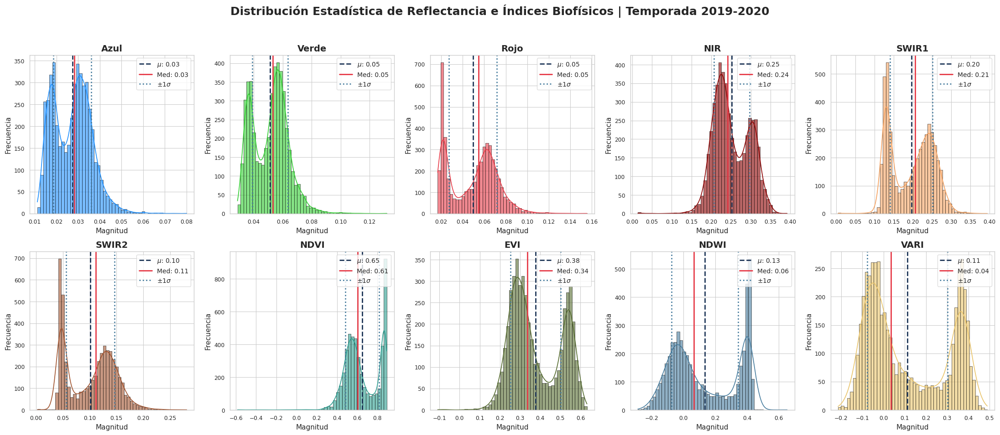

   └─ ✅ Figura exportada exitosamente: /content/drive/MyDrive/tesismsif_assets/09_Histogramas_Espectrales_2019-2020.png
   ├─ Extrayendo muestra espacial (N=5000) para la temporada 2020-2021...
   ├─ Renderizando gráficos de distribución estadística...


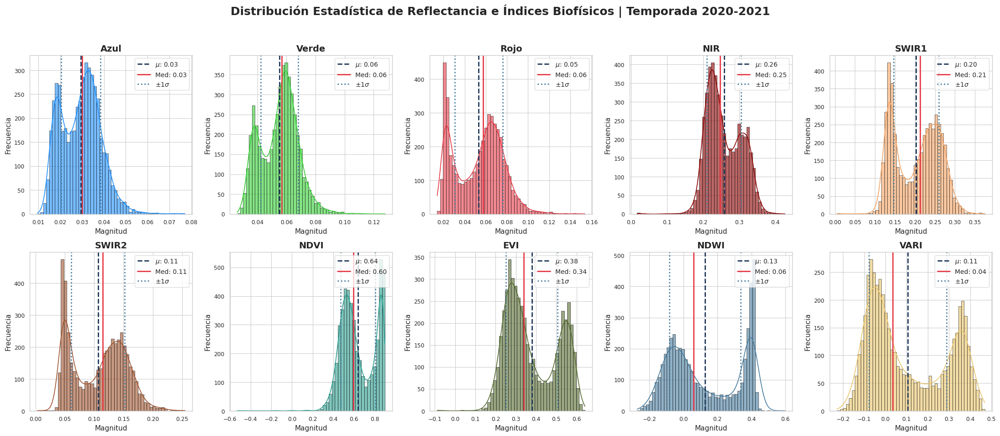

   └─ ✅ Figura exportada exitosamente: /content/drive/MyDrive/tesismsif_assets/09_Histogramas_Espectrales_2020-2021.png
   ├─ Extrayendo muestra espacial (N=5000) para la temporada 2021-2022...
   ├─ Renderizando gráficos de distribución estadística...


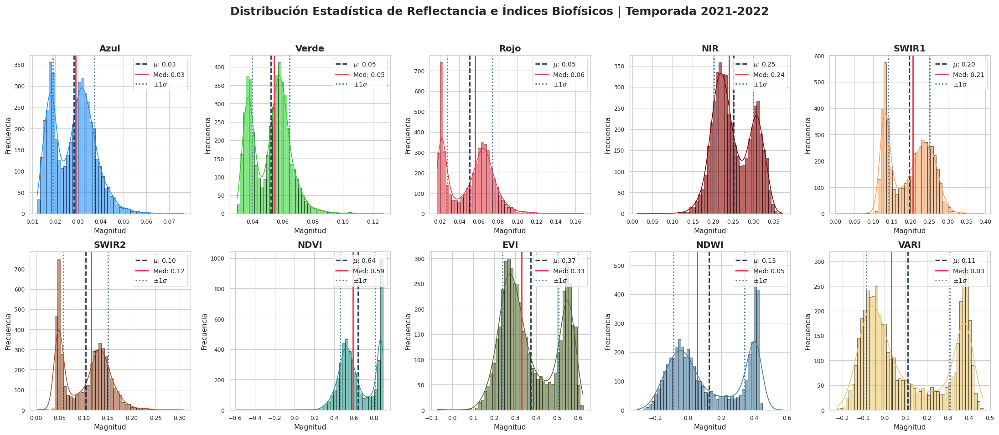

   └─ ✅ Figura exportada exitosamente: /content/drive/MyDrive/tesismsif_assets/09_Histogramas_Espectrales_2021-2022.png
   ├─ Extrayendo muestra espacial (N=5000) para la temporada 2022-2023...
   ├─ Renderizando gráficos de distribución estadística...


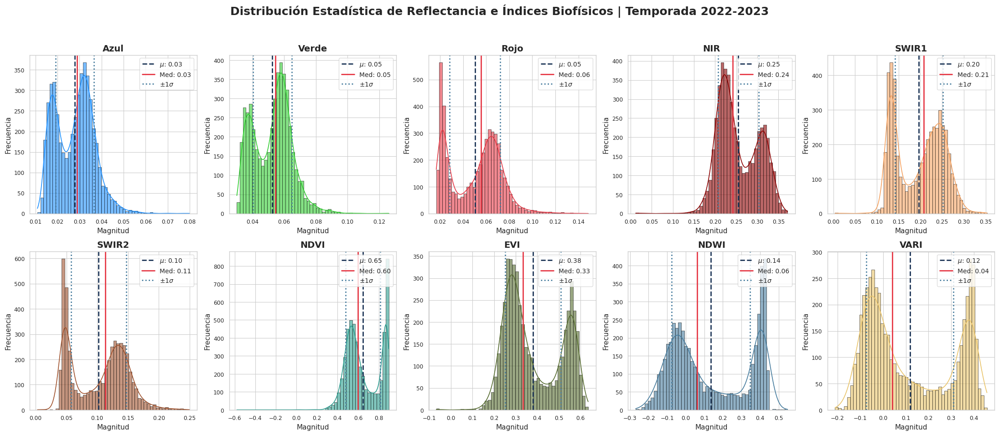

   └─ ✅ Figura exportada exitosamente: /content/drive/MyDrive/tesismsif_assets/09_Histogramas_Espectrales_2022-2023.png
   ├─ Extrayendo muestra espacial (N=5000) para la temporada 2023-2024...
   ├─ Renderizando gráficos de distribución estadística...


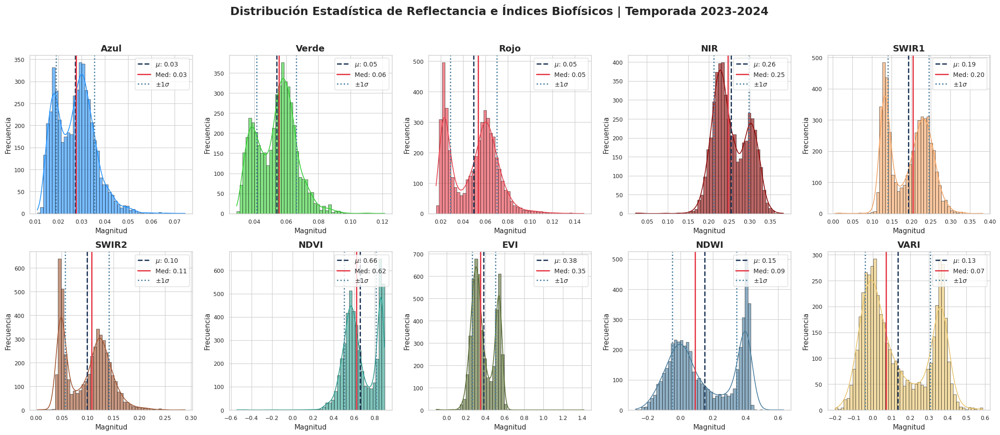

   └─ ✅ Figura exportada exitosamente: /content/drive/MyDrive/tesismsif_assets/09_Histogramas_Espectrales_2023-2024.png
   ├─ Extrayendo muestra espacial (N=5000) para la temporada 2024-2025...
   ├─ Renderizando gráficos de distribución estadística...


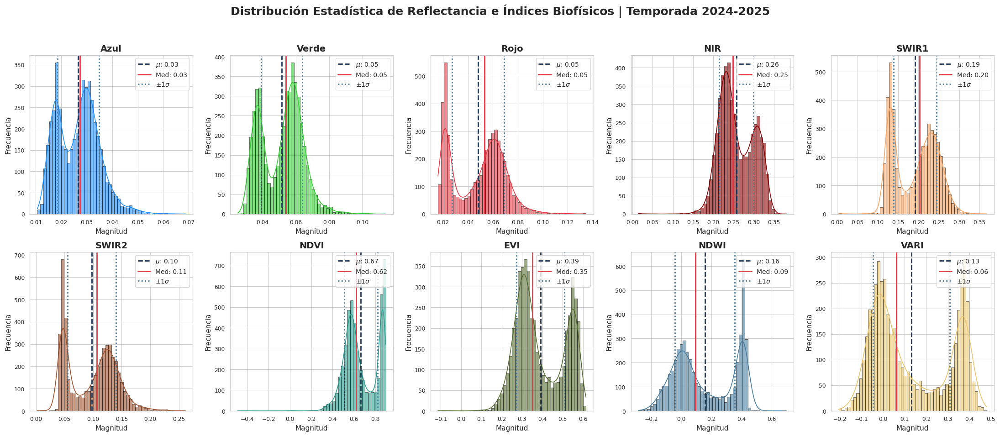

   └─ ✅ Figura exportada exitosamente: /content/drive/MyDrive/tesismsif_assets/09_Histogramas_Espectrales_2024-2025.png

☑️ Análisis Exploratorio de Datos (EDA) finalizado.


In [ ]:
# ==============================================================================
# TÍTULO: ANÁLISIS EXPLORATORIO DE DATOS (EDA) - DISTRIBUCIÓN ESPECTRAL
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Muestreo espacial aleatorio del tensor multivariable y
#              generación de histogramas de distribución (estilo publicación).
# ==============================================================================

import ee
import geemap
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

def generar_histogramas_espectrales(coleccion_aoi, anios_estudio: list, ruta_drive: str, ruta_assets: str):
    """
    Extrae muestras espaciales del tensor espectral unificado y genera un
    panel de histogramas con estadísticos de tendencia central y dispersión.
    """
    print("\n⏳ Inicializando Análisis Exploratorio de Datos (EDA) espectral...")
    geometria_dominio = coleccion_aoi.geometry()

    # Configuración estética global de Seaborn (Estilo científico limpio)
    sns.set_theme(style="whitegrid", context="paper")

    # Configuración de paletas de color para cada banda (asociación fenológica)
    config_graficos = [
        ('Azul', '#1E90FF'), ('Verde', '#32CD32'), ('Rojo', '#E63946'),
        ('NIR', '#8B0000'), ('SWIR1', '#F4A261'), ('SWIR2', '#A0522D'),
        ('NDVI', '#2A9D8F'), ('EVI', '#556B2F'), ('NDWI', '#457B9D'), ('VARI', '#E9C46A')
    ]

    bandas_reflectancia = ['Azul', 'Verde', 'Rojo', 'NIR', 'SWIR1', 'SWIR2']
    bandas_indices = ['NDVI', 'EVI', 'NDWI', 'VARI']

    for anio_inicio in anios_estudio:
        anio_fin = anio_inicio + 1
        temporada = f"{anio_inicio}-{anio_fin}"

        print(f"   ├─ Extrayendo muestra espacial (N=5000) para la temporada {temporada}...")

        # 1. Carga del Tensor Espectral Unificado desde ASSETS (Materializado)
        # Esto evita el límite de memoria interactivo de GEE.
        id_asset = f"{ruta_assets}Tensor_Espectral_{temporada}_Vichada"
        try:
            tensor_espectral = ee.Image(id_asset)
            # Forzamos la verificación de existencia del Asset
            _ = tensor_espectral.bandNames().getInfo()
        except Exception as e:
            print(f"⚠️ Error: No se pudo cargar el Asset {id_asset}. ¿Aún se está exportando en GEE? Detalles: {e}")
            continue

        img_reflectancia = tensor_espectral.select(bandas_reflectancia)
        img_indices = tensor_espectral.select(bandas_indices)

        img_analisis = img_reflectancia.addBands(img_indices)

        # 2. Muestreo Espacial Aleatorio (Random Sampling)
        # Se escala a 2500m para garantizar representatividad regional y evitar límites de memoria
        muestreo_fc = img_analisis.sample(
            region=geometria_dominio,
            scale=2500,
            numPixels=5000,
            geometries=False,
            seed=42
        )

        # 3. Conversión a DataFrame local
        try:
            df_muestreo = geemap.ee_to_df(muestreo_fc)
        except Exception as e:
            print(f"⚠️ Error convirtiendo a DataFrame para {temporada}: {e}")
            continue

        if df_muestreo.empty:
            print(f"⚠️ DataFrame vacío para {temporada}.")
            continue

        # 4. Generación del Panel de Gráficos (Dashboard)
        print(f"   ├─ Renderizando gráficos de distribución estadística...")
        fig, axes = plt.subplots(2, 5, figsize=(22, 10))
        fig.suptitle(f'Distribución Estadística de Reflectancia e Índices Biofísicos | Temporada {temporada}',
                     fontsize=18, fontweight='bold', y=0.98)
        axes = axes.flatten()

        for i, (banda, color) in enumerate(config_graficos):
            if banda in df_muestreo.columns:
                # Filtrado de valores atípicos severos o nulos
                datos = df_muestreo[banda].dropna()

                # Histograma con Curva de Densidad (KDE)
                sns.histplot(datos, bins=50, color=color, ax=axes[i], kde=True, edgecolor='black', alpha=0.6)

                # Estadísticos descriptivos
                media_val = datos.mean()
                mediana_val = datos.median()
                std_val = datos.std()

                # Líneas de referencia
                axes[i].axvline(media_val, color='#1D3557', linestyle='dashed', linewidth=2, label=f'$\mu$: {media_val:.2f}')
                axes[i].axvline(mediana_val, color='#E63946', linestyle='solid', linewidth=2, label=f'Med: {mediana_val:.2f}')
                axes[i].axvline(media_val + std_val, color='#457B9D', linestyle='dotted', linewidth=2, label=f'$\pm 1\sigma$')
                axes[i].axvline(media_val - std_val, color='#457B9D', linestyle='dotted', linewidth=2)

                # Formato del Subplot
                axes[i].set_title(banda, fontweight='bold', fontsize=14)
                axes[i].set_xlabel('Magnitud', fontsize=11)
                axes[i].set_ylabel('Frecuencia', fontsize=11)
                axes[i].legend(fontsize=10, loc='upper right', frameon=True, facecolor='white')

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()

        # 5. Exportación del Panel a Google Drive
        os.makedirs(ruta_drive, exist_ok=True)
        ruta_figura = os.path.join(ruta_drive, f'09_Histogramas_Espectrales_{temporada}.png')
        fig.savefig(ruta_figura, dpi=600, bbox_inches='tight', facecolor='white')

        # Liberación de memoria de Matplotlib
        plt.close(fig)
        print(f"   └─ ✅ Figura exportada exitosamente: {ruta_figura}")

    print("\n☑️ Análisis Exploratorio de Datos (EDA) finalizado.")

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    # Parametrización
    ANIOS_ANALISIS = list(range(2019, 2025))
    RUTA_DRIVE_EXPORT = '/content/drive/MyDrive/tesismsif_assets'
    RUTA_ASSETS = 'projects/tesismsif/assets/'

    # Ejecución (Se asume 'dominio_vichada' instanciado en Bloque 1)
    generar_histogramas_espectrales(
        coleccion_aoi=dominio_vichada,
        anios_estudio=ANIOS_ANALISIS,
        ruta_drive=RUTA_DRIVE_EXPORT,
        ruta_assets=RUTA_ASSETS
    )


## 5.2.11 Dinámica Espacio-Temporal de los Combustibles Forestales

La probabilidad de ignición y propagación de los incendios forestales en la Orinoquía colombiana está estrictamente subordinada a la cantidad, distribución y estado hídrico del material combustible vegetal (Garcia-Suabita et al., 2024). Para caracterizar la evolución interanual de la vegetación durante los periodos de estiaje, se construyeron series de tiempo multianuales a partir de los estadísticos poblacionales de las covariables espectrales ($\mu$).

La trayectoria temporal de cada índice biofísico $I$ se modeló extrayendo la media espacial del tensor para cada temporada $t$:

$$ \mu_{I}(t) = \frac{1}{A} \int_{\Omega} I(x, y, t) \, dA $$

Donde $\Omega$ representa el dominio territorial del Vichada y $A$ su área total. La inspección visual de las gráficas de evolución temporal permite correlacionar el estrés biótico con las forzantes macroclimáticas (ej. fenómenos ENSO).

Un descenso abrupto en la función de trayectoria del Índice Normalizado de Diferencia de Agua ($\mu_{NDWI}(t) < 0$) sincronizado con un decaimiento del Índice de Vegetación Mejorado ($\mu_{EVI}(t)$), constituye una firma inequívoca de desecación severa de la biomasa fina (pastos y arbustos). La caracterización de estos patrones espaciotemporales mediante teledetección corrobora empíricamente las alteraciones en la vulnerabilidad de los ecosistemas (Bolaño-Díaz et al., 2022), suministrando el contexto necesario para la correcta interpretación algorítmica de la matriz de predictores del modelo de *Machine Learning*.


⏳ Renderizando trayectorias temporales de índices espectrales (Matplotlib)...
💾 Gráfica de subplots exportada exitosamente en: /content/drive/MyDrive/tesismsif_assets/10_Evolucion_Subplots.png


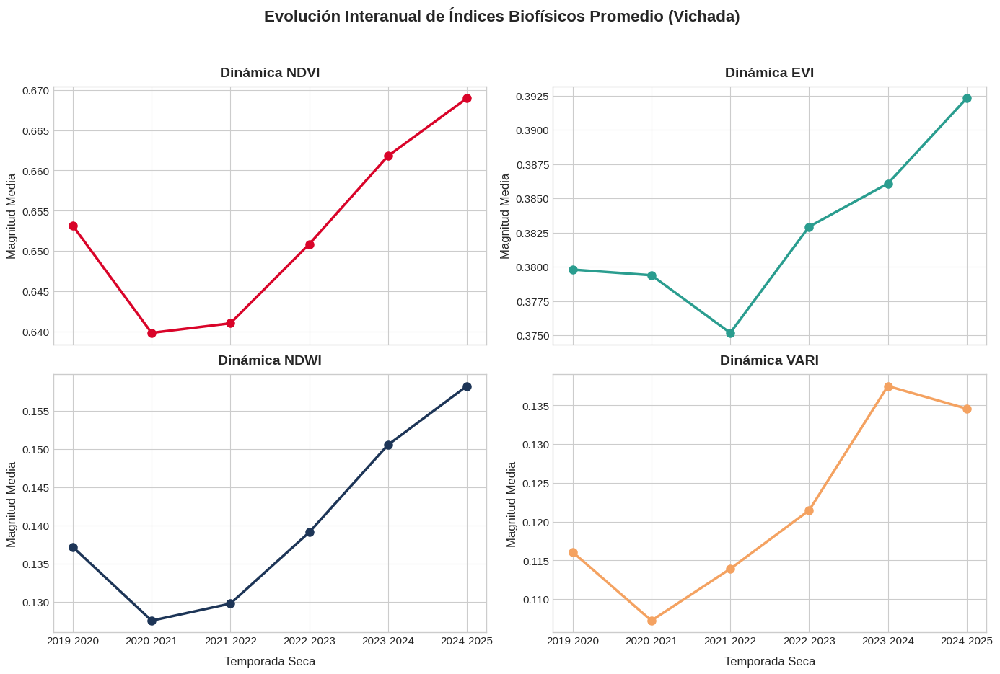

💾 Gráfica combinada exportada exitosamente en: /content/drive/MyDrive/tesismsif_assets/11_Comparacion_Combinada.png


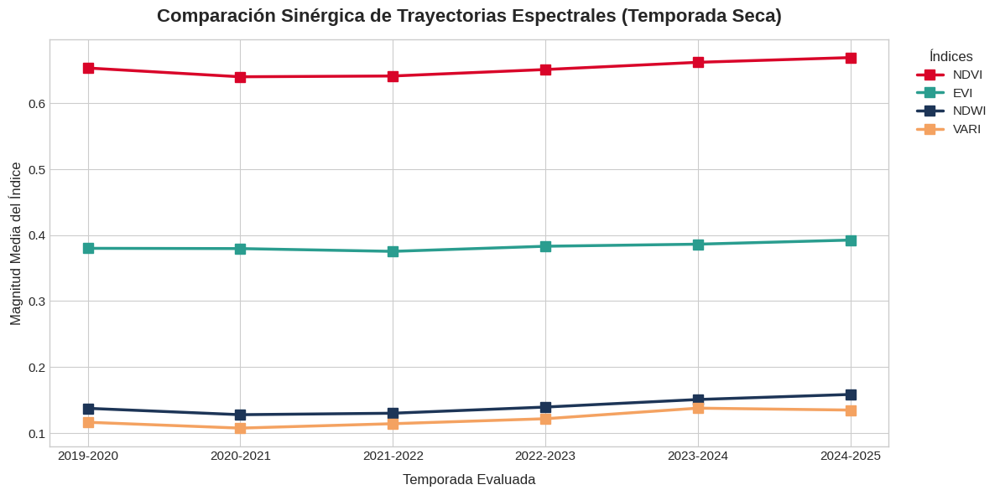

In [ ]:
# ==============================================================================
# TÍTULO: GRÁFICOS DE EVOLUCIÓN TEMPORAL DE ÍNDICES ESPECTRALES (MATPLOTLIB)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Generación de series de tiempo multianuales mediante Matplotlib,
#              con exportación directa a PNG de alta resolución (600 dpi).
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
import os

def generar_evolucion_temporal_matplotlib(df_estadisticas, ruta_drive_exportacion: str):
    """
    Construye y exporta gráficos de series de tiempo para evaluar
    la trayectoria fenológica interanual de los índices biofísicos usando Matplotlib.
    """
    print("\n⏳ Renderizando trayectorias temporales de índices espectrales (Matplotlib)...")

    # 1. Creación del directorio de salida en Google Drive
    os.makedirs(ruta_drive_exportacion, exist_ok=True)

    # Preparar datos
    df_plot = df_estadisticas.copy()
    df_plot['Temporada'] = df_plot['image_id'].str.replace('Medoid_', '')

    # Configuración paramétrica: (Columna_DF, Color_HEX, Fila, Columna, Título)
    configuracion_indices = [
        ('NDVI_mean', '#D90429', 0, 0, 'Dinámica NDVI'),    # Rojo fuerte
        ('EVI_mean', '#2A9D8F', 0, 1, 'Dinámica EVI'),     # Verde oscuro
        ('NDWI_mean', '#1D3557', 1, 0, 'Dinámica NDWI'),    # Azul marino
        ('VARI_mean', '#F4A261', 1, 1, 'Dinámica VARI')     # Naranja
    ]

    plt.style.use('seaborn-v0_8-whitegrid')

    # ==========================================================================
    # GRÁFICO 1: SUBPLOTS DE EVOLUCIÓN INDIVIDUAL
    # ==========================================================================
    fig_subplots, axs = plt.subplots(2, 2, figsize=(14, 10), sharex=True)

    for columna, color, fila, col_idx, titulo in configuracion_indices:
        if columna in df_plot.columns:
            ax = axs[fila, col_idx]
            ax.plot(df_plot['Temporada'], df_plot[columna], color=color, marker='o', linewidth=2.5, markersize=8)
            ax.set_title(titulo, fontsize=14, fontweight='bold', pad=10)
            ax.tick_params(axis='both', which='major', labelsize=11)
            ax.set_ylabel('Magnitud Media', fontsize=12)
            if fila == 1:
                ax.set_xlabel('Temporada Seca', fontsize=12, labelpad=10)

    plt.suptitle('Evolución Interanual de Índices Biofísicos Promedio (Vichada)', fontsize=16, fontweight='bold', y=0.96)
    fig_subplots.tight_layout(rect=[0, 0.03, 1, 0.93])

    ruta_sub_png = os.path.join(ruta_drive_exportacion, '10_Evolucion_Subplots.png')
    fig_subplots.savefig(ruta_sub_png, dpi=600, bbox_inches='tight', facecolor='white')
    print(f"💾 Gráfica de subplots exportada exitosamente en: {ruta_sub_png}")
    plt.show()

    # ==========================================================================
    # GRÁFICO 2: COMPARACIÓN DIRECTA COMBINADA
    # ==========================================================================
    fig_combinada, ax_comb = plt.subplots(figsize=(12, 6))

    for columna, color, _, _, titulo in configuracion_indices:
        if columna in df_plot.columns:
            nombre_etiqueta = titulo.replace('Dinámica ', '')
            ax_comb.plot(df_plot['Temporada'], df_plot[columna], color=color, marker='s', linewidth=2.5, markersize=8, label=nombre_etiqueta)

    ax_comb.set_title('Comparación Sinérgica de Trayectorias Espectrales (Temporada Seca)', fontsize=16, fontweight='bold', pad=15)
    ax_comb.set_xlabel('Temporada Evaluada', fontsize=12, labelpad=10)
    ax_comb.set_ylabel('Magnitud Media del Índice', fontsize=12)
    ax_comb.tick_params(axis='both', which='major', labelsize=11)
    ax_comb.legend(title='Índices', fontsize=11, title_fontsize=12, bbox_to_anchor=(1.02, 1), loc='upper left')

    fig_combinada.tight_layout()
    ruta_comb_png = os.path.join(ruta_drive_exportacion, '11_Comparacion_Combinada.png')
    fig_combinada.savefig(ruta_comb_png, dpi=600, bbox_inches='tight', facecolor='white')
    print(f"💾 Gráfica combinada exportada exitosamente en: {ruta_comb_png}")
    plt.show()

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    # Parametrización
    RUTA_DRIVE_GRAFICOS = '/content/drive/MyDrive/tesismsif_assets'

    # Se asume que df_resultados_auditoria fue instanciado en el bloque previo
    generar_evolucion_temporal_matplotlib(
        df_estadisticas=df_resultados_auditoria,
        ruta_drive_exportacion=RUTA_DRIVE_GRAFICOS
    )


## 5.2.12 Armonización Espacial (Upscaling) y Muestreo Estratificado

El éxito del aprendizaje automático en geociencias depende de la integridad topológica entre el espacio de características ($X$) y la variable objetivo ($y$). En este estudio, se identificó un conflicto de resolución (*Spatial Mismatch*): los predictores topográficos y espectrales poseían un grado de detalle de 30 metros, mientras que la variable de área quemada (MODIS) se estructuraba sobre una malla de 500 metros (Wen et al., 2025).

Para evitar la pérdida de información sobre la variabilidad interna del ecosistema producida por una simple sustracción de píxeles centrales, se implementó un proceso de agregación espacial ascendente (*Upscaling*). A cada celda de 500 metros del dominio objetivo se le asignó un vector resultante de una función de agregación ($f_{agg}$) operada sobre los $\approx 277$ sub-píxeles nativos de 30 metros subyacentes:

$$ X_{500m} = f_{agg} \left( X_{30m} \right) $$

Esta función combinó cuatro descriptores estadísticos robustos con el fin de capturar la distribución de la biomasa y el clima dentro de la celda: la mediana ($\tilde{x}$) para la tendencia central resistente a valores atípicos, la desviación estándar ($\sigma$) para medir la heterogeneidad intrínseca, y los percentiles inferior ($P_{25}$) y superior ($P_{75}$) para documentar las señales espectrales dominantes.

Una vez homogeneizada la matriz de datos continuos, se procedió a mitigar el sesgo de clase mayoritaria, característico en la modelación de incendios donde las áreas intactas dominan fuertemente la ecorregión. Se aplicó un algoritmo de muestreo aleatorio estratificado (*Stratified Random Sampling*) con el que se obtuvo un número de muestras equitativo $N_{fuego} = N_{no-fuego}$ (Poveda et al., 2022). La matriz tabular bidimensional resultante se exportó conservando las coordenadas geodésicas de las observaciones, proporcionando el insumo matemático base para el entrenamiento estructurado del algoritmo *Random Forest*.

In [ ]:
# ==============================================================================
# TÍTULO: ARMONIZACIÓN ESPACIAL Y MUESTREO ESTRATIFICADO (UPSCALING 30m -> 500m)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Agregación ascendente de covariables usando descriptores estadísticos,
#              extracción de muestras balanceadas y exportación asíncrona a Drive.
# ==============================================================================

import ee
import os
import pandas as pd

def generar_matriz_entrenamiento(anios_estudio: list, ruta_assets: str, ruta_drive: str):
    """
    Armoniza la resolución de los tensores de 30m a la malla de 500m de MODIS,
    extrae puntos de entrenamiento balanceados y envía las tareas de exportación.
    """
    print("\n⏳ Inicializando arquitectura de armonización espacial y muestreo...")

    # 1. DEFINICIÓN DEL REDUCTOR MULTIVARIABLE (Agregación Ascendente)
    # Se extraen 4 bandas por cada variable de 30m para caracterizar la celda de 500m
    reductor_armonizacion = (ee.Reducer.median()
                             .combine(reducer2=ee.Reducer.stdDev(), sharedInputs=True)
                             .combine(reducer2=ee.Reducer.percentile([25, 75]), sharedInputs=True))

    # 2. CARGA DE PREDICTORES ESTÁTICOS (Topografía y Distancias)
    try:
        tensor_estatico = ee.Image(f"{ruta_assets}Stack_Estatico_Vichada")
    except Exception as e:
        raise RuntimeError(f"❌ Error al cargar predictores estáticos: {e}")

    # Límite administrativo para el recorte computacional
    dominio_vichada = ee.FeatureCollection(f"{ruta_assets}Departamento_Vichada_IGAC")

    # 3. PROCESAMIENTO ITERATIVO MULTITEMPORAL
    for anio_inicio in anios_estudio:
        anio_fin = anio_inicio + 1
        temporada = f"{anio_inicio}-{anio_fin}"
        print(f"\n   ├─ Procesando extracción de datos para la temporada {temporada}...")

        nombre_csv = f"Dataset_Entrenamiento_RF_{temporada}"
        id_asset_export = f"{ruta_assets}{nombre_csv}"

        # 3.1 CARGA DE PREDICTORES DINÁMICOS
        try:
            tensor_espectral = ee.Image(f"{ruta_assets}Tensor_Espectral_{temporada}_Vichada")
            tensor_clima = ee.Image(f"{ruta_assets}Stack_Clima_{temporada}_Vichada")
            objetivo_modis = ee.Image(f"{ruta_assets}Target_Quemado_MODIS_{anio_inicio}_{anio_fin}")
        except Exception as e:
            print(f"   └─ ⚠️ Faltan insumos para la temporada {temporada}. Omitiendo. Detalle: {e}")
            continue

        # Extracción de la grilla oficial de MODIS para el alineamiento (Snap Raster)
        proyeccion_modis = objetivo_modis.projection()

        # Consolidación del cubo de predictores a 30m
        predictores_30m = ee.Image.cat([tensor_estatico, tensor_espectral, tensor_clima])

        # 3.2 ARMONIZACIÓN ESPACIAL (Upscaling 30m -> 500m)
        print("   ├─ Ejecutando agregación espacial ascendente (Reduce Resolution)...")
        predictores_500m = (predictores_30m
                            .reduceResolution(reducer=reductor_armonizacion, maxPixels=1024)
                            .reproject(crs=proyeccion_modis))

        # Matriz final de variables independientes (X) y dependientes (y)
        matriz_espacial = predictores_500m.addBands(objetivo_modis)

        # 3.3 CONTEO POBLACIONAL PARA BALANCEO DE CLASES
        # Extracción segura del número de incendios detectados para fijar el 'numPoints'
        conteo_fuego = objetivo_modis.reduceRegion(
            reducer=ee.Reducer.sum(),
            geometry=dominio_vichada.geometry(),
            scale=500,
            maxPixels=1e10
        ).get('Quemado_Binario').getInfo()

        total_quemados = int(conteo_fuego) if conteo_fuego is not None else 0
        print(f"   ├─ Píxeles positivos (quemados) detectados en el estrato: {total_quemados}")

        if total_quemados == 0:
            print("   └─ ⚠️ No se detectaron anomalías térmicas en esta temporada. Omitiendo muestreo.")
            continue

        # 3.4 MUESTREO ALEATORIO ESTRATIFICADO (Sampling)
        # Extrae un N igual para clase 1 (Fuego) y clase 0 (No Fuego) garantizando equilibrio
        print("   ├─ Extrayendo observaciones tabulares equilibradas (Stratified Sample)...")
        muestras_tabla = matriz_espacial.stratifiedSample(
            numPoints=total_quemados,
            classBand='Quemado_Binario',
            region=dominio_vichada.geometry(),
            scale=500,
            seed=42, # Semilla de reproducibilidad
            geometries=True, # Conservar coordenadas para análisis espaciales del error
            tileScale=16
        ).map(lambda feature: feature.set('Temporada', temporada))

        # 3.5 DELEGACIÓN ASÍNCRONA DE TAREAS (Exportación robusta)
        if not verificar_existencia_asset(id_asset_export):
            # Exportar a GEE Assets
            ee.batch.Export.table.toAsset(
                collection=muestras_tabla,
                description=f"Asset_CSV_{temporada}",
                assetId=id_asset_export
            ).start()

            # Exportar a Google Drive
            ee.batch.Export.table.toDrive(
                collection=muestras_tabla,
                description=f"Drive_CSV_{temporada}",
                folder=ruta_drive,
                fileNamePrefix=nombre_csv,
                fileFormat='CSV'
            ).start()
            print(f"   └─ ✅ Tareas de exportación de la matriz ({nombre_csv}) enviadas a GEE.")
        else:
            print(f"   └─ ℹ️ El Dataset '{id_asset_export}' ya se encuentra procesado.")

    print("\n☑️ Pipeline de muestreo delegado con éxito. Esperar la finalización en GEE Tasks.")
    print("👉 Enlace: https://code.earthengine.google.com/tasks")

def consolidar_datasets_descargados(anios_estudio: list, ruta_drive_csv: str):
    """
    Combina los CSVs individuales exportados por GEE en un único DataFrame maestro,
    asegurando un balanceo equitativo de clases (50/50) independientemente para cada temporada.
    """
    print("\n⏳ Consolidando y balanceando el repositorio de datos de entrenamiento por temporada...")
    lista_dfs = []

    for anio_inicio in anios_estudio:
        temporada = f"{anio_inicio}-{anio_inicio+1}"
        ruta_archivo = os.path.join(ruta_drive_csv, f"Dataset_Entrenamiento_RF_{temporada}.csv")

        if os.path.exists(ruta_archivo):
            df_temp = pd.read_csv(ruta_archivo)

            # ------------------------------------------------------------------
            # BALANCEO DE CLASES POR TEMPORADA (Undersampling local)
            # Para solucionar la pérdida de Nulos de GEE y garantizar el 50/50.
            # ------------------------------------------------------------------
            if 'Quemado_Binario' in df_temp.columns:
                min_clase = df_temp['Quemado_Binario'].value_counts().min()
                df_temp_balanceado = df_temp.groupby('Quemado_Binario').sample(n=min_clase, random_state=42)
                lista_dfs.append(df_temp_balanceado)
                print(f"   ├─ Temporada {temporada} cargada y balanceada: {len(df_temp_balanceado)} registros ({min_clase} por clase).")
            else:
                lista_dfs.append(df_temp)
                print(f"   ├─ Temporada {temporada} cargada: {len(df_temp)} registros (Sin columna objetivo).")
        else:
            print(f"   ├─ ⚠️ Archivo no encontrado para {temporada}. ¿Finalizó la tarea en GEE?")

    if lista_dfs:
        df_maestro = pd.concat(lista_dfs, ignore_index=True).dropna()
        ruta_maestro = os.path.join(ruta_drive_csv, 'Dataset_Entrenamiento_RF_Consolidado_Maestro.csv')
        df_maestro.to_csv(ruta_maestro, index=False)
        print(f"✅ Matriz consolidada generada con {len(df_maestro)} registros de entrenamiento totalmente balanceados.")
        print(f"💾 Guardado en: {ruta_maestro}")
        return df_maestro
    else:
        return None

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    ANIOS_ANALISIS = list(range(2019, 2025))
    RUTA_ASSETS = 'projects/tesismsif/assets/'
    RUTA_DRIVE_CARPETA = 'tesismsif_assets'

    # 1. Generación y delegación asíncrona de las tareas a los clústeres de Google
    generar_matriz_entrenamiento(ANIOS_ANALISIS, RUTA_ASSETS, RUTA_DRIVE_CARPETA)

    # 2. Consolidación de matrices.
    # ADVERTENCIA: Esta función requiere que las tareas 'toDrive' hayan finalizado.
    # En un entorno real, ejecutar esta línea unas horas después de revisar GEE Tasks.
    RUTA_REAL_DRIVE = f"/content/drive/MyDrive/{RUTA_DRIVE_CARPETA}"
    df_modelo_final = consolidar_datasets_descargados(
        ANIOS_ANALISIS,
        RUTA_REAL_DRIVE)



⏳ Inicializando arquitectura de armonización espacial y muestreo...

   ├─ Procesando extracción de datos para la temporada 2019-2020...
   ├─ Ejecutando agregación espacial ascendente (Reduce Resolution)...
   ├─ Píxeles positivos (quemados) detectados en el estrato: 42630
   ├─ Extrayendo observaciones tabulares equilibradas (Stratified Sample)...
   └─ ℹ️ El Dataset 'projects/tesismsif/assets/Dataset_Entrenamiento_RF_2019-2020' ya se encuentra procesado.

   ├─ Procesando extracción de datos para la temporada 2020-2021...
   ├─ Ejecutando agregación espacial ascendente (Reduce Resolution)...
   ├─ Píxeles positivos (quemados) detectados en el estrato: 13753
   ├─ Extrayendo observaciones tabulares equilibradas (Stratified Sample)...
   └─ ℹ️ El Dataset 'projects/tesismsif/assets/Dataset_Entrenamiento_RF_2020-2021' ya se encuentra procesado.

   ├─ Procesando extracción de datos para la temporada 2021-2022...
   ├─ Ejecutando agregación espacial ascendente (Reduce Resolution)...
   

## 5.2.13 Auditoría del Diseño Muestral y Mitigación del Sesgo Inductivo

Uno de los desafíos algorítmicos más severos en la modelación de la susceptibilidad a incendios forestales es el desbalance intrínseco de las clases ecosistémicas (*Class Imbalance Problem*). En grandes extensiones territoriales como el Vichada, la proporción de áreas quemadas ($\Omega_f$) suele ser un subconjunto ínfimo frente a las áreas no perturbadas ($\Omega_{nf}$), lo que genera distribuciones poblacionales asimétricas.

Si un modelo de *Machine Learning* es entrenado con una matriz que respeta esta distribución natural, desarrollará un "Sesgo Inductivo" (*Inductive Bias*). El clasificador priorizará la reducción del error global (Loss function) prediciendo sistemáticamente la clase mayoritaria (0), alcanzando una precisión engañosamente alta, pero fallando en su objetivo principal: detectar las áreas propensas a incendiarse (Ramo & Chuvieco, 2017).

Para garantizar una curva de aprendizaje óptima, se verificó matemáticamente el equilibrio de la matriz de datos final generada a través del Muestreo Aleatorio Estratificado. Se validó que las probabilidades *a priori* ($P$) de ambas clases en la base de entrenamiento tendieran a la equiprobabilidad:

$$P(y=1) = \frac{N_{fuego}}{N_{total}} \approx 0.5$$
$$P(y=0) = \frac{N_{no-fuego}}{N_{total}} \approx 0.5$$

Adicionalmente, se ejecutó una auditoría topológica de la dispersión espacial de los $N_{total}$ vectores extraídos. La renderización cartográfica de las muestras confirmó la ausencia de aglomeraciones anómalas (Clustering artificial), certificando que el muestreo capturó eficientemente toda la gradiente de la varianza ambiental, climática y antropogénica subyacente en el departamento del Vichada (Barreto & Armenteras, 2020).

In [ ]:
# ==============================================================================
# TÍTULO: AUDITORÍA ESTADÍSTICA Y ESPACIAL DEL DATASET DE ENTRENAMIENTO
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Verificación del balance de clases en memoria, exportación a CSV,
#              renderizado topológico y exportación del mapa a TIF en Drive/Assets.
# ==============================================================================

import ee
import geemap
import pandas as pd
import os

def auditar_balance_y_distribucion(df_consolidado, coleccion_aoi, anios_estudio: list, ruta_assets: str, ruta_drive_html: str, ruta_drive_export: str):
    """
    Evalúa el equilibrio poblacional de las clases (Quemado/No Quemado), exporta
    la estadística en CSV, y despliega/exporta cartográficamente las muestras.
    """

    # ==========================================================================
    # 1. AUDITORÍA ESTADÍSTICA (Dataframe Local y CSV)
    # ==========================================================================
    if df_consolidado is not None and not df_consolidado.empty:
        print("\n===================================================================")
        print("       AUDITORÍA ESTADÍSTICA: DISTRIBUCIÓN DE CLASES (Target 'y')  ")
        print("===================================================================")

        conteo_clases = df_consolidado['Quemado_Binario'].value_counts()
        porcentaje_clases = df_consolidado['Quemado_Binario'].value_counts(normalize=True) * 100

        resumen_clases = pd.DataFrame({
            'Frecuencia Absoluta (N)': conteo_clases,
            'Frecuencia Relativa (%)': porcentaje_clases
        })
        display(resumen_clases.round(2))

        # Exportar a CSV
        ruta_csv = ruta_drive_html.replace('.html', '.csv')
        os.makedirs(os.path.dirname(ruta_csv), exist_ok=True)
        resumen_clases.to_csv(ruta_csv)
        print(f"💾 Auditoría estadística exportada a CSV en: {ruta_csv}")

        total_registros = len(df_consolidado)
        print(f"\n📊 Total de muestras de entrenamiento: {total_registros:,}")

        if len(conteo_clases) > 1:
            diferencia = abs(conteo_clases.iloc[0] - conteo_clases.iloc[1])
            print(f"⚖️ Diferencia absoluta entre estratos: {diferencia} registros.")
            if diferencia < (total_registros * 0.05):
                print("✅ Estado: EQUILIBRIO ÓPTIMO (Sesgo de clase mayoritaria mitigado).")
            else:
                print("⚠️ Estado: DESBALANCE DETECTADO. Considere ajustar la semilla de muestreo.")
    else:
        print("⚠️ Advertencia: El DataFrame consolidado no está disponible en memoria.")

    # ==========================================================================
    # 2. AUDITORÍA ESPACIAL (Google Earth Engine)
    # ==========================================================================
    print("\n⏳ Renderizando distribución topológica de las muestras estratificadas...")
    mapa_muestreo = geemap.Map()
    mapa_muestreo.centerObject(coleccion_aoi.geometry(), zoom=7)
    mapa_muestreo.add_basemap('HYBRID')

    estilo_limite = {'fillColor': '00000000', 'color': 'black', 'width': 2.5}
    mapa_muestreo.addLayer(coleccion_aoi.style(**estilo_limite), {}, 'Dominio (Vichada)', True)

    print("\n⏳ Programando exportaciones del raster de muestreo (TIF) a Drive y Assets por temporada...")
    for anio_inicio in anios_estudio:
        anio_fin = anio_inicio + 1
        temporada = f"{anio_inicio}-{anio_fin}"
        id_asset_muestras = f"{ruta_assets}Dataset_Entrenamiento_RF_{temporada}"

        try:
            # Conexión directa a los FeatureCollections almacenados en Assets
            puntos_temporada = ee.FeatureCollection(id_asset_muestras)

            # Función Server-Side para asignación condicional de estilos cartográficos
            def asignar_estilo_clase(feature):
                color_hexa = ee.Algorithms.If(
                    ee.Number(feature.get('Quemado_Binario')).eq(1),
                    '#D90429', # Carmesí (Fuego)
                    '#48CAE4'  # Cian (No Fuego)
                )
                return feature.set('style', {'color': color_hexa, 'pointSize': 2, 'pointShape': 'circle'})

            # Aplicación del estilo en el servidor para evitar lentitud en el cliente
            coleccion_estilizada = puntos_temporada.map(asignar_estilo_clase).style(styleProperty='style')
            mapa_muestreo.addLayer(coleccion_estilizada, {}, f'Muestras RF {temporada}', False)

            # ==========================================================================
            # NUEVA LÓGICA: Exportación de Ráster por Temporada
            # ==========================================================================
            # Inicializamos la imagen con un valor de NoData (ej. 255) para diferenciar los ceros reales
            imagen_base = ee.Image.constant(255).byte()
            imagen_raster = imagen_base.paint(puntos_temporada, 'Quemado_Binario').byte()
            # Enmascaramos los píxeles que siguen teniendo el valor de NoData (255)
            imagen_raster = imagen_raster.updateMask(imagen_raster.neq(255))

            nombre_tif = f'12_Mapa_Muestreo_Espacial_{temporada}'
            id_asset_tif = f"{ruta_assets}{nombre_tif}"

            if not verificar_existencia_asset(id_asset_tif):
                # A Google Drive
                ee.batch.Export.image.toDrive(
                    image=imagen_raster,
                    description=f'Drive_{nombre_tif}',
                    folder=ruta_drive_export,
                    fileNamePrefix=nombre_tif,
                    region=coleccion_aoi.geometry().bounds(),
                    scale=500,
                    crs='EPSG:32619',
                    maxPixels=1e10
                )#.start()

                # A GEE Assets
                ee.batch.Export.image.toAsset(
                    image=imagen_raster,
                    description=f'Asset_{nombre_tif}',
                    assetId=id_asset_tif,
                    region=coleccion_aoi.geometry().bounds(),
                    scale=500,
                    crs='EPSG:32619',
                    maxPixels=1e10
                ).start()
                print(f"   └─ ✅ Tareas enviadas a GEE para exportar el mapa .TIF de la temporada {temporada}.")
            else:
                print(f"   └─ ℹ️ El mapa de muestreo para {temporada} ya existe en Assets.")

        except Exception as e:
            print(f"   └─ ⚠️ No se pudo procesar el asset de la temporada {temporada}. Detalle: {e}")

    print("\n✅ Mapa de auditoría espacial generado exitosamente.")
    print("👉 Leyenda visual: Rojo = Clase 1 (Quemado) | Cian = Clase 0 (No Quemado)")

    # ==========================================================================
    # 3. EXPORTACIÓN DEL REPORTE INTERACTIVO (HTML)
    # ==========================================================================
    try:
        os.makedirs(os.path.dirname(ruta_drive_html), exist_ok=True)
        mapa_muestreo.to_html(filename=ruta_drive_html, title='Auditoría de Muestreo Estratificado - Vichada', width='100%', height='650px')
        print(f"💾 Anexo cartográfico interactivo guardado en: {ruta_drive_html}")
    except Exception as e:
        print(f"⚠️ Error al exportar HTML a Drive: {e}")

    return mapa_muestreo

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    # Parametrización
    ANIOS_ANALISIS = list(range(2019, 2025))
    RUTA_ASSETS = 'projects/tesismsif/assets/'
    RUTA_HTML_DRIVE = '/content/drive/MyDrive/tesismsif_assets/12_Auditoria_Muestreo_Espacial.html'
    RUTA_CARPETA_DRIVE = 'tesismsif_assets'

    # Se asume la existencia de df_final (bloque previo) y dominio_vichada (Bloque 1)
    # Usamos 'df_final' si está en el entorno local (globals()), sino pasamos None
    dataframe_maestro = df_modelo_final if 'df_modelo_final' in globals() else None

    mapa_auditoria = auditar_balance_y_distribucion(
        df_consolidado=dataframe_maestro,
        coleccion_aoi=dominio_vichada,
        anios_estudio=ANIOS_ANALISIS,
        ruta_assets=RUTA_ASSETS,
        ruta_drive_html=RUTA_HTML_DRIVE,
        ruta_drive_export=RUTA_CARPETA_DRIVE
    )

    display(mapa_auditoria)



       AUDITORÍA ESTADÍSTICA: DISTRIBUCIÓN DE CLASES (Target 'y')  


,Frecuencia Absoluta (N),Frecuencia Relativa (%)
Quemado_Binario,,
0,137535,50.0
1,137535,50.0


💾 Auditoría estadística exportada a CSV en: /content/drive/MyDrive/tesismsif_assets/12_Auditoria_Muestreo_Espacial.csv

📊 Total de muestras de entrenamiento: 275,070
⚖️ Diferencia absoluta entre estratos: 0 registros.
✅ Estado: EQUILIBRIO ÓPTIMO (Sesgo de clase mayoritaria mitigado).

⏳ Renderizando distribución topológica de las muestras estratificadas...

⏳ Programando exportaciones del raster de muestreo (TIF) a Drive y Assets por temporada...
   └─ ℹ️ El mapa de muestreo para 2019-2020 ya existe en Assets.
   └─ ℹ️ El mapa de muestreo para 2020-2021 ya existe en Assets.
   └─ ℹ️ El mapa de muestreo para 2021-2022 ya existe en Assets.
   └─ ℹ️ El mapa de muestreo para 2022-2023 ya existe en Assets.
   └─ ℹ️ El mapa de muestreo para 2023-2024 ya existe en Assets.
   └─ ℹ️ El mapa de muestreo para 2024-2025 ya existe en Assets.

✅ Mapa de auditoría espacial generado exitosamente.
👉 Leyenda visual: Rojo = Clase 1 (Quemado) | Cian = Clase 0 (No Quemado)
💾 Anexo cartográfico interactivo 

Map(center=[4.713319042058621, -69.41502683623392], controls=(WidgetControl(options=['position', 'transparent_…

## 5.2.14 Evaluación de Multicolinealidad y Selección de Características

A pesar de que los algoritmos de ensamble basados en árboles, como el *Random Forest Regressor* (RFR), son inherentemente robustos frente al sobreajuste provocado por la alta dimensionalidad, la presencia de multicolinealidad severa altera la distribución empírica de la importancia de variables (*Feature Importance*), diluyendo la interpretación del aporte marginal de los predictores correlacionados (Assouline et al., 2021).

Para mitigar la redundancia de la información ingresada al modelo, se implementó un proceso de depuración estadística en dos fases. En la primera etapa, se calculó la colinealidad bivariada de la matriz de entrenamiento ($X$) mediante el coeficiente de correlación lineal de Pearson ($r$) y el coeficiente de rangos de Spearman ($\rho$) para evaluar correlaciones monotónicas no lineales:

$$ r = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2 \sum_{i=1}^{n} (y_i - \bar{y})^2}} $$

$$ \rho = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)} $$

En la segunda etapa, se cuantificó el grado de multicolinealidad multivariada mediante el Factor de Inflación de la Varianza (VIF). El modelo matemático del VIF ajusta una Regresión Lineal Múltiple (MCO) de cada predictor $X_j$ en función de todas las demás variables predictoras, extrayendo el coeficiente de determinación ($R_j^2$) para evaluar su redundancia:

$$ VIF_j = \frac{1}{1 - R_j^2} $$

Siguiendo el estándar econométrico reportado en la literatura de modelación espacial (O'brien, 2007), se estableció un umbral crítico de descarte para variables que presentaran un $VIF > 10$. Las características que superaron este límite fueron sometidas a un escrutinio de parsimonia ecológica, priorizando la retención de la variable con mayor sentido biofísico (ej., preservando el NDWI sobre el VARI en caso de alta correlación por su vínculo directo con la humedad del combustible).


⏳ Inicializando análisis de redundancia estadística...
   ├─ Calculando coeficientes de correlación (Pearson y Spearman)...


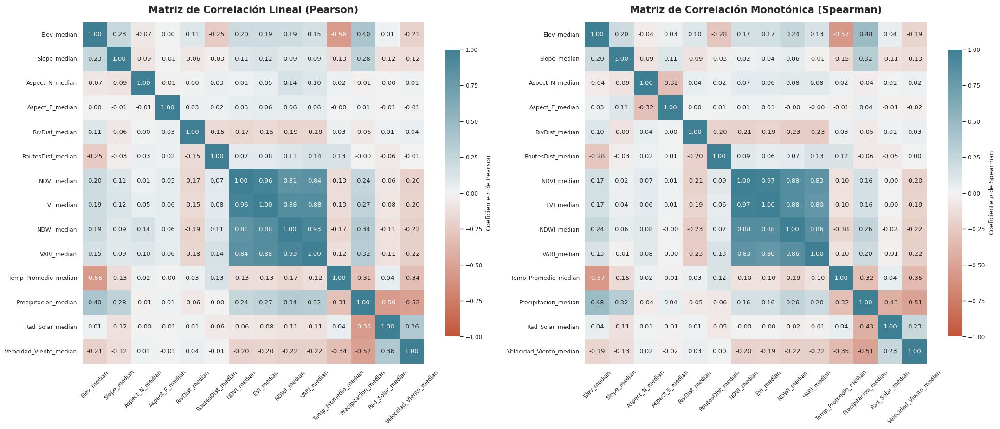

   ├─ ✅ Matrices de correlación exportadas exitosamente en:
        /content/drive/MyDrive/tesismsif_assets/13_Matrices_Correlacion_X.png
   ├─ Evaluando Factor de Inflación de la Varianza (VIF)...
   └─ ✅ Tabla VIF calculada y exportada en:
        /content/drive/MyDrive/tesismsif_assets/14_Auditoria_Multicolinealidad_VIF.csv

================ RESUMEN DE MULTICOLINEALIDAD ================


,Variable_Predictora,VIF_Score
8,EVI_median,21.200659
7,NDVI_median,15.136763
9,NDWI_median,9.931647
10,VARI_median,9.210029
11,Temp_Promedio_median,3.120426
12,Precipitacion_median,2.972427
14,Velocidad_Viento_median,2.911910
1,Elev_median,2.434690
13,Rad_Solar_median,1.673385
2,Slope_median,1.129679



⚠️ ATENCIÓN: Las siguientes variables exceden el umbral crítico (VIF > 10):
   ['EVI_median', 'NDVI_median']
   -> Sugerencia: Elimine iterativamente la de mayor VIF y recalcule, o delege la discriminación al Random Forest.


In [ ]:
# ==============================================================================
# TÍTULO: ANÁLISIS DE MULTICOLINEALIDAD Y SELECCIÓN DE VARIABLES (VIF)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Generación de matrices de correlación (Pearson/Spearman) y
#              cálculo corregido del Factor de Inflación de la Varianza (VIF).
# ==============================================================================

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import os

def analizar_multicolinealidad(df_entrenamiento: pd.DataFrame, columnas_X: list, ruta_drive_exportacion: str):
    """
    Evalúa la colinealidad bivariada y multivariada del espacio de características.
    Exporta matrices de calor de alta resolución y el reporte VIF.
    """
    print("\n⏳ Inicializando análisis de redundancia estadística...")

    # 1. AISLAMIENTO DEL ESPACIO DE CARACTERÍSTICAS (X)
    X_analisis = df_entrenamiento[columnas_X]
    os.makedirs(ruta_drive_exportacion, exist_ok=True)

    # ==========================================================================
    # 2. MATRICES DE CORRELACIÓN (BIVARIADA)
    # ==========================================================================
    print("   ├─ Calculando coeficientes de correlación (Pearson y Spearman)...")
    sns.set_theme(style="white", context="paper")
    fig, axes = plt.subplots(1, 2, figsize=(22, 9))

    # Configuración de mapa de color divergente científico
    cmap_cientifico = sns.diverging_palette(20, 220, as_cmap=True)

    # 2.1 Correlación Lineal (Pearson)
    corr_pearson = X_analisis.corr(method='pearson')
    sns.heatmap(corr_pearson, annot=True, cmap=cmap_cientifico, fmt=".2f",
                vmin=-1, vmax=1, ax=axes[0], square=True,
                cbar_kws={"shrink": .8, 'label': 'Coeficiente $r$ de Pearson'})
    axes[0].set_title('Matriz de Correlación Lineal (Pearson)', fontsize=15, fontweight='bold', pad=15)
    axes[0].tick_params(axis='x', rotation=45)

    # 2.2 Correlación Monotónica (Spearman)
    corr_spearman = X_analisis.corr(method='spearman')
    sns.heatmap(corr_spearman, annot=True, cmap=cmap_cientifico, fmt=".2f",
                vmin=-1, vmax=1, ax=axes[1], square=True,
                cbar_kws={"shrink": .8, 'label': 'Coeficiente $\\rho$ de Spearman'})
    axes[1].set_title('Matriz de Correlación Monotónica (Spearman)', fontsize=15, fontweight='bold', pad=15)
    axes[1].tick_params(axis='x', rotation=45)

    plt.tight_layout()

    # Exportación del Heatmap
    ruta_figura = os.path.join(ruta_drive_exportacion, '13_Matrices_Correlacion_X.png')
    fig.savefig(ruta_figura, dpi=600, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)
    print(f"   ├─ ✅ Matrices de correlación exportadas exitosamente en:\n        {ruta_figura}")

    # ==========================================================================
    # 3. FACTOR DE INFLACIÓN DE LA VARIANZA (MULTIVARIADA)
    # ==========================================================================
    print("   ├─ Evaluando Factor de Inflación de la Varianza (VIF)...")

    # CORRECCIÓN METODOLÓGICA CRÍTICA: Añadir constante (Intercepto)
    # Sin esto, statsmodels asume que la regresión pasa por el origen (0,0),
    # disparando el VIF de variables que no están centradas.
    X_con_constante = sm.add_constant(X_analisis)

    vif_data = pd.DataFrame()
    vif_data["Variable_Predictora"] = X_con_constante.columns
    vif_data["VIF_Score"] = [variance_inflation_factor(X_con_constante.values, i)
                             for i in range(X_con_constante.shape[1])]

    # Limpiamos el intercepto artificial de los resultados y ordenamos
    vif_data = vif_data[vif_data["Variable_Predictora"] != "const"].sort_values(by="VIF_Score", ascending=False)

    # Exportación tabular
    ruta_csv_vif = os.path.join(ruta_drive_exportacion, '14_Auditoria_Multicolinealidad_VIF.csv')
    vif_data.to_csv(ruta_csv_vif, index=False)
    print(f"   └─ ✅ Tabla VIF calculada y exportada en:\n        {ruta_csv_vif}")

    print("\n================ RESUMEN DE MULTICOLINEALIDAD ================")
    display(vif_data)

    # Alerta automatizada
    variables_peligro = vif_data[vif_data["VIF_Score"] > 10]["Variable_Predictora"].tolist()
    if variables_peligro:
        print(f"\n⚠️ ATENCIÓN: Las siguientes variables exceden el umbral crítico (VIF > 10):")
        print(f"   {variables_peligro}")
        print("   -> Sugerencia: Elimine iterativamente la de mayor VIF y recalcule, o delege la discriminación al Random Forest.")
    else:
        print("\n✅ Excelente: Ninguna variable excede el umbral de multicolinealidad severa (VIF < 10).")

    return corr_pearson, corr_spearman, vif_data

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    # Parametrización
    RUTA_DRIVE_EXPORT = '/content/drive/MyDrive/tesismsif_assets'

    COLUMNAS_X = [
        'Elev_median', 'Slope_median', 'Aspect_N_median', 'Aspect_E_median',
        'RivDist_median', 'RoutesDist_median', 'NDVI_median', 'EVI_median',
        'NDWI_median', 'VARI_median', 'Temp_Promedio_median',
        'Precipitacion_median', 'Rad_Solar_median', 'Velocidad_Viento_median'
    ]

    # Se asume la existencia de df_final en memoria (matriz maestra 500m)
    if 'df_modelo_final' in globals():
        _, _, df_vif_resultados = analizar_multicolinealidad(
            df_entrenamiento=df_modelo_final,
            columnas_X=COLUMNAS_X,
            ruta_drive_exportacion=RUTA_DRIVE_EXPORT
        )
    else:
        print("❌ Error: 'df_final' no encontrado. Ejecute el bloque de consolidación primero.")

## 5.2.15 Modelamiento Espacial mediante Random Forest Regressor

Para el aprendizaje de los patrones que rigen la ocurrencia de fuego, se seleccionó el algoritmo de aprendizaje automático supervisado *Random Forest* (Breiman, 2001). Dado que el objetivo final de la investigación es estimar la **probabilidad continua** de incendio (susceptibilidad) y no realizar una segmentación rígida del territorio, se implementó la variante de regresión (*Random Forest Regressor*) en lugar del clasificador categórico estándar (Assouline et al., 2021).

En este enfoque, la predicción de la susceptibilidad ($S_x$) para un píxel dado ($x$) se calcula como el promedio de las predicciones de los $N$ árboles de decisión ($h_i$) que conforman el ensamble:

$$S_x = \frac{1}{N} \sum_{i=1}^{N} h_i(x) \quad \text{donde} \quad S_x \in [0, 1]$$

La matriz de entrenamiento se subdividió aleatoriamente bajo un esquema estratificado, reservando el 70% de las observaciones para la calibración de los hiperplanos y el 30% restante para la validación independiente (*Hold-out validation*). El algoritmo fue parametrizado con un bosque de 150 estimadores (`n_estimators`) y una profundidad máxima de crecimiento logarítmico (`max_depth=15`) para prevenir el sobreajuste (*overfitting*).

Para evaluar la capacidad discriminante del modelo en la validación cruzada, las predicciones continuas se binarizaron utilizando un umbral $\ge 0.5$. Se estimó la matriz de confusión evaluando los Verdaderos Positivos ($TP$), Verdaderos Negativos ($TN$), Falsos Positivos ($FP$) y Falsos Negativos ($FN$). A partir de esta, se calcularon las métricas de rendimiento estandarizadas para evaluación de modelos en geomática (Poveda et al., 2022):

1. **Exactitud (Accuracy):** Proporción global de clasificaciones correctas.
   $$Accuracy = \frac{TP + TN}{TP + TN + FP + FN}$$

2. **Precisión (Precision):** Probabilidad de que una alerta de incendio sea real.
   $$Precision = \frac{TP}{TP + FP}$$

3. **Sensibilidad (Recall):** Fracción de los incendios reales que el modelo logró detectar.
   $$Recall = \frac{TP}{TP + FN}$$

4. **F1-Score:** Media armónica entre la precisión y la sensibilidad.
   $$F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}$$

Finalmente, el rendimiento discriminatorio general independientemente del umbral se cuantificó mediante el Área Bajo la Curva de la característica operativa del receptor (**ROC-AUC**).


⏳ V1 Inicializando partición de datos y entrenamiento del modelo...
   ├─ Dimensiones del conjunto de Entrenamiento (Train): (192549, 14)
   ├─ Dimensiones del conjunto de Prueba (Test): (82521, 14)
   ├─ Ajustando hiperplanos del Random Forest Regressor...

================ RESUMEN DE RENDIMIENTO (CONJUNTO TEST) ================
 ROC-AUC                  : 0.8724
 Exactitud (Accuracy)     : 0.7897
 Precisión (Precision)    : 0.7711
 Sensibilidad (Recall)    : 0.8239
 F1-Score                 : 0.7966

   ├─ Reporte de Clasificación Detallado:
              precision    recall  f1-score   support

           0       0.81      0.76      0.78     41261
           1       0.77      0.82      0.80     41260

    accuracy                           0.79     82521
   macro avg       0.79      0.79      0.79     82521
weighted avg       0.79      0.79      0.79     82521


📈 Importancia Relativa de las Variables (Feature Importance):


,Variable_Predictora,Importancia_Gini
8,NDWI_median,0.279566
10,Temp_Promedio_median,0.106977
12,Rad_Solar_median,0.097279
13,Velocidad_Viento_median,0.089425
11,Precipitacion_median,0.080778
7,EVI_median,0.080751
0,Elev_median,0.050530
9,VARI_median,0.050395
6,NDVI_median,0.045059
5,RoutesDist_median,0.031298


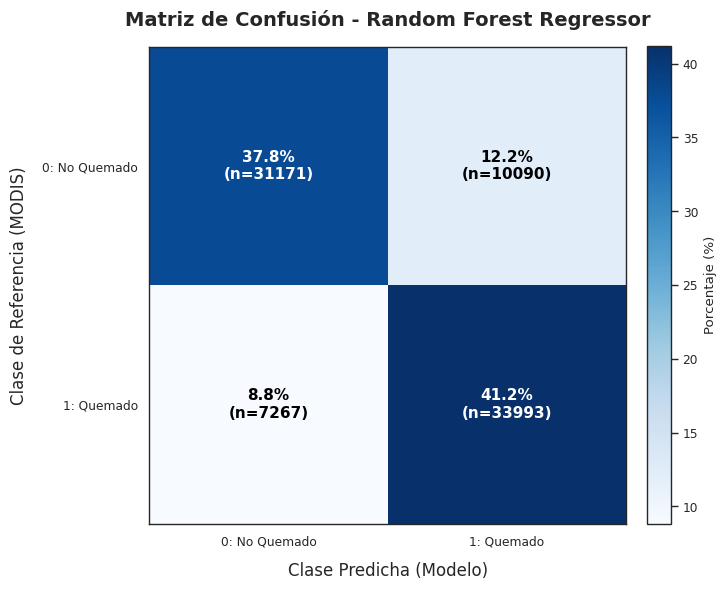


✅ Artefactos (Modelo .pkl, Gráficas y Tablas) exportados exitosamente en:
 - /content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/

⏳ V2 Inicializando partición de datos y entrenamiento del modelo...
   ├─ Dimensiones del conjunto de Entrenamiento (Train): (192549, 13)
   ├─ Dimensiones del conjunto de Prueba (Test): (82521, 13)
   ├─ Ajustando hiperplanos del Random Forest Regressor...

================ RESUMEN DE RENDIMIENTO (CONJUNTO TEST) ================
 ROC-AUC                  : 0.8710
 Exactitud (Accuracy)     : 0.7852
 Precisión (Precision)    : 0.7663
 Sensibilidad (Recall)    : 0.8207
 F1-Score                 : 0.7926

   ├─ Reporte de Clasificación Detallado:
              precision    recall  f1-score   support

           0       0.81      0.75      0.78     41261
           1       0.77      0.82      0.79     41260

    accuracy                           0.79     82521
   macro avg       0.79      0.79      0.78     82521
weighted avg       0.79      0.

,Variable_Predictora,Importancia_Gini
7,NDWI_median,0.289480
9,Temp_Promedio_median,0.112169
11,Rad_Solar_median,0.103347
12,Velocidad_Viento_median,0.092702
10,Precipitacion_median,0.086441
6,NDVI_median,0.084749
0,Elev_median,0.053086
8,VARI_median,0.052062
5,RoutesDist_median,0.033871
1,Slope_median,0.030706


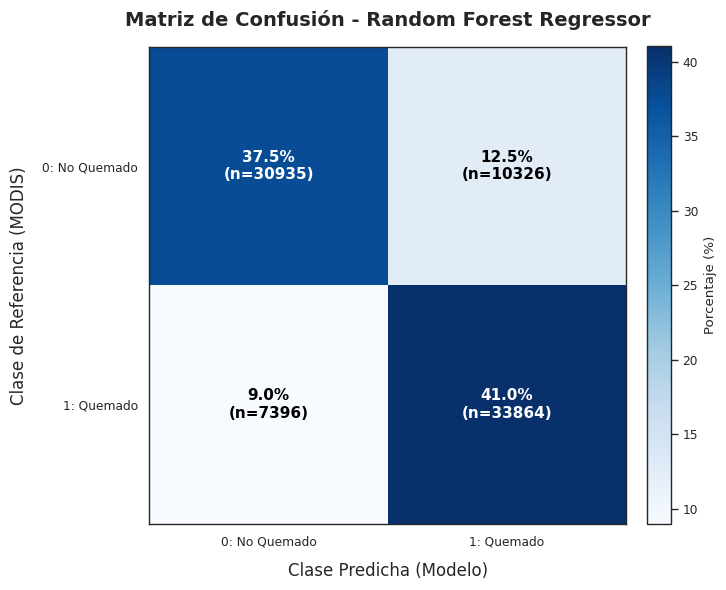


✅ Artefactos (Modelo .pkl, Gráficas y Tablas) exportados exitosamente en:
 - /content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/

⏳ V3 Inicializando partición de datos y entrenamiento del modelo...
   ├─ Dimensiones del conjunto de Entrenamiento (Train): (192549, 13)
   ├─ Dimensiones del conjunto de Prueba (Test): (82521, 13)
   ├─ Ajustando hiperplanos del Random Forest Regressor...

================ RESUMEN DE RENDIMIENTO (CONJUNTO TEST) ================
 ROC-AUC                  : 0.8726
 Exactitud (Accuracy)     : 0.7890
 Precisión (Precision)    : 0.7701
 Sensibilidad (Recall)    : 0.8241
 F1-Score                 : 0.7962

   ├─ Reporte de Clasificación Detallado:
              precision    recall  f1-score   support

           0       0.81      0.75      0.78     41261
           1       0.77      0.82      0.80     41260

    accuracy                           0.79     82521
   macro avg       0.79      0.79      0.79     82521
weighted avg       0.79      0.

,Variable_Predictora,Importancia_Gini
7,NDWI_median,0.283940
9,Temp_Promedio_median,0.115569
11,Rad_Solar_median,0.106905
12,Velocidad_Viento_median,0.097033
10,Precipitacion_median,0.088216
6,EVI_median,0.084500
0,Elev_median,0.052729
8,VARI_median,0.042825
5,RoutesDist_median,0.033609
1,Slope_median,0.029454


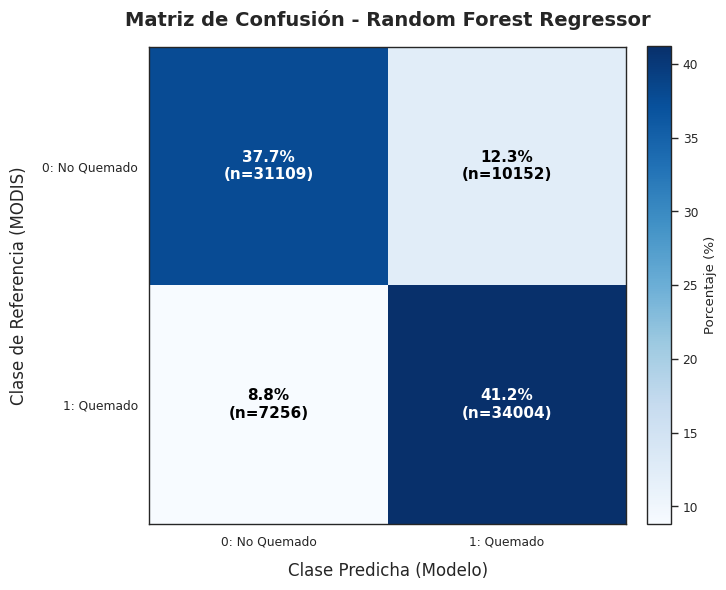


✅ Artefactos (Modelo .pkl, Gráficas y Tablas) exportados exitosamente en:
 - /content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/

⏳ V4 Inicializando partición de datos y entrenamiento del modelo...
   ├─ Dimensiones del conjunto de Entrenamiento (Train): (192549, 12)
   ├─ Dimensiones del conjunto de Prueba (Test): (82521, 12)
   ├─ Ajustando hiperplanos del Random Forest Regressor...

================ RESUMEN DE RENDIMIENTO (CONJUNTO TEST) ================
 ROC-AUC                  : 0.8726
 Exactitud (Accuracy)     : 0.7886
 Precisión (Precision)    : 0.7670
 Sensibilidad (Recall)    : 0.8291
 F1-Score                 : 0.7968

   ├─ Reporte de Clasificación Detallado:
              precision    recall  f1-score   support

           0       0.81      0.75      0.78     41261
           1       0.77      0.83      0.80     41260

    accuracy                           0.79     82521
   macro avg       0.79      0.79      0.79     82521
weighted avg       0.79      0.

,Variable_Predictora,Importancia_Gini
6,NDWI_median,0.298558
8,Temp_Promedio_median,0.121741
10,Rad_Solar_median,0.117981
11,Velocidad_Viento_median,0.103449
9,Precipitacion_median,0.100801
0,Elev_median,0.062521
5,RoutesDist_median,0.043869
7,VARI_median,0.042974
4,RivDist_median,0.035371
1,Slope_median,0.031821


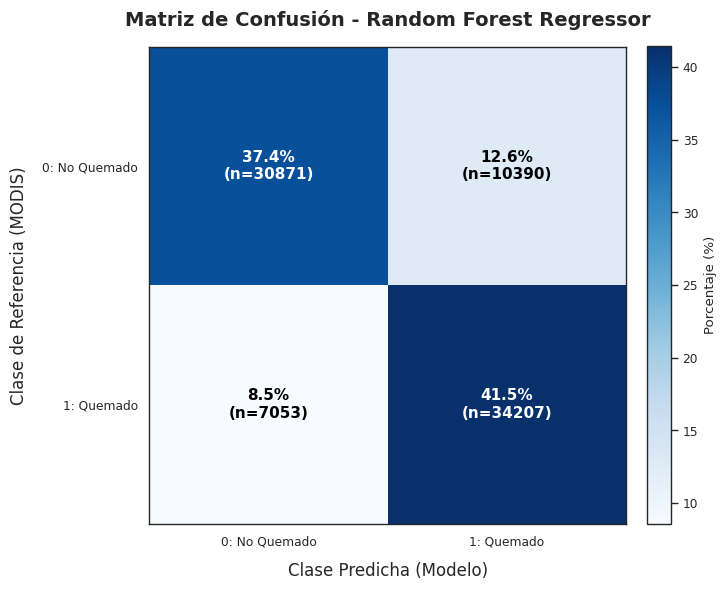


✅ Artefactos (Modelo .pkl, Gráficas y Tablas) exportados exitosamente en:
 - /content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/


In [ ]:
# ==============================================================================
# TÍTULO: ENTRENAMIENTO Y EVALUACIÓN DEL RANDOM FOREST REGRESSOR (RFR)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Partición estratificada, ajuste del modelo para estimación de
#              susceptibilidad [0, 1], evaluación de métricas y exportación.
# ==============================================================================

import os
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_auc_score)

def entrenar_evaluar_random_forest(df_modelo: pd.DataFrame, columnas_X: list, variable_y: str, rutas_export: dict, version: str):
    """
    Entrena un RFR para estimar la probabilidad de incendio, calcula las métricas
    de rendimiento en el conjunto de prueba y exporta los artefactos generados.
    """
    print(f"\n⏳ {version} Inicializando partición de datos y entrenamiento del modelo...")

    # 1. PARTICIÓN ESTRATIFICADA (70% Train, 30% Test)
    X = df_modelo[columnas_X]
    y = df_modelo[variable_y]

    X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )

    print("   ├─ Dimensiones del conjunto de Entrenamiento (Train):", X_entrenamiento.shape)
    print("   ├─ Dimensiones del conjunto de Prueba (Test):", X_prueba.shape)

    # 2. INSTANCIACIÓN Y ENTRENAMIENTO DEL RANDOM FOREST REGRESSOR
    # n_jobs=-1 utiliza todos los núcleos del procesador disponibles
    print("   ├─ Ajustando hiperplanos del Random Forest Regressor...")
    modelo_rfr = RandomForestRegressor(
        n_estimators=150,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    )
    modelo_rfr.fit(X_entrenamiento, y_entrenamiento)

    # 3. PREDICCIONES Y UMBRALIZACIÓN (Thresholding)
    # RFR devuelve probabilidades continuas [0, 1]. Se binarizan con umbral 0.5.
    y_probabilidades = modelo_rfr.predict(X_prueba)
    y_prediccion_binaria = (y_probabilidades >= 0.5).astype(int)

    # 4. CÁLCULO DE MÉTRICAS DE DESEMPEÑO
    metricas = {
        'ROC-AUC': roc_auc_score(y_prueba, y_probabilidades),
        'Exactitud (Accuracy)': accuracy_score(y_prueba, y_prediccion_binaria),
        'Precisión (Precision)': precision_score(y_prueba, y_prediccion_binaria),
        'Sensibilidad (Recall)': recall_score(y_prueba, y_prediccion_binaria),
        'F1-Score': f1_score(y_prueba, y_prediccion_binaria)
    }

    print("\n================ RESUMEN DE RENDIMIENTO (CONJUNTO TEST) ================")
    for metrica, valor in metricas.items():
        print(f" {metrica:<25}: {valor:.4f}")
    print("========================================================================\n")

    print("   ├─ Reporte de Clasificación Detallado:")
    print(classification_report(y_prueba, y_prediccion_binaria))

    # 5. MATRIZ DE CONFUSIÓN (Visualización Científica)
    matriz_conf = confusion_matrix(y_prueba, y_prediccion_binaria)
    matriz_porcentajes = matriz_conf / matriz_conf.sum() * 100

    fig_matriz, ax = plt.subplots(figsize=(7, 6))
    imagen_matriz = ax.imshow(matriz_porcentajes, interpolation="nearest", cmap="Blues")
    ax.set_title("Matriz de Confusión - Random Forest Regressor", fontsize=14, pad=15, fontweight='bold')
    ax.set_xlabel("Clase Predicha (Modelo)", fontsize=12, labelpad=10)
    ax.set_ylabel("Clase de Referencia (MODIS)", fontsize=12, labelpad=10)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["0: No Quemado", "1: Quemado"])
    ax.set_yticklabels(["0: No Quemado", "1: Quemado"])

    # Anotaciones numéricas dentro de las celdas
    umbral_color = matriz_porcentajes.max() / 2.0
    for i in range(matriz_conf.shape[0]):
        for j in range(matriz_conf.shape[1]):
            texto_celda = f"{matriz_porcentajes[i, j]:.1f}%\n(n={matriz_conf[i, j]})"
            ax.text(j, i, texto_celda, ha="center", va="center",
                    color="white" if matriz_porcentajes[i, j] > umbral_color else "black",
                    fontsize=11, fontweight='bold')

    plt.colorbar(imagen_matriz, ax=ax, fraction=0.046, pad=0.04, label='Porcentaje (%)')
    plt.tight_layout()

    # 6. EXTRACCIÓN DE IMPORTANCIA DE VARIABLES (Decrease in Impurity)
    df_importancia = None
    df_importancia = pd.DataFrame({
        "Variable_Predictora": columnas_X,
        "Importancia_Gini": modelo_rfr.feature_importances_
    }).sort_values(by="Importancia_Gini", ascending=False)

    print("\n📈 Importancia Relativa de las Variables (Feature Importance):")
    display(df_importancia)

    # 7. EXPORTACIÓN DE ARTEFACTOS
    os.makedirs(rutas_export['local_dir'], exist_ok=True)
    os.makedirs(rutas_export['drive_dir'], exist_ok=True)

    # Guardar Matriz de Confusión
    ruta_png_local = os.path.join(rutas_export['local_dir'], f"15_RF_Matriz_Confusion{version}.png")
    ruta_png_drive = os.path.join(rutas_export['drive_dir'], f"15_RF_Matriz_Confusion{version}.png")
    fig_matriz.savefig(ruta_png_local, dpi=600, bbox_inches="tight", facecolor="white")
    shutil.copy(ruta_png_local, ruta_png_drive)

    plt.show()
    plt.close(fig_matriz)

    # Guardar Importancia de Variables (CSV)
    ruta_csv_local = os.path.join(rutas_export['local_dir'], f"16_RF_Importancia_Variables{version}.csv")
    ruta_csv_drive = os.path.join(rutas_export['drive_dir'], f"16_RF_Importancia_Variables{version}.csv")
    df_importancia.to_csv(ruta_csv_local, index=False)
    shutil.copy(ruta_csv_local, ruta_csv_drive)

    # Serializar Modelo Entrenado (Joblib)
    ruta_modelo_local = os.path.join(rutas_export['local_dir'], f"RF_Modelo_Susceptibilidad_Vichada{version}.pkl")
    ruta_modelo_drive = os.path.join(rutas_export['drive_dir'], f"RF_Modelo_Susceptibilidad_Vichada{version}.pkl")
    joblib.dump(modelo_rfr, ruta_modelo_local)
    shutil.copy(ruta_modelo_local, ruta_modelo_drive)

    print(f"\n✅ Artefactos (Modelo .pkl, Gráficas y Tablas) exportados exitosamente en:\n - {rutas_export['drive_dir']}")

    return modelo_rfr, df_importancia, X_prueba, y_prueba, y_probabilidades, X_entrenamiento, y_entrenamiento

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    RUTAS_SALIDA = {
        'local_dir': '/content/datos_entrenamiento/',
        'drive_dir': '/content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/'
    }

    # Definir variables predictoras excluyendo las que tienen VIF > 10 (EVI_median, NDVI_median)
    columnas_predictorasV1 = [
        'Elev_median', 'Slope_median', 'Aspect_N_median', 'Aspect_E_median',
        'RivDist_median', 'RoutesDist_median', 'NDVI_median', 'EVI_median', 'NDWI_median', 'VARI_median',
        'Temp_Promedio_median', 'Precipitacion_median', 'Rad_Solar_median',
        'Velocidad_Viento_median'
    ]

    columnas_predictorasV2 = [
        'Elev_median', 'Slope_median', 'Aspect_N_median', 'Aspect_E_median',
        'RivDist_median', 'RoutesDist_median', 'NDVI_median', 'NDWI_median', 'VARI_median',
        'Temp_Promedio_median', 'Precipitacion_median', 'Rad_Solar_median',
        'Velocidad_Viento_median'
    ]

    columnas_predictorasV3 = [
        'Elev_median', 'Slope_median', 'Aspect_N_median', 'Aspect_E_median',
        'RivDist_median', 'RoutesDist_median', 'EVI_median', 'NDWI_median', 'VARI_median',
        'Temp_Promedio_median', 'Precipitacion_median', 'Rad_Solar_median',
        'Velocidad_Viento_median'
    ]

    columnas_predictorasV4 = [
        'Elev_median', 'Slope_median', 'Aspect_N_median', 'Aspect_E_median',
        'RivDist_median', 'RoutesDist_median', 'NDWI_median', 'VARI_median',
        'Temp_Promedio_median', 'Precipitacion_median', 'Rad_Solar_median',
        'Velocidad_Viento_median'
    ]

    if 'df_modelo_final' in globals():# and 'ruta_modelo_local' in globals():
        # Desempaquetamos los 4 valores retornados por la función
        modelo_entrenado_v1, importancia_rf_v1, X_test_v1, y_test_v1, y_proba_v1, X_train_v1, y_train_v1 = entrenar_evaluar_random_forest(
            df_modelo=df_modelo_final,
            columnas_X=columnas_predictorasV1,
            variable_y='Quemado_Binario',
            rutas_export=RUTAS_SALIDA,
            version="V1"
        )

        modelo_entrenado_v2, importancia_rf_v2, X_test_v2, y_test_v2, y_proba_v2, X_train_v2, y_train_v2 = entrenar_evaluar_random_forest(
            df_modelo=df_modelo_final,
            columnas_X=columnas_predictorasV2,
            variable_y='Quemado_Binario',
            rutas_export=RUTAS_SALIDA,
            version="V2"
        )

        modelo_entrenado_v3, importancia_rf_v3, X_test_v3, y_test_v3, y_proba_v3, X_train_v3, y_train_v3 = entrenar_evaluar_random_forest(
            df_modelo=df_modelo_final,
            columnas_X=columnas_predictorasV3,
            variable_y='Quemado_Binario',
            rutas_export=RUTAS_SALIDA,
            version="V3"
        )

        modelo_entrenado_v4, importancia_rf_v4, X_test_v4, y_test_v4, y_proba_v4, X_train_v4, y_train_v4 = entrenar_evaluar_random_forest(
            df_modelo=df_modelo_final,
            columnas_X=columnas_predictorasV4,
            variable_y='Quemado_Binario',
            rutas_export=RUTAS_SALIDA,
            version="V4"
        )
    else:
        print("❌ Error: Matriz de entrenamiento no disponible.")


## 5.2.16 Evaluación Probabilística del Modelo y Calibración (Índice de Brier)

Dado que la función objetivo del *Random Forest Regressor* (RFR) en esta investigación es cuantificar la susceptibilidad como un espectro de probabilidad continua $S_x \in [0,1]$, la evaluación dicotómica tradicional (ej. Matriz de Confusión) resulta insuficiente para medir la "certeza" de las predicciones del algoritmo.

Para cuantificar la desviación de las probabilidades estimadas frente a los eventos empíricos observados ($y_i \in \{0,1\}$), se calcularon métricas de error de regresión clásicas. En escenarios de predicción probabilística de variables binarias, el Error Cuadrático Medio (MSE) converge algebraicamente con el **Índice de Brier** ($BS$) (Assouline et al., 2021), definido como:

$$ BS = MSE = \frac{1}{N} \sum_{i=1}^{N} (S_{x_i} - y_i)^2 $$

Un Índice de Brier cercano a $0$ indica una calibración perfecta, donde el modelo asigna probabilidades muy altas a los píxeles que efectivamente se quemaron, y probabilidades muy bajas a las sabanas intactas. Se calculó además la Raíz del Error Cuadrático Medio (RMSE) para penalizar severamente las predicciones probabilísticas de alta confianza que resultaron erróneas:

$$ RMSE = \sqrt{ \frac{1}{N} \sum_{i=1}^{N} (S_{x_i} - y_i)^2 } $$

Finalmente, para evaluar la magnitud del sesgo de estimación exclusivamente sobre los ecosistemas vulnerados, se adaptó la métrica del Error Porcentual Absoluto Medio (MAPE). Con el fin de evitar la indeterminación matemática por división entre cero inherente a las muestras intactas ($y_i=0$), el dominio de cálculo se restringió al subconjunto de píxeles con registro confirmado de fuego ($C_1$):

$$ MAPE_{fuego} = \frac{1}{N_{1}} \sum_{i \in C_1} \left| \frac{y_i - S_{x_i}}{y_i} \right| \times 100 $$

Esta métrica complementaria permitió corroborar que las estimaciones de susceptibilidad sobre las áreas que históricamente ardieron fueron consistentemente altas, garantizando la eficacia preventiva del modelo.

In [ ]:
# ==============================================================================
# TÍTULO: EVALUACIÓN DE INCERTIDUMBRE Y MÉTRICAS DE REGRESIÓN PROBABILÍSTICA
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Cálculo de errores absolutos, cuadráticos y score de Brier
#              sobre las probabilidades de susceptibilidad estimadas por el RFR.
# ==============================================================================

import os
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, brier_score_loss

def evaluar_metricas_probabilisticas(y_verdadero: np.ndarray, y_probabilidad: np.ndarray, rutas_export: dict):
    """
    Calcula y exporta métricas de ajuste continuo para evaluar la calibración
    de las probabilidades de susceptibilidad a incendios forestales.
    """
    print("\n⏳ Calculando métricas de error y calibración probabilística...")

    # 1. CÁLCULO DE MÉTRICAS GLOBALES
    mae = mean_absolute_error(y_verdadero, y_probabilidad)
    mse = mean_squared_error(y_verdadero, y_probabilidad)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_verdadero, y_probabilidad)

    # Índice de Brier (Validación cruzada del MSE en contextos binarios)
    brier = brier_score_loss(y_verdadero, y_probabilidad)

    # 2. CÁLCULO DE MÉTRICA FOCALIZADA (MAPE ADAPTADO)
    def mape_clase_positiva(y_true, y_pred):
        """
        Calcula el Error Absoluto Porcentual Medio exclusivamente para las
        observaciones donde realmente ocurrió fuego (Clase 1), evitando divisiones por cero.
        """
        y_true, y_pred = np.array(y_true), np.array(y_pred)
        mascara_fuego = (y_true == 1)
        # Como y_true es 1, la fórmula se simplifica a la diferencia absoluta porcentual
        return np.mean(np.abs(y_true[mascara_fuego] - y_pred[mascara_fuego])) * 100

    mape_fuego = mape_clase_positiva(y_verdadero, y_probabilidad)

    # 3. CONSOLIDACIÓN DE RESULTADOS
    df_metricas_reg = pd.DataFrame({
        'Métrica': [
            'MAE (Error Absoluto Medio)',
            'MSE (Error Cuadrático Medio)',
            'RMSE (Raíz del Error Cuadrático)',
            'Brier Score (Calibración)',
            'R² (Coef. de Determinación)',
            'MAPE Modificado (Solo Fuego %)'
        ],
        'Valor': [mae, mse, rmse, brier, r2, mape_fuego]
    })

    print("======================================================")
    print("      📊 MÉTRICAS DE AJUSTE DEL MODELO CONTINUO       ")
    print("======================================================")
    for index, row in df_metricas_reg.iterrows():
        unidad = "%" if "MAPE" in row['Métrica'] else ""
        print(f" {row['Métrica']:<35}: {row['Valor']:.4f}{unidad}")
    print("======================================================\n")

    # 4. EXPORTACIÓN DE TABLA DE MÉTRICAS
    os.makedirs(rutas_export['local_dir'], exist_ok=True)
    os.makedirs(rutas_export['drive_dir'], exist_ok=True)

    nombre_archivo = "17_Metricas_Regresion_Probabilistica_RF.csv"
    ruta_csv_local = os.path.join(rutas_export['local_dir'], nombre_archivo)
    ruta_csv_drive = os.path.join(rutas_export['drive_dir'], nombre_archivo)

    df_metricas_reg.to_csv(ruta_csv_local, index=False)

    # Copia de seguridad a Drive
    import shutil
    shutil.copy(ruta_csv_local, ruta_csv_drive)
    print(f"✅ Tabla de métricas exportada exitosamente en:\n - {ruta_csv_drive}")

    return df_metricas_reg

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    RUTAS_SALIDA = {
        'local_dir': '/content/datos_entrenamiento/',
        'drive_dir': '/content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/'
    }

    # Se asume que y_test y y_proba fueron calculados en el bloque anterior
    if 'y_test_v1' in globals() and 'y_proba_v1' in globals():
        metricas_continuasV1 = evaluar_metricas_probabilisticas(
            y_verdadero=y_test_v1,
            y_probabilidad=y_proba_v1,
            rutas_export=RUTAS_SALIDA
        )

        metricas_continuasV2 = evaluar_metricas_probabilisticas(
            y_verdadero=y_test_v2,
            y_probabilidad=y_proba_v2,
            rutas_export=RUTAS_SALIDA
        )

        metricas_continuasV3 = evaluar_metricas_probabilisticas(
            y_verdadero=y_test_v3,
            y_probabilidad=y_proba_v3,
            rutas_export=RUTAS_SALIDA
        )

        metricas_continuasV4 = evaluar_metricas_probabilisticas(
            y_verdadero=y_test_v4,
            y_probabilidad=y_proba_v4,
            rutas_export=RUTAS_SALIDA
        )
    else:
        print("❌ Error: Los vectores de validación (y_test, y_proba) no están en memoria.")


⏳ Calculando métricas de error y calibración probabilística...
      📊 MÉTRICAS DE AJUSTE DEL MODELO CONTINUO       
 MAE (Error Absoluto Medio)         : 0.3326
 MSE (Error Cuadrático Medio)       : 0.1528
 RMSE (Raíz del Error Cuadrático)   : 0.3909
 Brier Score (Calibración)          : 0.1528
 R² (Coef. de Determinación)        : 0.3889
 MAPE Modificado (Solo Fuego %)     : 32.9842%

✅ Tabla de métricas exportada exitosamente en:
 - /content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/17_Metricas_Regresion_Probabilistica_RF.csv

⏳ Calculando métricas de error y calibración probabilística...
      📊 MÉTRICAS DE AJUSTE DEL MODELO CONTINUO       
 MAE (Error Absoluto Medio)         : 0.3328
 MSE (Error Cuadrático Medio)       : 0.1530
 RMSE (Raíz del Error Cuadrático)   : 0.3912
 Brier Score (Calibración)          : 0.1530
 R² (Coef. de Determinación)        : 0.3879
 MAPE Modificado (Solo Fuego %)     : 33.0126%

✅ Tabla de métricas exportada exitosamente en:
 - /conten

## 5.2.17 Explicabilidad del Modelo: Importancia por Permutación

Para evitar el sesgo algorítmico inherente a las métricas de reducción de impureza (ej., Gini Impurity) durante la selección de nodos en los árboles de decisión, se implementó el método de **Importancia por Permutación** (*Permutation Feature Importance*). Esta métrica cuantifica la verdadera dependencia del modelo hacia cada variable predictora evaluando el deterioro del rendimiento predictivo cuando los valores de dicha variable son alterados aleatoriamente en un conjunto de datos no observados.

Matemáticamente, sea $s$ la métrica de referencia del modelo ajustado sobre el conjunto de validación $X_{test}$ e $y_{test}$ (en este caso, el Coeficiente de Determinación $R^2$). Para cada característica $j$, sus valores fueron permutados aleatoriamente para generar un conjunto de datos corrompido, sobre el cual se recalculó la métrica $s_{k,j}$ durante $K$ repeticiones. La Importancia por Permutación ($PI_j$) se define como la caída media del desempeño a lo largo de las $K$ iteraciones:

$$ PI_j = s - \frac{1}{K} \sum_{k=1}^{K} s_{k,j} $$

Si una variable es fundamental para la correcta modelación de la susceptibilidad espacial a incendios, la destrucción de su estructura topológica original provocará un colapso en el $R^2$ del ensamble, resultando en un alto valor de $PI_j$. Por el contrario, si la permutación no afecta significativamente el desempeño, la variable se considera marginal o redundante frente al resto de la matriz de predictores. El proceso se parametrizó con $K = 20$ repeticiones para asegurar la estabilidad estadística de las estimaciones y capturar la varianza empírica del error.


⏳ Calculando Importancia por Permutación (K=20 iteraciones)...

✅ Importancia empírica de variables (Orden descendente):


,Variable_Predictora,Disminucion_Media_R2,Desviacion_Estandar
8,NDWI_median,0.246454,0.002341
10,Temp_Promedio_median,0.167590,0.000756
12,Rad_Solar_median,0.144352,0.000670
13,Velocidad_Viento_median,0.129708,0.000945
7,EVI_median,0.111855,0.001056
11,Precipitacion_median,0.107799,0.000808
0,Elev_median,0.070526,0.000723
9,VARI_median,0.056428,0.000652
6,NDVI_median,0.054700,0.000798
1,Slope_median,0.054426,0.000872


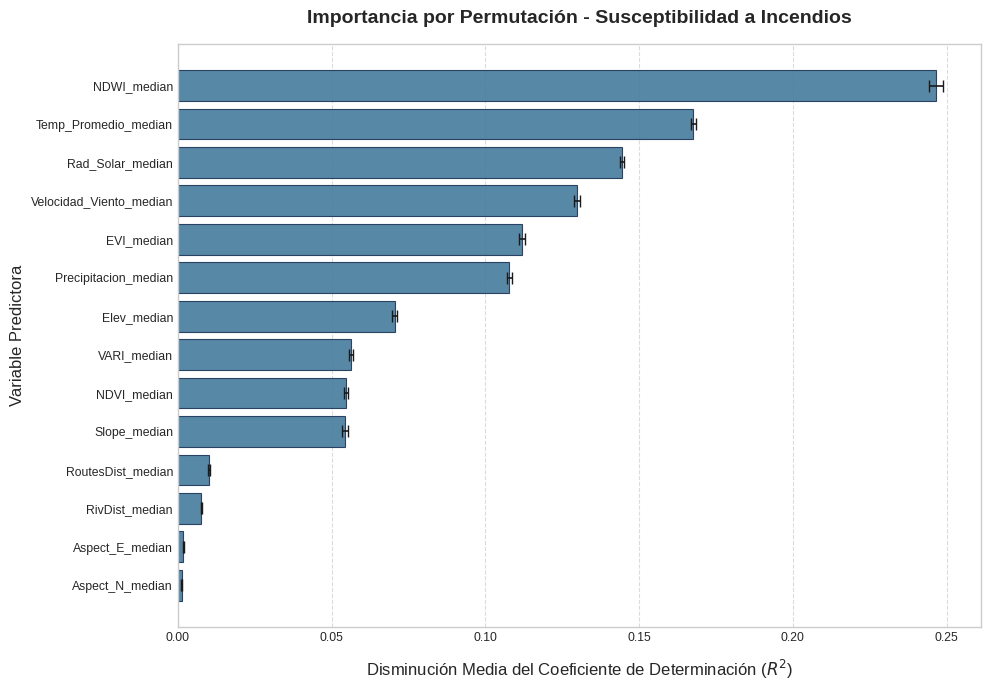


💾 Tabla y Figura exportadas exitosamente en:
 - /content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/


In [ ]:
# ==============================================================================
# TÍTULO: EXTRACCIÓN DE IMPORTANCIA DE VARIABLES POR PERMUTACIÓN
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Evaluación del impacto predictivo de cada covariable mediante
#              permutación aleatoria sobre el conjunto de validación independiente.
# ==============================================================================

import os
import shutil
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

def evaluar_importancia_permutacion(modelo, X_val, y_val, nombres_columnas: list, rutas_export: dict, repeticiones: int = 20):
    """
    Calcula, grafica y exporta la Importancia por Permutación de un modelo ajustado,
    midiendo la caída en el pseudo-R² al alterar aleatoriamente cada predictor.
    """
    print(f"\n⏳ Calculando Importancia por Permutación (K={repeticiones} iteraciones)...")

    # 1. CÁLCULO DE PERMUTACIÓN (Basado en R² para el Regresor)
    resultados_permutacion = permutation_importance(
        estimator=modelo,
        X=X_val,
        y=y_val,
        n_repeats=repeticiones,
        random_state=42,
        scoring='r2', # Se explicita R² para evitar advertencias de API
        n_jobs=-1
    )

    # 2. ESTRUCTURACIÓN DE RESULTADOS TABULARES
    df_permutacion = pd.DataFrame({
        "Variable_Predictora": nombres_columnas,
        "Disminucion_Media_R2": resultados_permutacion.importances_mean,
        "Desviacion_Estandar": resultados_permutacion.importances_std
    }).sort_values("Disminucion_Media_R2", ascending=False)

    print("\n✅ Importancia empírica de variables (Orden descendente):")
    display(df_permutacion)

    # 3. VISUALIZACIÓN CIENTÍFICA (Gráfico de Barras con Barras de Error)
    plt.style.use('seaborn-v0_8-whitegrid')
    fig_importancia, ax = plt.subplots(figsize=(10, 7))

    # Invertimos el orden para que la variable más importante aparezca arriba
    variables_plot = df_permutacion["Variable_Predictora"][::-1]
    medias_plot = df_permutacion["Disminucion_Media_R2"][::-1]
    errores_plot = df_permutacion["Desviacion_Estandar"][::-1]

    ax.barh(
        variables_plot,
        medias_plot,
        xerr=errores_plot,
        color='#457B9D',
        edgecolor='#1D3557',
        capsize=4,
        alpha=0.9
    )

    ax.set_xlabel("Disminución Media del Coeficiente de Determinación ($R^2$)", fontsize=12, labelpad=10)
    ax.set_ylabel("Variable Predictora", fontsize=12)
    ax.set_title("Importancia por Permutación - Susceptibilidad a Incendios", fontsize=14, fontweight='bold', pad=15)

    # Formato de cuadrícula sutil
    ax.xaxis.grid(True, linestyle='--', alpha=0.7)
    ax.yaxis.grid(False)
    plt.tight_layout()

    # 4. EXPORTACIÓN DE ARTEFACTOS
    os.makedirs(rutas_export['local_dir'], exist_ok=True)
    os.makedirs(rutas_export['drive_dir'], exist_ok=True)

    # Exportación Tabular (CSV)
    nombre_csv = "18_RF_Permutation_Importance.csv"
    ruta_csv_local = os.path.join(rutas_export['local_dir'], nombre_csv)
    ruta_csv_drive = os.path.join(rutas_export['drive_dir'], nombre_csv)

    df_permutacion.to_csv(ruta_csv_local, index=False)
    shutil.copy(ruta_csv_local, ruta_csv_drive)

    # Exportación Gráfica (PNG, 600 dpi)
    nombre_png = "18_RF_Permutation_Importance.png"
    ruta_png_local = os.path.join(rutas_export['local_dir'], nombre_png)
    ruta_png_drive = os.path.join(rutas_export['drive_dir'], nombre_png)

    fig_importancia.savefig(ruta_png_local, dpi=600, bbox_inches="tight", facecolor="white")
    shutil.copy(ruta_png_local, ruta_png_drive)

    plt.show()
    plt.close(fig_importancia)

    print(f"\n💾 Tabla y Figura exportadas exitosamente en:\n - {rutas_export['drive_dir']}")

    return df_permutacion

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    RUTAS_SALIDA = {
        'local_dir': '/content/datos_entrenamiento/',
        'drive_dir': '/content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/'
    }

    # Se asume que rf_model, X_test, y_test y columnas_predictoras existen en memoria
    if 'modelo_entrenado_v1' in globals() and 'X_test_v1' in globals():
        importancia_permutacion_df = evaluar_importancia_permutacion(
            modelo=modelo_entrenado_v1,
            X_val=X_test_v1,
            y_val=y_test_v1,
            nombres_columnas=columnas_predictorasV1,
            rutas_export=RUTAS_SALIDA,
            repeticiones=20
        )
    else:
        print("❌ Error: Modelo o conjunto de prueba no encontrados en memoria.")

## 5.2.18 Interpretación Avanzada y Dirección del Efecto Predictivo (SHAP)

Para trascender la mera cuantificación de importancia y comprender el mecanismo ecológico subyacente que el modelo capturó, se aplicó el marco unificado de explicabilidad **SHAP** (*SHapley Additive exPlanations*) (Lundberg & Lee, 2017). Esta metodología, fundamentada en la Teoría de Juegos Cooperativos, distribuye el pago total (la predicción del modelo) entre los jugadores (las variables predictoras) de manera matemáticamente equitativa.

Para un modelo predictivo $f$ y un conjunto de características $N$, el valor de Shapley ($\phi_i$) asignado a la variable $i$ para una observación específica $x$ se calcula considerando todas las coaliciones posibles de variables $S$ que no contienen a $i$:

$$\phi_i = \sum_{S \subseteq N \setminus \{i\}} \frac{\vert{}S\vert{}! (\vert{}N\vert{} - \vert{}S\vert{} - 1)!}{\vert{}N\vert{}!} \left[ f_x(S \cup \{i\}) - f_x(S) \right]$$

Donde $f_x(S)$ representa el valor esperado de la predicción condicionada al subconjunto de características $S$. Para mantener la tratabilidad computacional sobre el ensamble de árboles del *Random Forest*, se empleó el algoritmo `TreeExplainer`, calculando los valores SHAP sobre una submuestra representativa ($n=1000$) del conjunto de validación independiente.

La agregación de las contribuciones marginales absolutas $\left( \frac{1}{n} \sum \vert{} \phi_i \vert{} \right)$ permitió establecer una jerarquía global de impacto (SHAP Global). Adicionalmente, se generó un gráfico de dispersión de resumen (*SHAP Summary Beeswarm Plot*), el cual proyecta bidimensionalmente la magnitud del impacto en la predicción (eje X) frente a la magnitud del valor original de la característica (codificada en una rampa de color termodinámica). Esta representación visual posibilita diagnosticar relaciones no lineales, identificando, por ejemplo, si valores altos de precipitación reducen invariablemente la probabilidad de ignición, o si valores atípicos de la distancia a vías actúan como detonadores primarios del fuego.


⏳ Inicializando análisis SHAP sobre submuestra de validación (N=1000)...
   ├─ Calculando contribuciones marginales (TreeExplainer)...

✅ Importancia de Variables (SHAP Global):


,Variable_Predictora,SHAP_Absoluto_Medio
8,NDWI_median,0.100685
7,EVI_median,0.047486
10,Temp_Promedio_median,0.034425
1,Slope_median,0.028943
12,Rad_Solar_median,0.023348
13,Velocidad_Viento_median,0.022097
6,NDVI_median,0.020074
0,Elev_median,0.019224
11,Precipitacion_median,0.018739
9,VARI_median,0.016854


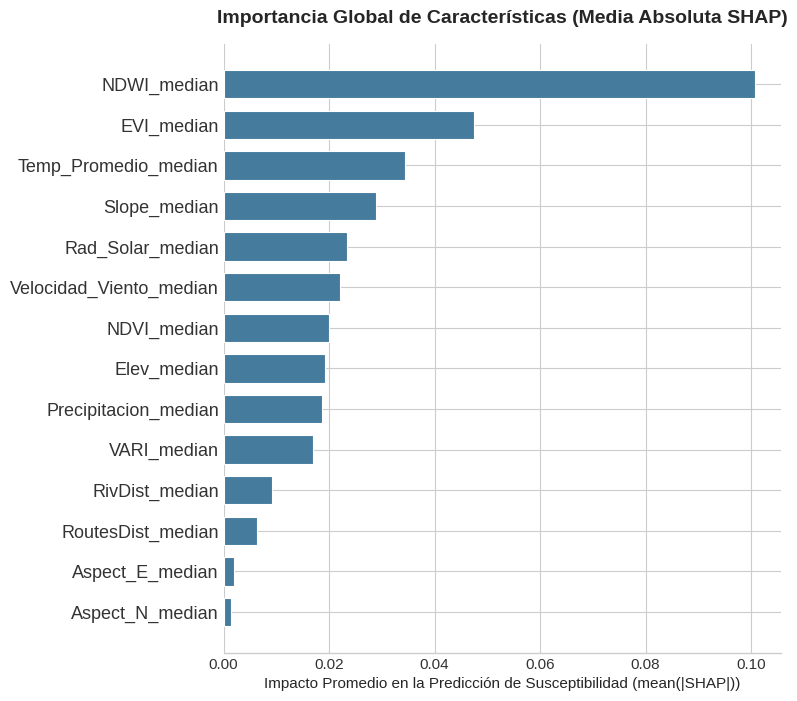

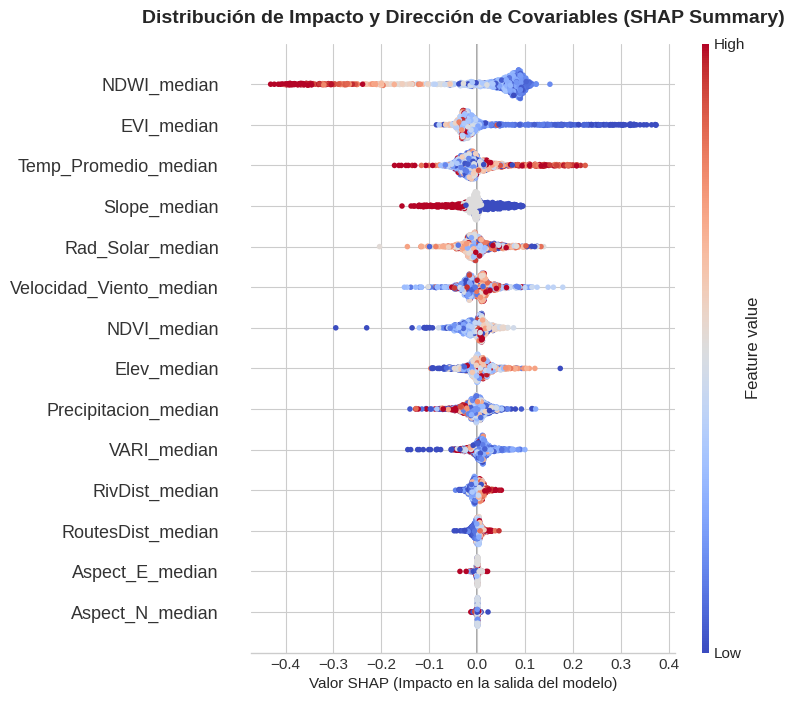


💾 Artefactos SHAP (Tabla y Figuras x2 a 600dpi) guardados en:
 - /content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/


In [ ]:
# ==============================================================================
# TÍTULO: EXPLICABILIDAD DEL MODELO MEDIANTE VALORES SHAP (XAI)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Cálculo de contribuciones marginales de características mediante
#              SHAP (Global y Beeswarm) sobre el conjunto de validación.
# ==============================================================================

import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
import shutil

def analizar_explicabilidad_shap(modelo, X_val: pd.DataFrame, rutas_export: dict, tamano_muestra: int = 1000):
    """
    Descompone las predicciones del modelo utilizando Shapley Additive exPlanations,
    generando gráficos de magnitud (Global) y dirección (Beeswarm).
    """
    print(f"\n⏳ Inicializando análisis SHAP sobre submuestra de validación (N={tamano_muestra})...")

    # 1. PREPARACIÓN DE LA MUESTRA
    # El cálculo de SHAP es de complejidad exponencial. Se recomienda un muestreo
    # representativo para mantener la eficiencia computacional sin perder rigor.
    n_muestras = min(tamano_muestra, len(X_val))
    X_shap = X_val.sample(n=n_muestras, random_state=42)

    # 2. CÁLCULO DE VALORES SHAP (TreeExplainer)
    print("   ├─ Calculando contribuciones marginales (TreeExplainer)...")
    explicador_shap = shap.TreeExplainer(modelo)
    valores_shap = explicador_shap.shap_values(X_shap)

    # Adaptación dinámica: RFR retorna array 2D, Classifier retorna lista de arrays.
    if isinstance(valores_shap, list):
        shap_analisis = valores_shap[1]  # Clase 1 (Quemado)
    else:
        shap_analisis = valores_shap

    # 3. CONSOLIDACIÓN TABULAR (Importancia Global Absoluta)
    df_shap_global = pd.DataFrame({
        "Variable_Predictora": X_shap.columns,
        "SHAP_Absoluto_Medio": np.abs(shap_analisis).mean(axis=0)
    }).sort_values(by="SHAP_Absoluto_Medio", ascending=False)

    print("\n✅ Importancia de Variables (SHAP Global):")
    display(df_shap_global)

    # 4. CREACIÓN DE DIRECTORIOS DE EXPORTACIÓN
    os.makedirs(rutas_export['local_dir'], exist_ok=True)
    os.makedirs(rutas_export['drive_dir'], exist_ok=True)

    # 5. VISUALIZACIÓN Y EXPORTACIÓN: BAR PLOT GLOBAL
    plt.style.use('seaborn-v0_8-whitegrid')
    fig_barras = plt.figure(figsize=(10, 7))
    shap.summary_plot(shap_analisis, X_shap, plot_type="bar", show=False, color='#457B9D')
    plt.title("Importancia Global de Características (Media Absoluta SHAP)", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Impacto Promedio en la Predicción de Susceptibilidad (mean(|SHAP|))", fontsize=11)
    plt.tight_layout()

    ruta_barras_local = os.path.join(rutas_export['local_dir'], "19_RF_SHAP_Global.png")
    ruta_barras_drive = os.path.join(rutas_export['drive_dir'], "19_RF_SHAP_Global.png")
    fig_barras.savefig(ruta_barras_local, dpi=600, bbox_inches="tight", facecolor="white")
    shutil.copy(ruta_barras_local, ruta_barras_drive)
    plt.show()
    plt.close(fig_barras)

    # 6. VISUALIZACIÓN Y EXPORTACIÓN: BEESWARM PLOT (Summary)
    fig_beeswarm = plt.figure(figsize=(11, 8))
    shap.summary_plot(shap_analisis, X_shap, plot_type="dot", show=False, cmap=plt.get_cmap("coolwarm"))
    plt.title("Distribución de Impacto y Dirección de Covariables (SHAP Summary)", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Valor SHAP (Impacto en la salida del modelo)", fontsize=11)
    plt.tight_layout()

    ruta_bee_local = os.path.join(rutas_export['local_dir'], "20_RF_SHAP_Beeswarm.png")
    ruta_bee_drive = os.path.join(rutas_export['drive_dir'], "20_RF_SHAP_Beeswarm.png")
    fig_beeswarm.savefig(ruta_bee_local, dpi=600, bbox_inches="tight", facecolor="white")
    shutil.copy(ruta_bee_local, ruta_bee_drive)
    plt.show()
    plt.close(fig_beeswarm)

    # 7. EXPORTACIÓN DE TABLA DE DATOS
    ruta_csv_local = os.path.join(rutas_export['local_dir'], "21_RF_SHAP_Valores.csv")
    ruta_csv_drive = os.path.join(rutas_export['drive_dir'], "21_RF_SHAP_Valores.csv")
    df_shap_global.to_csv(ruta_csv_local, index=False)
    shutil.copy(ruta_csv_local, ruta_csv_drive)

    print(f"\n💾 Artefactos SHAP (Tabla y Figuras x2 a 600dpi) guardados en:\n - {rutas_export['drive_dir']}")

    return df_shap_global

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    RUTAS_SALIDA = {
        'local_dir': '/content/datos_entrenamiento/',
        'drive_dir': '/content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/'
    }

    # Validación de memoria
    if 'modelo_entrenado_v1' in globals() and 'X_test_v1' in globals():
        shap_resultados_df = analizar_explicabilidad_shap(
            modelo=modelo_entrenado_v1,
            X_val=X_test_v1,
            rutas_export=RUTAS_SALIDA,
            tamano_muestra=1000
        )
    else:
        print("❌ Error: Modelo 'modelo_entrenado_v1' o matriz 'X_test_v1' no encontrados en memoria.")

## 5.2.19 Validación Cruzada y Evaluación de la Estabilidad Predictiva (ROC-AUC)

Para determinar la capacidad de generalización del algoritmo *Random Forest Regressor* y garantizar que las métricas de rendimiento no estuviesen sesgadas por la aleatoriedad de una única partición (*Train-Test split*), se implementó un esquema iterativo de **Validación Cruzada Estratificada** (*Stratified K-Fold Cross-Validation*).

Este método particiona la matriz de entrenamiento en $K$ subconjuntos (pliegues) disjuntos e isométricos, preservando la proporción original de las clases poblacionales ($y \in \{0,1\}$). En cada iteración $k \in \{1, \dots, K\}$, el modelo es entrenado desde cero utilizando $K-1$ pliegues y es evaluado contra el pliegue restante actuando como conjunto de validación (Alpaydin, 2020).

El desempeño en cada iteración se cuantificó mediante el Área Bajo la Curva (*Area Under the Curve*, AUC) de la Característica Operativa del Receptor (ROC). La Curva ROC grafica paramétricamente la Tasa de Verdaderos Positivos (Sensibilidad o $TPR$) frente a la Tasa de Falsos Positivos ($FPR = 1 - Especificidad$) a lo largo del espectro continuo de umbrales probabilísticos de decisión $\tau \in [0, 1]$ (Bradley, 1997):

$$ TPR(\tau) = \frac{TP(\tau)}{TP(\tau) + FN(\tau)} $$
$$ FPR(\tau) = \frac{FP(\tau)}{FP(\tau) + TN(\tau)} $$

El Área Bajo la Curva ($AUC$) se calculó como la integral del espacio bajo la función empírica ROC, midiendo la capacidad intrínseca del clasificador continuo para asignar una probabilidad mayor a una celda aleatoriamente elegida del estrato quemado frente a una del estrato intacto:

$$ AUC = \int_{0}^{1} TPR(FPR^{-1}(t)) \, dt $$

Se parametrizó un esquema exhaustivo de $K = 10$ pliegues. Finalmente, mediante una interpolación lineal de los vectores $TPR$, se estimó el valor esperado del Área Bajo la Curva ($\mu_{AUC}$) y se acotó la incertidumbre algorítmica calculando la banda de $\pm 1$ desviación estándar poblacional ($\sigma_{AUC}$), proveyendo una estimación asintóticamente insesgada del verdadero poder predictivo del ensamble espacial.


⏳ Iniciando Validación Cruzada de 10 pliegues... Esto puede tomar unos minutos.


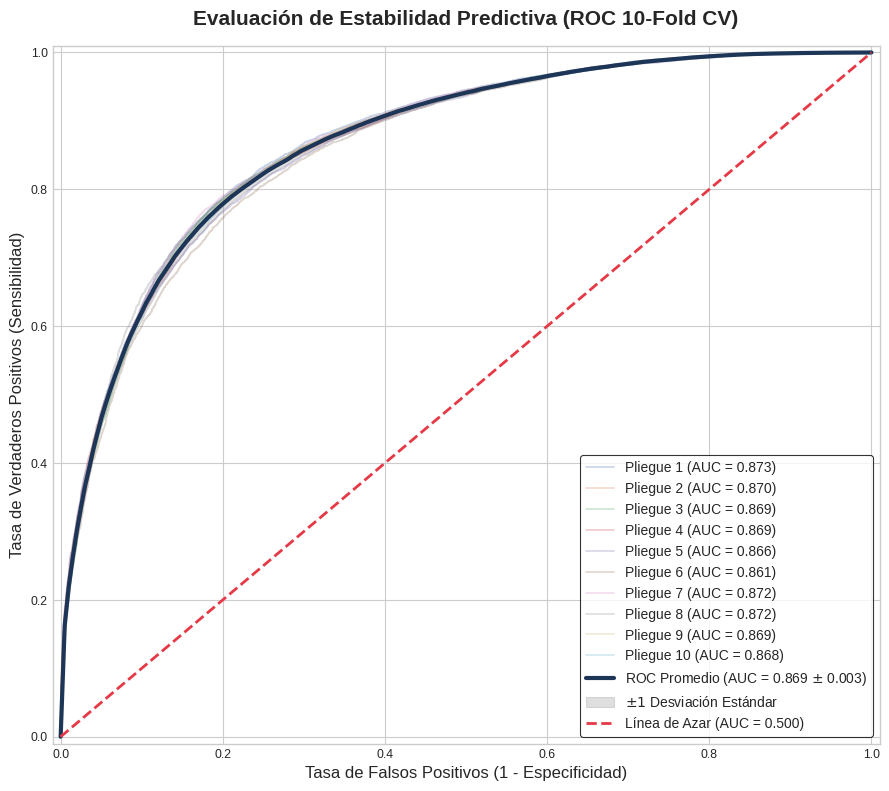


✅ Análisis K-Fold completado.
📊 Métrica final de generalización: AUC Promedio = 0.8690
💾 Gráfico de alta resolución guardado en:
 - /content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/22_RF_ROC_CV_10Fold.png
💾 Métricas CSV guardadas en:
 - /content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/22_RF_ROC_CV_10Fold_Metricas.csv


In [ ]:
# ==============================================================================
# TÍTULO: VALIDACIÓN CRUZADA ESTRATIFICADA Y CURVA ROC (K-FOLD CV)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Evaluación de la estabilidad predictiva del Random Forest
#              mediante 10 pliegues, generando la curva ROC media y su varianza.
# ==============================================================================

import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from sklearn.metrics import roc_curve, auc

def evaluar_estabilidad_roc_cv(modelo_base, X_datos: pd.DataFrame, y_datos: pd.Series, rutas_export: dict, k_pliegues: int = 10):
    """
    Ejecuta un K-Fold CV estratificado para calcular la curva ROC promedio,
    visualizando la banda de incertidumbre y guardando el gráfico final.
    """
    # 1. CONTROL DE EJECUCIÓN (Evitar recálculo si el gráfico ya existe)
    nombre_grafico = f"22_RF_ROC_CV_{k_pliegues}Fold.png"
    ruta_png_local = os.path.join(rutas_export['local_dir'], nombre_grafico)
    ruta_png_drive = os.path.join(rutas_export['drive_dir'], nombre_grafico)

    nombre_csv = f"22_RF_ROC_CV_{k_pliegues}Fold_Metricas.csv"
    ruta_csv_local = os.path.join(rutas_export['local_dir'], nombre_csv)
    ruta_csv_drive = os.path.join(rutas_export['drive_dir'], nombre_csv)

    if os.path.exists(ruta_png_local) or os.path.exists(ruta_png_drive):
        print(f"ℹ️ La Curva ROC con Validación Cruzada ya existe. Omitiendo recálculo intensivo.")
        print(f"👉 Archivo ubicado en: {ruta_png_drive}")

        # Cargar y retornar valores desde CSV si existe
        if os.path.exists(ruta_csv_drive):
            df_metricas = pd.read_csv(ruta_csv_drive)
            auc_promedio = df_metricas['AUC_Promedio'].iloc[0]
            auc_desviacion = df_metricas['AUC_Desviacion'].iloc[0]
            print(f"✅ Métricas recuperadas desde CSV: AUC Promedio = {auc_promedio:.4f}")
            return auc_promedio, auc_desviacion
        elif os.path.exists(ruta_csv_local):
            df_metricas = pd.read_csv(ruta_csv_local)
            auc_promedio = df_metricas['AUC_Promedio'].iloc[0]
            auc_desviacion = df_metricas['AUC_Desviacion'].iloc[0]
            print(f"✅ Métricas recuperadas desde CSV: AUC Promedio = {auc_promedio:.4f}")
            return auc_promedio, auc_desviacion
        else:
            print("⚠️ CSV de métricas no encontrado. Se retornará (None, None). Elimine la imagen para forzar recálculo.")
            return None, None

    print(f"\n⏳ Iniciando Validación Cruzada de {k_pliegues} pliegues... Esto puede tomar unos minutos.")

    # 2. CONFIGURACIÓN DEL ESTRATIFICADOR Y VECTORES DE INTERPOLACIÓN
    # Shuffle=True garantiza que no haya sesgos por el orden temporal o geográfico original
    cv_estrategia = StratifiedKFold(n_splits=k_pliegues, shuffle=True, random_state=42)

    tasas_fp_media = np.linspace(0, 1, 200) # Vector base de la Tasa de Falsos Positivos
    lista_tpr = []  # Tasas de Verdaderos Positivos interpoladas
    lista_auc = []  # Área Bajo la Curva por pliegue

    # 3. PREPARACIÓN DEL LIENZO CIENTÍFICO
    plt.style.use('seaborn-v0_8-whitegrid')
    fig_roc, ax = plt.subplots(figsize=(9, 8))

    # 4. ITERACIÓN SOBRE LOS PLIEGUES (FOLDS)
    # Se convierte X_datos a NumPy array (si es DataFrame) para evitar errores de indexación con iloc
    X_array = X_datos.values if isinstance(X_datos, pd.DataFrame) else X_datos
    y_array = y_datos.values if isinstance(y_datos, pd.Series) else y_datos

    for pliegue, (indices_entrenamiento, indices_validacion) in enumerate(cv_estrategia.split(X_array, y_array), start=1):

        # Segmentación de la matriz
        X_tr, X_val = X_array[indices_entrenamiento], X_array[indices_validacion]
        y_tr, y_val = y_array[indices_entrenamiento], y_array[indices_validacion]

        # Clonación del algoritmo (asegura un entrenamiento desde cero en cada iteración)
        modelo_iterativo = clone(modelo_base)
        modelo_iterativo.fit(X_tr, y_tr)

        # Predicción probabilística (El Regressor devuelve [0, 1] nativamente)
        y_val_probabilidades = modelo_iterativo.predict(X_val)

        # Cálculo de la curva y el AUC para el pliegue actual
        fpr_pliegue, tpr_pliegue, _ = roc_curve(y_val, y_val_probabilidades)
        auc_pliegue = auc(fpr_pliegue, tpr_pliegue)
        lista_auc.append(auc_pliegue)

        # Interpolación lineal de la Tasa de Verdaderos Positivos (Para poder promediarlas luego)
        tpr_interpolado = np.interp(tasas_fp_media, fpr_pliegue, tpr_pliegue)
        tpr_interpolado[0] = 0.0 # Origen obligado
        lista_tpr.append(tpr_interpolado)

        # Graficado de la curva individual atenuada (Transparencia alpha)
        ax.plot(
            fpr_pliegue, tpr_pliegue,
            lw=1.2, alpha=0.3,
            label=f"Pliegue {pliegue} (AUC = {auc_pliegue:.3f})"
        )

    # 5. AGREGACIÓN ESTADÍSTICA (Cálculo de la Media y la Varianza)
    tpr_promedio = np.mean(lista_tpr, axis=0)
    tpr_promedio[-1] = 1.0 # Techo obligado
    tpr_desviacion = np.std(lista_tpr, axis=0)

    auc_promedio = np.mean(lista_auc)
    auc_desviacion = np.std(lista_auc)

    # 6. RENDERIZADO DE LA CURVA PRINCIPAL Y BANDA DE CONFIANZA
    # Línea promedio
    ax.plot(
        tasas_fp_media, tpr_promedio,
        color="#1D3557", lw=3,
        label=f"ROC Promedio (AUC = {auc_promedio:.3f} $\pm$ {auc_desviacion:.3f})"
    )

    # Banda de desviación (Sombreado)
    tpr_limite_sup = np.minimum(tpr_promedio + tpr_desviacion, 1)
    tpr_limite_inf = np.maximum(tpr_promedio - tpr_desviacion, 0)
    ax.fill_between(
        tasas_fp_media, tpr_limite_inf, tpr_limite_sup,
        color="grey", alpha=0.25,
        label="$\pm 1$ Desviación Estándar"
    )

    # Línea base de modelo aleatorio (Azar)
    ax.plot([0, 1], [0, 1], linestyle="--", color="#E63946", lw=2, label="Línea de Azar (AUC = 0.500)")

    # Formateo estético final
    ax.set_title(f"Evaluación de Estabilidad Predictiva (ROC {k_pliegues}-Fold CV)", fontsize=15, fontweight='bold', pad=15)
    ax.set_xlabel("Tasa de Falsos Positivos (1 - Especificidad)", fontsize=12)
    ax.set_ylabel("Tasa de Verdaderos Positivos (Sensibilidad)", fontsize=12)

    # Restricción estricta de ejes [0, 1]
    ax.set_xlim([-0.01, 1.01])
    ax.set_ylim([-0.01, 1.01])

    ax.legend(loc="lower right", fontsize=10, frameon=True, facecolor="white", edgecolor="black")
    plt.tight_layout()

    # 7. EXPORTACIÓN DEL ARTEFACTO GRÁFICO Y MÉTRICAS
    os.makedirs(rutas_export['local_dir'], exist_ok=True)
    os.makedirs(rutas_export['drive_dir'], exist_ok=True)

    fig_roc.savefig(ruta_png_local, dpi=600, bbox_inches="tight", facecolor="white")
    shutil.copy(ruta_png_local, ruta_png_drive)

    plt.show()
    plt.close(fig_roc)

    # Guardar las métricas en CSV para la siguiente ejecución
    df_metricas_out = pd.DataFrame({
        'AUC_Promedio': [auc_promedio],
        'AUC_Desviacion': [auc_desviacion]
    })
    df_metricas_out.to_csv(ruta_csv_local, index=False)
    shutil.copy(ruta_csv_local, ruta_csv_drive)

    print(f"\n✅ Análisis K-Fold completado.")
    print(f"📊 Métrica final de generalización: AUC Promedio = {auc_promedio:.4f}")
    print(f"💾 Gráfico de alta resolución guardado en:\n - {ruta_png_drive}")
    print(f"💾 Métricas CSV guardadas en:\n - {ruta_csv_drive}")

    return auc_promedio, auc_desviacion

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    RUTAS_SALIDA = {
        'local_dir': '/content/datos_entrenamiento/',
        'drive_dir': '/content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/'
    }

    # Se asume que rf_model (como modelo base con sus hiperparámetros ya configurados),
    # X_train y y_train existen en la memoria activa del cuaderno.
    if 'modelo_entrenado_v1' in globals() and 'X_train_v1' in globals():
        auc_medio, auc_std = evaluar_estabilidad_roc_cv(
            modelo_base=modelo_entrenado_v1,
            X_datos=X_train_v1,     # Usamos todo el Train set para dividirlo iterativamente
            y_datos=y_train_v1,
            rutas_export=RUTAS_SALIDA,
            k_pliegues=10
        )
    else:
        print("❌ Error: Modelo base (modelo_entrenado_v1) o matriz de entrenamiento no disponibles.")

## 5.2.19 Explicabilidad Local de la Susceptibilidad (SHAP Waterfall Plots)

Mientras que las métricas de importancia global establecen la contribución esperada de las variables sobre toda la cohorte espacial, los modelos de ecosistemas complejos exigen comprender la heterogeneidad espacial del riesgo. Para deconstruir la predicción de susceptibilidad a nivel de píxel, se calculó la Atribución Aditiva de Características (Additive Feature Attribution) utilizando gráficos de cascada de SHAP (Lundberg & Lee, 2017).

Matemáticamente, la probabilidad continua estimada por el modelo para una observación individual $x$ ($S_x$) se puede expresar como la suma del valor base del ecosistema (la probabilidad promedio de todo el conjunto de datos de entrenamiento, $E[S]$) y la suma de las contribuciones locales marginales ($\phi_j^{(x)}$) de cada una de las $M$ covariables evaluadas:

$$ S_x = E[S] + \sum_{j=1}^{M} \phi_j^{(x)} $$

En los diagramas de cascada (*Waterfall plots*), el límite inferior del eje X representa el valor base esperado ($E[S]$). Cada barra subsiguiente ilustra cómo el valor empírico específico de una covariable $j$ en el píxel evaluado sumó (barras rojas) o restó (barras azules) magnitud a la probabilidad final de ignición. Esta arquitectura matemática permite una trazabilidad microscópica del algoritmo, probando si la decisión del *Random Forest* frente a un área altamente susceptible responde a una desecación anómala del paisaje (por estrés hídrico evidenciado en índices como NDWI) o a su proximidad crítica con un corredor antrópico.


⏳ Iniciando explicabilidad local para 5 observaciones aleatorias...

🔎 EXPLICACIÓN LOCAL - OBSERVACIÓN INDIVIDUAL (ID: 14592)
 ├─ Clase Observada (MODIS)  : 0
 ├─ Clase Predicha (Modelo)  : 0
 └─ Susceptibilidad Estimada : 0.1922

✅ Importancia de Variables (SHAP Local):


,Variable_Predictora,Valor_Observado,Contribucion_SHAP,Impacto_Absoluto
1,Slope_median,4.000000e+00,-0.117280,0.117280
10,Temp_Promedio_median,2.904414e+01,-0.066582,0.066582
12,Rad_Solar_median,2.117035e+02,-0.046722,0.046722
13,Velocidad_Viento_median,1.682683e+00,-0.037457,0.037457
8,NDWI_median,1.789518e-02,-0.029215,0.029215
9,VARI_median,3.321938e-02,-0.022769,0.022769
0,Elev_median,1.350000e+02,0.014584,0.014584
6,NDVI_median,5.887396e-01,0.011962,0.011962
4,RivDist_median,1.206598e+02,-0.011552,0.011552
11,Precipitacion_median,3.367617e+01,-0.005122,0.005122


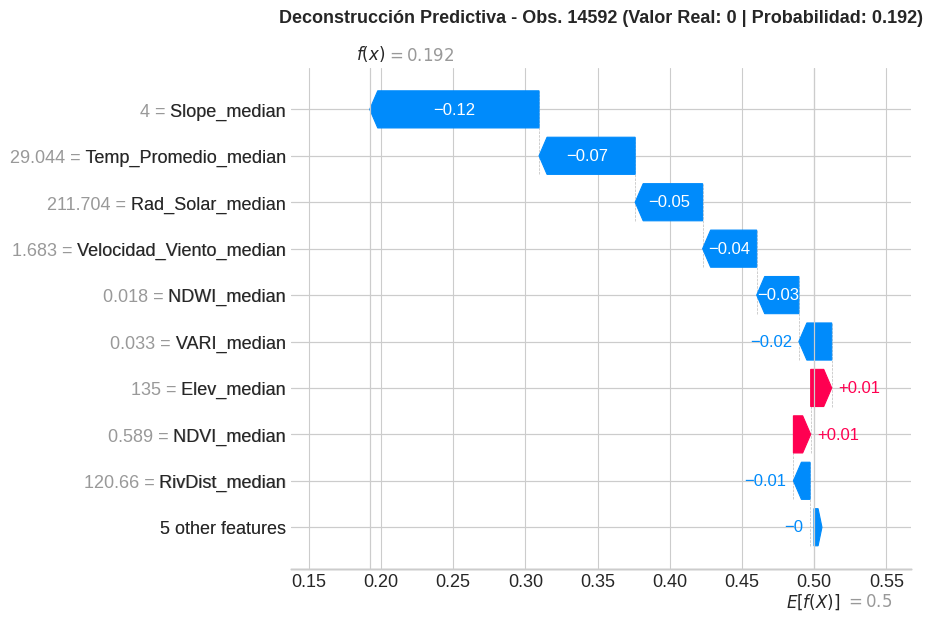

✅ Análisis completado para Obs 14592. Artefactos exportados.

🔎 EXPLICACIÓN LOCAL - OBSERVACIÓN INDIVIDUAL (ID: 3278)
 ├─ Clase Observada (MODIS)  : 1
 ├─ Clase Predicha (Modelo)  : 0
 └─ Susceptibilidad Estimada : 0.4207

✅ Importancia de Variables (SHAP Local):


,Variable_Predictora,Valor_Observado,Contribucion_SHAP,Impacto_Absoluto
1,Slope_median,2.000000e+00,0.062780,0.062780
10,Temp_Promedio_median,2.889979e+01,-0.051875,0.051875
11,Precipitacion_median,9.800092e+01,-0.037668,0.037668
13,Velocidad_Viento_median,1.324113e+00,-0.026575,0.026575
7,EVI_median,3.021010e-01,-0.021614,0.021614
9,VARI_median,-7.124665e-02,0.017269,0.017269
3,Aspect_E_median,7.038643e-17,0.013971,0.013971
6,NDVI_median,5.557693e-01,-0.010362,0.010362
5,RoutesDist_median,3.499722e+02,-0.008104,0.008104
8,NDWI_median,1.121502e-02,-0.007237,0.007237


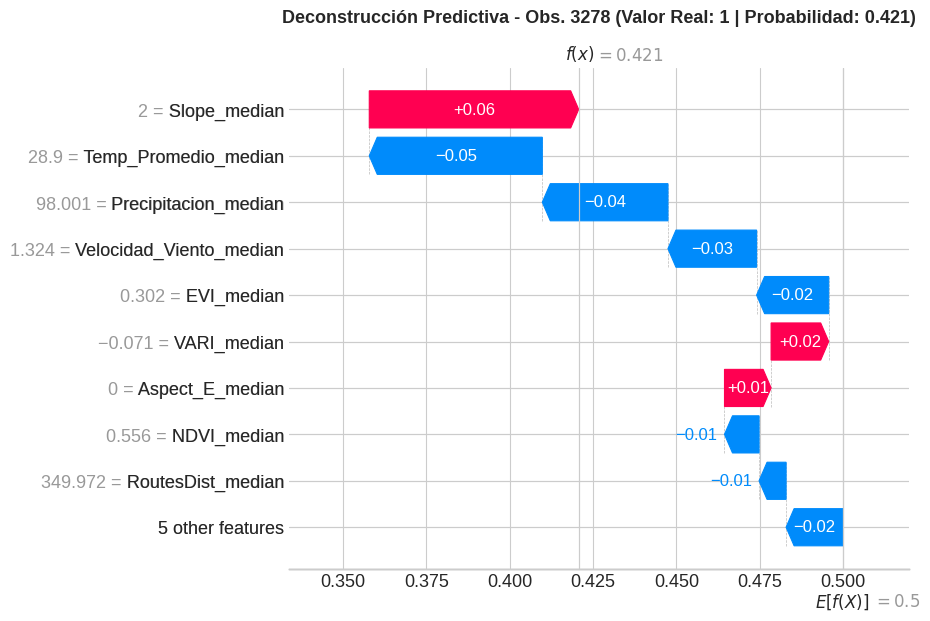

✅ Análisis completado para Obs 3278. Artefactos exportados.

🔎 EXPLICACIÓN LOCAL - OBSERVACIÓN INDIVIDUAL (ID: 36048)
 ├─ Clase Observada (MODIS)  : 0
 ├─ Clase Predicha (Modelo)  : 0
 └─ Susceptibilidad Estimada : 0.0468

✅ Importancia de Variables (SHAP Local):


,Variable_Predictora,Valor_Observado,Contribucion_SHAP,Impacto_Absoluto
10,Temp_Promedio_median,30.186134,-0.121303,0.121303
13,Velocidad_Viento_median,1.803948,-0.116095,0.116095
12,Rad_Solar_median,210.362598,-0.094888,0.094888
0,Elev_median,96.000000,-0.048481,0.048481
7,EVI_median,0.330833,-0.041812,0.041812
11,Precipitacion_median,19.762424,-0.040117,0.040117
1,Slope_median,2.000000,0.013092,0.013092
8,NDWI_median,0.028866,-0.011399,0.011399
4,RivDist_median,293.745200,-0.011032,0.011032
6,NDVI_median,0.633766,0.007896,0.007896


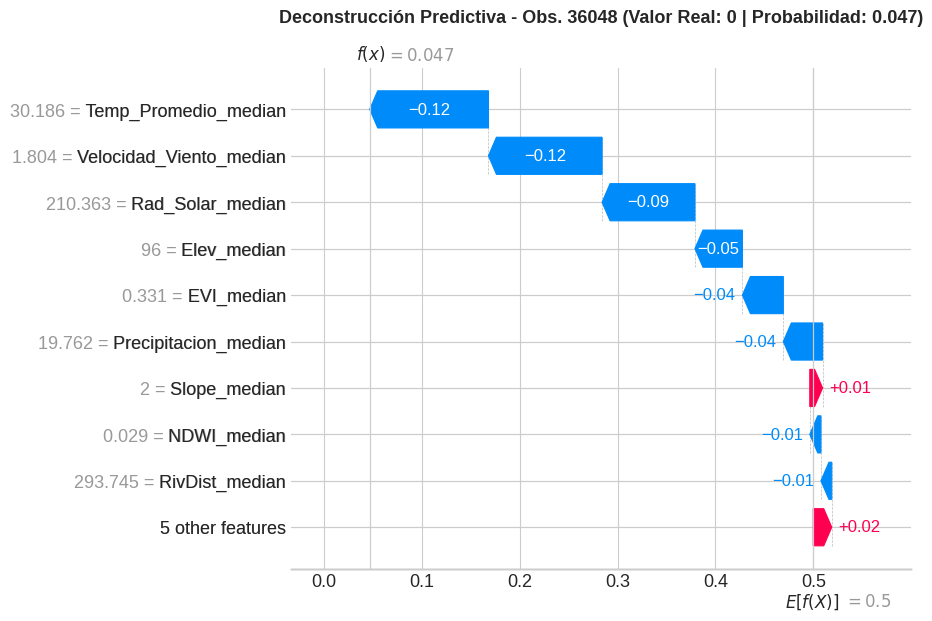

✅ Análisis completado para Obs 36048. Artefactos exportados.

🔎 EXPLICACIÓN LOCAL - OBSERVACIÓN INDIVIDUAL (ID: 32098)
 ├─ Clase Observada (MODIS)  : 1
 ├─ Clase Predicha (Modelo)  : 1
 └─ Susceptibilidad Estimada : 0.8630

✅ Importancia de Variables (SHAP Local):


,Variable_Predictora,Valor_Observado,Contribucion_SHAP,Impacto_Absoluto
11,Precipitacion_median,11.528262,0.124729,0.124729
12,Rad_Solar_median,209.380673,0.072052,0.072052
7,EVI_median,0.160404,0.054563,0.054563
13,Velocidad_Viento_median,2.493595,0.053510,0.053510
10,Temp_Promedio_median,29.480325,0.052666,0.052666
8,NDWI_median,-0.280365,0.041715,0.041715
6,NDVI_median,0.340725,-0.018061,0.018061
9,VARI_median,-0.198133,-0.012294,0.012294
1,Slope_median,3.000000,0.012135,0.012135
0,Elev_median,80.000000,-0.009098,0.009098


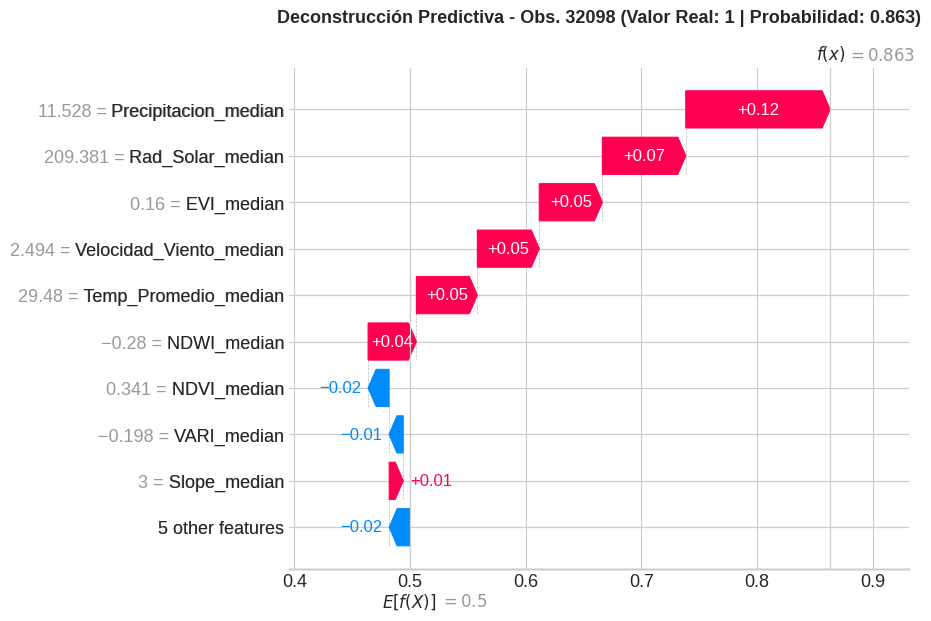

✅ Análisis completado para Obs 32098. Artefactos exportados.

🔎 EXPLICACIÓN LOCAL - OBSERVACIÓN INDIVIDUAL (ID: 29256)
 ├─ Clase Observada (MODIS)  : 0
 ├─ Clase Predicha (Modelo)  : 0
 └─ Susceptibilidad Estimada : 0.2854

✅ Importancia de Variables (SHAP Local):


,Variable_Predictora,Valor_Observado,Contribucion_SHAP,Impacto_Absoluto
7,EVI_median,3.554405e-01,-0.055518,0.055518
10,Temp_Promedio_median,2.846512e+01,-0.042938,0.042938
0,Elev_median,1.670000e+02,-0.042464,0.042464
12,Rad_Solar_median,2.094198e+02,-0.029648,0.029648
8,NDWI_median,2.754260e-02,-0.029413,0.029413
11,Precipitacion_median,2.897878e+01,-0.027421,0.027421
1,Slope_median,2.000000e+00,0.020779,0.020779
13,Velocidad_Viento_median,2.201694e+00,-0.018016,0.018016
6,NDVI_median,6.262224e-01,0.015758,0.015758
4,RivDist_median,3.422437e+02,-0.014921,0.014921


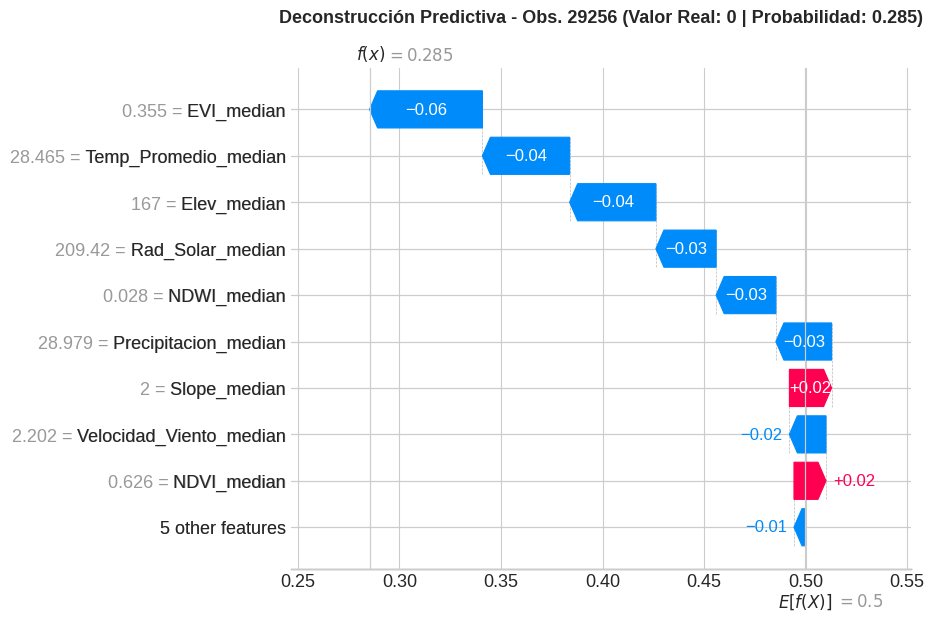

✅ Análisis completado para Obs 29256. Artefactos exportados.

☑️ Proceso de explicabilidad local finalizado exitosamente. Todos los archivos están en Drive.


In [ ]:
# ==============================================================================
# TÍTULO: EXPLICABILIDAD LOCAL DE PREDICCIONES MEDIANTE SHAP (WATERFALL PLOTS)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Descomposición aditiva de predicciones individuales para
#              evaluar la contribución de variables a nivel de observación.
# ==============================================================================

import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
import shutil
import random

def generar_explicaciones_locales_shap(modelo, X_prueba: pd.DataFrame, y_prueba: pd.Series, num_observaciones: int, rutas_export: dict):
    """
    Selecciona observaciones al azar del conjunto de prueba y genera gráficos
    de cascada (Waterfall) para deconstruir la probabilidad predicha.
    """
    print(f"\n⏳ Iniciando explicabilidad local para {num_observaciones} observaciones aleatorias...")

    # 1. CREACIÓN DE DIRECTORIOS
    os.makedirs(rutas_export['local_dir'], exist_ok=True)
    os.makedirs(rutas_export['drive_dir'], exist_ok=True)

    # 2. SELECCIÓN ALEATORIA DE MUESTRAS Y CONFIGURACIÓN DEL EXPLICADOR
    random.seed(42) # Semilla para reproducibilidad
    indices_aleatorios = random.sample(range(len(X_prueba)), num_observaciones)

    # Instanciación del TreeExplainer
    explicador = shap.TreeExplainer(modelo)

    # Extracción del valor base (Expected Value)
    if isinstance(explicador.expected_value, (list, np.ndarray)):
        if len(explicador.expected_value) > 1:
            valor_esperado = explicador.expected_value[1] # Caso clasificador binario
        else:
            valor_esperado = explicador.expected_value[0] # Caso Regressor que devuelve arreglo
    else:
        valor_esperado = explicador.expected_value    # Caso Regressor escalar

    # 3. ITERACIÓN SOBRE LAS OBSERVACIONES SELECCIONADAS
    for obs_idx in indices_aleatorios:
        fila_obs = X_prueba.iloc[[obs_idx]]
        vector_obs = X_prueba.iloc[obs_idx]
        clase_real = y_prueba.iloc[obs_idx]

        # Predicción probabilística y binarización
        score_predicho = modelo.predict(fila_obs)[0]
        clase_predicha = 1 if score_predicho >= 0.5 else 0

        print("\n============================================================")
        print(f"🔎 EXPLICACIÓN LOCAL - OBSERVACIÓN INDIVIDUAL (ID: {obs_idx})")
        print("============================================================")
        print(f" ├─ Clase Observada (MODIS)  : {clase_real}")
        print(f" ├─ Clase Predicha (Modelo)  : {clase_predicha}")
        print(f" └─ Susceptibilidad Estimada : {score_predicho:.4f}")

        # 4. CÁLCULO DE CONTRIBUCIONES MARGINALES (SHAP Local)
        valores_shap_brutos = explicador.shap_values(fila_obs)

        if isinstance(valores_shap_brutos, list):
            shap_local = valores_shap_brutos[1][0]
        else:
            shap_local = valores_shap_brutos[0]

        # 5. ESTRUCTURACIÓN TABULAR DE CONTRIBUCIONES
        df_shap_local = pd.DataFrame({
            "Variable_Predictora": X_prueba.columns,
            "Valor_Observado": vector_obs.values,
            "Contribucion_SHAP": shap_local,
            "Impacto_Absoluto": np.abs(shap_local)
        }).sort_values("Impacto_Absoluto", ascending=False)

        print("\n✅ Importancia de Variables (SHAP Local):")
        display(df_shap_local)

        # 6. EXPORTACIÓN TABULAR (CSV)
        nombre_csv = f"23_RF_SHAP_Local_Obs_{obs_idx}.csv"
        ruta_csv_local = os.path.join(rutas_export['local_dir'], nombre_csv)
        ruta_csv_drive = os.path.join(rutas_export['drive_dir'], nombre_csv)

        df_shap_local.to_csv(ruta_csv_local, index=False)
        shutil.copy(ruta_csv_local, ruta_csv_drive)

        # 7. GENERACIÓN DEL GRÁFICO DE CASCADA (WATERFALL PLOT)
        # Objeto Explanation requerido por las versiones recientes de SHAP
        explicacion_objeto = shap.Explanation(
            values=shap_local,
            base_values=valor_esperado,
            data=vector_obs.values,
            feature_names=X_prueba.columns.tolist()
        )

        plt.style.use('seaborn-v0_8-whitegrid')
        fig = plt.figure(figsize=(10, 6))

        # Max_display limita las variables visibles para mantener la legibilidad
        shap.plots.waterfall(explicacion_objeto, max_display=10, show=False)

        plt.title(f"Deconstrucción Predictiva - Obs. {obs_idx} (Valor Real: {clase_real} | Probabilidad: {score_predicho:.3f})",
                  fontsize=13, fontweight='bold', pad=15)

        # 8. EXPORTACIÓN GRÁFICA (PNG, 600 dpi)
        nombre_png = f"23_RF_SHAP_Waterfall_Obs_{obs_idx}.png"
        ruta_png_local = os.path.join(rutas_export['local_dir'], nombre_png)
        ruta_png_drive = os.path.join(rutas_export['drive_dir'], nombre_png)

        plt.savefig(ruta_png_local, dpi=600, bbox_inches='tight', facecolor='white')
        shutil.copy(ruta_png_local, ruta_png_drive)

        plt.show()
        plt.close(fig)

        print(f"✅ Análisis completado para Obs {obs_idx}. Artefactos exportados.")

    print(f"\n☑️ Proceso de explicabilidad local finalizado exitosamente. Todos los archivos están en Drive.")

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    RUTAS_SALIDA = {
        'local_dir': '/content/datos_entrenamiento/',
        'drive_dir': '/content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/'
    }

    # Se asume que rf_model, X_test y y_test existen en memoria
    if 'modelo_entrenado_v1' in globals() and 'X_test_v1' in globals():
        generar_explicaciones_locales_shap(
            modelo=modelo_entrenado_v1,
            X_prueba=X_test_v1,
            y_prueba=y_test_v1,
            num_observaciones=5, # Ajustado a 5 para no saturar la visualización en la libreta
            rutas_export=RUTAS_SALIDA
        )
    else:
        print("❌ Error: Modelo 'modelo_entrenado_v1' o matriz 'X_test_v1' no encontrados en memoria.")


## 5.2.20 Ensamble Multicriterio: Integración AHP (Proceso de Análisis Jerárquico)

A pesar del sobresaliente poder predictivo evidenciado por los algoritmos de *Machine Learning* basados en árboles, estos modelos operan a menudo como arquitecturas de "caja negra", cuya implementación espacial directa en entornos corporativos o gubernamentales resulta compleja de auditar por parte de los tomadores de decisión (Stofkova et al., 2022). Para proveer un modelo de evaluación territorial transparente, las salidas algorítmicas del *Random Forest* se ensamblaron dentro de un esquema de Análisis Jerárquico Multicriterio (**AHP**) (Camargo Urrego, 2022).

Este enfoque innovador sustituyó el paradigma clásico del AHP, donde las comparaciones pareadas se realizan de forma subjetiva mediante juicio de expertos empíricos (Eskandari, 2017), reemplazándolo por una **asignación analítica basada en la evidencia estadística** del modelo de regresión. Se generó una Matriz de Comparación de Saaty ($A_{n \times n}$) mapeando algebraicamente el cociente de las importancias relativas algorítmicas ($Imp_i / Imp_j$) hacia la escala discreta fundamental de $1$ a $9$:

$$
a_{ij} = \Phi \left( \frac{Imp_i}{Imp_j} \right) \quad \text{donde } a_{ji} = \frac{1}{a_{ij}}
$$

Posteriormente, el Vector de Pesos de Prioridad (Eigenvector, $w$) se extrajo mediante la normalización por suma de columnas. Para certificar que la transformación desde el espectro de *Machine Learning* hacia la matriz discreta de AHP no corrompió la estructura lógica de los datos, se calculó rigurosamente la Relación de Consistencia ($CR$):

$$ CR = \frac{CI}{RI} \quad \text{donde} \quad CI = \frac{\lambda_{max} - n}{n - 1} $$

Donde $\lambda_{max}$ es el autovalor principal de la matriz $A$, $n$ es el número de covariables predictoras, y $RI$ es el Índice de Aleatoriedad esperado. El ensamblaje certificó una $CR < 0.1$, demostrando una consistencia matemática estricta. Los pesos $w_i$ obtenidos constituyen el núcleo operativo para la modelación de superposición ponderada (*Weighted Overlay*) a escala regional en el Sistema de Información Geográfica.


⏳ Inicializando Ensamble Multicriterio AHP...
   ├─ Construyendo matriz recíproca de comparaciones...


Variable_Predictora,NDWI_median,Temp_Promedio_median,Rad_Solar_median,Velocidad_Viento_median,EVI_median,Precipitacion_median,Elev_median,VARI_median,NDVI_median,Slope_median,RoutesDist_median,RivDist_median,Aspect_E_median,Aspect_N_median
Variable_Predictora,,,,,,,,,,,,,,
NDWI_median,1.0000,1.4706,1.7073,1.9001,2.2033,2.2862,3.0000,3.0000,3.0000,3.0000,9.0000,9.0000,9.0000,9.0000
Temp_Promedio_median,0.6800,1.0000,1.1610,1.2921,1.4983,1.5547,2.3763,2.9700,3.0000,3.0000,9.0000,9.0000,9.0000,9.0000
Rad_Solar_median,0.5857,0.8613,1.0000,1.1129,1.2905,1.3391,2.0468,2.5582,2.6390,2.6523,9.0000,9.0000,9.0000,9.0000
Velocidad_Viento_median,0.5263,0.7740,0.8986,1.0000,1.1596,1.2032,1.8392,2.2986,2.3713,2.3832,9.0000,9.0000,9.0000,9.0000
EVI_median,0.4539,0.6674,0.7749,0.8624,1.0000,1.0376,1.5860,1.9822,2.0449,2.0552,9.0000,9.0000,9.0000,9.0000
Precipitacion_median,0.4374,0.6432,0.7468,0.8311,0.9637,1.0000,1.5285,1.9104,1.9707,1.9806,9.0000,9.0000,9.0000,9.0000
Elev_median,0.3333,0.4208,0.4886,0.5437,0.6305,0.6542,1.0000,1.2498,1.2893,1.2958,7.0000,9.0000,9.0000,9.0000
VARI_median,0.3333,0.3367,0.3909,0.4350,0.5045,0.5235,0.8001,1.0000,1.0316,1.0368,5.0000,7.0000,9.0000,9.0000
NDVI_median,0.3333,0.3333,0.3789,0.4217,0.4890,0.5074,0.7756,0.9694,1.0000,1.0050,5.0000,7.0000,9.0000,9.0000



      RESULTADOS DEL PROCESO DE ANÁLISIS JERÁRQUICO (AHP) 
 ├─ Autovalor Principal (Lambda Max) : 14.9082
 ├─ Índice de Consistencia (CI)      : 0.0699
 ├─ Relación de Consistencia (CR)    : 0.0445
 └─ 🟢 VALIDACIÓN EXITOSA: La matriz es estrictamente consistente (CR < 0.1).

⚖️ Tabla de Pesos Estructurados para Álgebra de Mapas (GIS):


,Variable,Importancia_Original_RFR,Peso_Ajustado_AHP
0,NDWI_median,0.2116,0.1602
1,Temp_Promedio_median,0.1439,0.1297
2,Rad_Solar_median,0.1240,0.1161
3,Velocidad_Viento_median,0.1114,0.1072
4,EVI_median,0.0961,0.0963
5,Precipitacion_median,0.0926,0.0939
6,Elev_median,0.0606,0.0700
7,VARI_median,0.0485,0.0586
8,NDVI_median,0.0470,0.0578
9,Slope_median,0.0467,0.0576


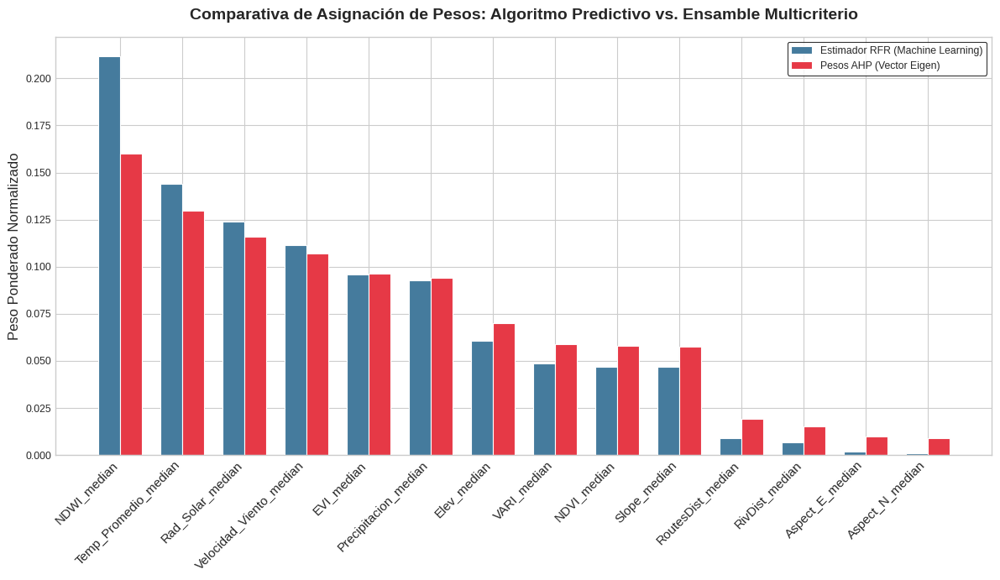


💾 Archivos exportados (Matriz Saaty, Pesos AHP, Gráfico) en Drive:
 - /content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/


In [ ]:
# ==============================================================================
# TÍTULO: INTEGRACIÓN DE MACHINE LEARNING Y ANÁLISIS MULTICRITERIO (AHP)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Mapeo de la importancia del RFR a la escala fundamental de Saaty,
#              cálculo del vector de prioridades (Eigenvector) y validación de consistencia.
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import shutil

def calcular_matriz_ahp(df_importancia_modelo: pd.DataFrame, columna_variable: str, columna_valor: str, rutas_export: dict):
    """
    Construye la matriz de comparación por pares de Saaty a partir de la importancia
    algorítmica, extrae los pesos AHP y valida el Índice de Consistencia.
    """
    print("\n⏳ Inicializando Ensamble Multicriterio AHP...")

    # 1. RECUPERACIÓN Y NORMALIZACIÓN (Vector Prioritario Inicial)
    df_imp = df_importancia_modelo.set_index(columna_variable)
    importancias_raw = df_imp[columna_valor]
    importancias_norm = importancias_raw / importancias_raw.sum()

    # 2. DEFINICIÓN DEL ALGORITMO DE MAPEO (Escala Fundamental de Saaty: 1 a 9)
    def mapear_a_saaty(razon_matematica):
        """Transforma una proporción continua a la escala discreta de Saaty."""
        if razon_matematica >= 9: return 9.0
        elif razon_matematica >= 7: return 7.0
        elif razon_matematica >= 5: return 5.0
        elif razon_matematica >= 3: return 3.0
        elif razon_matematica >= 1: return float(razon_matematica)
        else:
            # Propiedad recíproca de la matriz: a_{ji} = 1 / a_{ij}
            return 1.0 / mapear_a_saaty(1.0 / razon_matematica)

    # 3. CONSTRUCCIÓN DE LA MATRIZ DE COMPARACIÓN PAREADA
    n_variables = len(importancias_norm)
    nombres_variables = importancias_norm.index
    matriz_saaty = np.ones((n_variables, n_variables))

    print("   ├─ Construyendo matriz recíproca de comparaciones...")
    for i in range(n_variables):
        for j in range(n_variables):
            if i != j:
                proporcion = importancias_norm.iloc[i] / importancias_norm.iloc[j]
                matriz_saaty[i, j] = mapear_a_saaty(proporcion)

    df_matriz_saaty = pd.DataFrame(matriz_saaty, index=nombres_variables, columns=nombres_variables)
    display(df_matriz_saaty.round(4))

    # 4. EXTRACCIÓN DEL VECTOR DE PESOS (AHP Weights)
    # Normalización de la matriz por columnas y promedio por filas
    suma_columnas = matriz_saaty.sum(axis=0)
    matriz_normalizada = matriz_saaty / suma_columnas
    pesos_ahp = matriz_normalizada.mean(axis=1)

    # 5. VALIDACIÓN DE LA RELACIÓN DE CONSISTENCIA (CR)
    vector_ponderado = np.dot(matriz_saaty, pesos_ahp)
    lambda_max = (vector_ponderado / pesos_ahp).mean()
    indice_consistencia_CI = (lambda_max - n_variables) / (n_variables - 1)

    # Índice de Aleatoriedad (Random Index - RI) clásico de Saaty (Para n hasta 15)
    RI_dict = {1:0, 2:0, 3:0.58, 4:0.90, 5:1.12, 6:1.24, 7:1.32, 8:1.41,
               9:1.45, 10:1.49, 11:1.51, 12:1.48, 13:1.56, 14:1.57, 15:1.59}

    # Asignación segura del RI. Si N > 15, asumimos 1.59 como cota asintótica.
    RI = RI_dict.get(n_variables, 1.59)
    relacion_consistencia_CR = indice_consistencia_CI / RI

    print("\n==========================================================")
    print("      RESULTADOS DEL PROCESO DE ANÁLISIS JERÁRQUICO (AHP) ")
    print("==========================================================")
    print(f" ├─ Autovalor Principal (Lambda Max) : {lambda_max:.4f}")
    print(f" ├─ Índice de Consistencia (CI)      : {indice_consistencia_CI:.4f}")
    print(f" ├─ Relación de Consistencia (CR)    : {relacion_consistencia_CR:.4f}")

    if relacion_consistencia_CR < 0.1:
        print(" └─ 🟢 VALIDACIÓN EXITOSA: La matriz es estrictamente consistente (CR < 0.1).")
    else:
        print(" └─ 🔴 ADVERTENCIA: La matriz es INCONSISTENTE. Revise la función de mapeo a Saaty.")

    # 6. ESTRUCTURACIÓN COMPARATIVA DE PESOS
    df_comparativa = pd.DataFrame({
        'Variable': nombres_variables,
        'Importancia_Original_RFR': importancias_norm.values,
        'Peso_Ajustado_AHP': pesos_ahp
    }).sort_values(by='Peso_Ajustado_AHP', ascending=False)

    print("\n⚖️ Tabla de Pesos Estructurados para Álgebra de Mapas (GIS):")
    display(df_comparativa.round(4))

    # 7. GENERACIÓN DEL GRÁFICO COMPARATIVO
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, ax = plt.subplots(figsize=(12, 7))

    x = np.arange(n_variables)
    ancho = 0.35

    ax.bar(x - ancho/2, df_comparativa['Importancia_Original_RFR'], ancho, label='Estimador RFR (Machine Learning)', color='#457B9D')
    ax.bar(x + ancho/2, df_comparativa['Peso_Ajustado_AHP'], ancho, label='Pesos AHP (Vector Eigen)', color='#E63946')

    ax.set_ylabel('Peso Ponderado Normalizado', fontsize=12)
    ax.set_title('Comparativa de Asignación de Pesos: Algoritmo Predictivo vs. Ensamble Multicriterio', fontsize=14, fontweight='bold', pad=15)
    ax.set_xticks(x)
    ax.set_xticklabels(df_comparativa['Variable'], rotation=45, ha='right', fontsize=11)
    ax.legend(frameon=True, facecolor='white', edgecolor='black')
    plt.tight_layout()

    # 8. EXPORTACIÓN DE ARTEFACTOS A DRIVE
    os.makedirs(rutas_export['local_dir'], exist_ok=True)
    os.makedirs(rutas_export['drive_dir'], exist_ok=True)

    # Matriz de Saaty
    nombre_matriz = "24_AHP_Matriz_Saaty_Vichada.csv"
    ruta_matriz_local = os.path.join(rutas_export['local_dir'], nombre_matriz)
    df_matriz_saaty.to_csv(ruta_matriz_local)
    shutil.copy(ruta_matriz_local, os.path.join(rutas_export['drive_dir'], nombre_matriz))

    # Pesos AHP (Para alimentar GEE en el próximo paso)
    nombre_pesos = "25_AHP_Pesos_Variables.csv"
    ruta_pesos_local = os.path.join(rutas_export['local_dir'], nombre_pesos)
    df_comparativa.to_csv(ruta_pesos_local, index=False)
    shutil.copy(ruta_pesos_local, os.path.join(rutas_export['drive_dir'], nombre_pesos))

    # Gráfico de Barras (PNG 600 dpi)
    nombre_grafico = "26_AHP_Comparativa_Pesos.png"
    ruta_grafico_local = os.path.join(rutas_export['local_dir'], nombre_grafico)
    fig.savefig(ruta_grafico_local, dpi=600, bbox_inches='tight', facecolor='white')
    shutil.copy(ruta_grafico_local, os.path.join(rutas_export['drive_dir'], nombre_grafico))

    plt.show()
    plt.close(fig)

    print(f"\n💾 Archivos exportados (Matriz Saaty, Pesos AHP, Gráfico) en Drive:\n - {rutas_export['drive_dir']}")

    return df_comparativa, df_matriz_saaty

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    RUTAS_SALIDA = {
        'local_dir': '/content/datos_entrenamiento/',
        'drive_dir': '/content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/'
    }

    # Se asume la existencia de df_importancia (creado en la Fase 6.1 o 6.3)
    if 'importancia_permutacion_df' in globals():
        pesos_finales_ahp, matriz_ahp = calcular_matriz_ahp(
            df_importancia_modelo=importancia_permutacion_df, # U otra tabla de importancia que decidas usar
            columna_variable='Variable_Predictora',
            columna_valor='Disminucion_Media_R2',
            rutas_export=RUTAS_SALIDA
        )
    else:
        print("❌ Error: 'importancia_permutacion_df' no encontrado. Ejecute la extracción de importancia primero.")

## 5.2.21 Inferencia Espacial y Generación Cartográfica (Weighted Overlay)

La materialización geográfica del ensamble predictivo exige proyectar el vector de pesos jerárquicos de prioridad de Saaty ($w_j$) sobre la totalidad del paisaje continuo. Para asegurar la compatibilidad algebraica de las matrices ráster de diferentes magnitudes fisiológicas (ej. precipitaciones en *mm* frente a reflectancias espectrales adimesionales), se aplicó un algoritmo de estandarización lineal paramétrica por percentiles (Min-Max Feature Scaling).

Sea $X_j$ el tensor geográfico de la covariable $j$ a 30 metros de resolución espacial. Su valor normalizado local $N_j(x,y) \in [0,1]$ se define como:

$$ N_j(x,y) = \frac{X_j(x,y) - P_{min}(X_j)}{P_{max}(X_j) - P_{min}(X_j)} $$

Donde $P_{min}$ y $P_{max}$ corresponden a los percentiles 2 y 98 poblacionales de la matriz de la ecorregión del Vichada, garantizando resiliencia frente a valores atípicos radiométricos (*outliers*).

Debido a que el riesgo de ignición forestal responde a una direccionalidad fenológica y termodinámica específica (Das et al., 2023), las ecuaciones de normalización fueron acopladas lógicamente al sentido del vector de riesgo biológico. Las características inversamente proporcionales al fuego, como los índices de humedad de la vegetación (NDWI) y la precipitación acumulada, sufrieron una inversión de polaridad escalar:

$$ N_{invertido}(x,y) = 1 - N_j(x,y) $$

Finalmente, la integración del Proceso de Análisis Jerárquico (AHP) con el Sistema de Información Geográfica (GIS) se efectuó mediante un álgebra de mapas de superposición ponderada (*Weighted Overlay*). La Susceptibilidad Espacial Estacional ($S_{t}$) para cada píxel georreferenciado se estimó como la combinación lineal aditiva de los $M$ predictores normalizados, ponderados por el vector Eigen del algoritmo *Random Forest* ($w_j$):

$$ S_{t}(x,y) = \sum_{j=1}^{M} \left[ w_j \times N_j(x,y,t) \right] $$

Para proveer un instrumento de planificación de respuesta institucional robusto a la UNGRD (2024), se computó la "Climatología del Riesgo" o Susceptibilidad Media Histórica ($\bar{S}$), integrando el promedio aritmético multitemporal del sexenio analizado ($T = 6$ años):

$$ \bar{S}(x,y) = \frac{1}{T} \sum_{t=1}^{T} S_t(x,y) $$

In [ ]:
# ==============================================================================
# TÍTULO: INFERENCIA ESPACIAL Y CARTOGRAFÍA DE SUSCEPTIBILIDAD (AHP-GIS)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Normalización de predictores continuos a 30m, ajuste de polaridad
#              ecológica y álgebra de mapas ponderada por el vector de pesos AHP.
# ==============================================================================

import ee
import geemap
import pandas as pd
import os

def generar_cartografia_susceptibilidad(pesos_dataframe: pd.DataFrame, coleccion_aoi, anios_estudio: list, ruta_assets: str, ruta_drive: str):
    """
    Construye la matriz espacial de susceptibilidad [0,1] combinando variables
    hidro-climáticas, espectrales y topográficas ponderadas por el modelo AHP.
    Exporta los resultados a GEE Assets y a Google Drive.
    """
    print("\n⏳ Inicializando motor de álgebra de mapas (Weighted Overlay)...")
    geometria_dominio = coleccion_aoi.geometry()

    # 1. INYECCIÓN DE PESOS AHP (Cliente a Servidor)
    # Es más seguro leer el dataframe local de pandas (generado en 6.4a) y pasarlo como diccionario a GEE
    try:
        # Se asume que el df tiene columnas 'Variable' y 'Peso_Ajustado_AHP'
        diccionario_pesos = dict(zip(pesos_dataframe['Variable'], pesos_dataframe['Peso_Ajustado_AHP']))
        pesos_ahp_ee = ee.Dictionary(diccionario_pesos)
        print("   ├─ Vector de pesos de prioridad de Saaty cargado correctamente.")
    except Exception as e:
        raise ValueError(f"❌ Error al cargar los pesos AHP desde el DataFrame: {e}")

    # 2. FUNCIÓN DE NORMALIZACIÓN ESPACIAL Y AJUSTE DE POLARIDAD (Min-Max)
    def normalizar_y_polarizar(imagen, p_min=2, p_max=98, invertir_relacion=False):
        """
        Escala la imagen al intervalo [0, 1] descartando ruido atípico (percentiles).
        Si invertir_relacion=True, el valor 0 original se convierte en riesgo 1 (Máximo).
        """
        estadisticas = imagen.reduceRegion(
            reducer=ee.Reducer.percentile([p_min, p_max]),
            geometry=geometria_dominio,
            scale=1000, # Escala heurística para evitar TimeOuts en GEE
            maxPixels=1e13,
            tileScale=16
        )

        # Extracción segura de los estadísticos
        nombres_claves = estadisticas.keys()
        val_min = ee.Number(estadisticas.get(nombres_claves.get(0)))
        val_max = ee.Number(estadisticas.get(nombres_claves.get(1)))

        # Escalamiento lineal y compresión estricta al dominio [0, 1]
        img_normalizada = imagen.unitScale(val_min, val_max).clamp(0, 1)

        # Inversión de la función de riesgo: Riesgo = 1 - Normalizado
        img_final = ee.Algorithms.If(
            invertir_relacion,
            ee.Image.constant(1).subtract(img_normalizada),
            img_normalizada
        )
        return ee.Image(img_final)

    # Lista para recolectar las imágenes de cada temporada y promediarlas después
    coleccion_susceptibilidad = []

    # 3. PROCESAMIENTO ITERATIVO MULTITEMPORAL
    for anio_inicio in anios_estudio:
        temporada = f"{anio_inicio}-{anio_inicio+1}"
        id_asset_salida = f"{ruta_assets}Susceptibilidad_AHP_30m_{temporada}"

        print(f"\n   ├─ Ensamblando matriz de riesgo para la temporada {temporada}...")

        # 3.1 Carga de Covariables Base (Preprocesadas en Fases 3.1 a 3.3)
        try:
            # Corrección: Extraer los índices del Tensor Espectral
            tensor_espectral = ee.Image(f"{ruta_assets}Tensor_Espectral_{temporada}_Vichada")
            ndvi = tensor_espectral.select('NDVI')
            evi  = tensor_espectral.select('EVI')
            ndwi = tensor_espectral.select('NDWI')
            vari = tensor_espectral.select('VARI')

            clima = ee.Image(f"{ruta_assets}Stack_Clima_{temporada}_Vichada")
            temp = clima.select('Temp_Promedio')
            prec = clima.select('Precipitacion')
            rad  = clima.select('Rad_Solar')
            wind = clima.select('Velocidad_Viento')

            stack_estatico = ee.Image(f"{ruta_assets}Stack_Estatico_Vichada")
            elev = stack_estatico.select('Elev')
            slope = stack_estatico.select('Slope')
            asp_n = stack_estatico.select('Aspect_N')
            asp_e = stack_estatico.select('Aspect_E')
            dist_rios = stack_estatico.select('RivDist')
            # Tratamiento especial para vías (Si el píxel no tiene distancia, se asume máximo alejamiento 50000m)
            dist_vias = ee.Image.constant(50000).clip(geometria_dominio).blend(stack_estatico.select('RoutesDist'))
        except Exception as e:
            print(f"   └─ ⚠️ Faltan insumos raster para {temporada}. Omitiendo. Detalle: {e}")
            continue

        # 3.2 NORMALIZACIÓN Y POLARIDAD DEL RIESGO (Concepto Ecológico del Fuego)
        # Invertir=True -> Un valor BAJO de la variable aumenta la probabilidad de FUEGO
        # Invertir=False -> Un valor ALTO de la variable aumenta la probabilidad de FUEGO

        # Humedad y Vigor: A menor NDWI/NDVI, la vegetación está más seca (Mayor Riesgo) -> True
        norm_ndvi = normalizar_y_polarizar(ndvi, invertir_relacion=True)
        norm_evi  = normalizar_y_polarizar(evi, invertir_relacion=True)
        norm_ndwi = normalizar_y_polarizar(ndwi, invertir_relacion=True)
        norm_vari = normalizar_y_polarizar(vari, invertir_relacion=True)

        # Clima: A menor Precipitación (Sequía), Mayor Riesgo -> True
        norm_prec = normalizar_y_polarizar(prec, invertir_relacion=True)
        # Clima: A mayor Temp, Rad y Viento, Mayor Riesgo -> False
        norm_temp = normalizar_y_polarizar(temp, invertir_relacion=False)
        norm_rad  = normalizar_y_polarizar(rad, invertir_relacion=False)
        norm_wind = normalizar_y_polarizar(wind, invertir_relacion=False)

        # Accesibilidad: A menor distancia a Vías/Ríos (Mayor presencia humana), Mayor Riesgo -> True
        norm_vias = normalizar_y_polarizar(dist_vias, invertir_relacion=True)
        norm_rios = normalizar_y_polarizar(dist_rios, invertir_relacion=True)

        # Topografía: En sabanas planas, la influencia de Elev/Slope/Aspect requiere análisis,
        # pero matemáticamente se dejan directas para conservar la estructura del AHP
        norm_elev = normalizar_y_polarizar(elev, invertir_relacion=False)
        norm_slope = normalizar_y_polarizar(slope, invertir_relacion=False)
        norm_asp_n = normalizar_y_polarizar(asp_n, invertir_relacion=False)
        norm_asp_e = normalizar_y_polarizar(asp_e, invertir_relacion=False)

        # 3.3 ÁLGEBRA DE MAPAS PONDERADA (Weighted Overlay)
        # Función matemática: Susceptibilidad = Sumatoria(Variable_Normalizada * Peso_AHP)
        mapa_susceptibilidad = (
            norm_temp.multiply(ee.Number(pesos_ahp_ee.get('Temp_Promedio_median')))
            .add(norm_prec.multiply(ee.Number(pesos_ahp_ee.get('Precipitacion_median'))))
            .add(norm_rad.multiply(ee.Number(pesos_ahp_ee.get('Rad_Solar_median'))))
            .add(norm_wind.multiply(ee.Number(pesos_ahp_ee.get('Velocidad_Viento_median'))))
            .add(norm_ndvi.multiply(ee.Number(pesos_ahp_ee.get('NDVI_median'))))
            .add(norm_evi.multiply(ee.Number(pesos_ahp_ee.get('EVI_median'))))
            .add(norm_ndwi.multiply(ee.Number(pesos_ahp_ee.get('NDWI_median'))))
            .add(norm_vari.multiply(ee.Number(pesos_ahp_ee.get('VARI_median'))))
            .add(norm_elev.multiply(ee.Number(pesos_ahp_ee.get('Elev_median'))))
            .add(norm_slope.multiply(ee.Number(pesos_ahp_ee.get('Slope_median'))))
            .add(norm_asp_n.multiply(ee.Number(pesos_ahp_ee.get('Aspect_N_median'))))
            .add(norm_asp_e.multiply(ee.Number(pesos_ahp_ee.get('Aspect_E_median'))))
            .add(norm_rios.multiply(ee.Number(pesos_ahp_ee.get('RivDist_median'))))
            .add(norm_vias.multiply(ee.Number(pesos_ahp_ee.get('RoutesDist_median'))))
        ).rename('Susceptibilidad_Fuego_AHP')

        coleccion_susceptibilidad.append(mapa_susceptibilidad)

        # 3.4 DELEGACIÓN DE TAREAS A GEE Y GOOGLE DRIVE
        if not verificar_existencia_asset(id_asset_salida):
            # Exportar a Assets
            ee.batch.Export.image.toAsset(
                image=mapa_susceptibilidad,
                description=f'Susceptibilidad_{temporada}',
                assetId=id_asset_salida,
                region=geometria_dominio.bounds(),
                scale=30,
                crs='EPSG:32619',
                maxPixels=1e13
            ).start()

            # Exportar a Drive
            ee.batch.Export.image.toDrive(
                image=mapa_susceptibilidad,
                description=f'Drive_Susceptibilidad_{temporada}',
                folder=ruta_drive,
                fileNamePrefix=f'Susceptibilidad_AHP_30m_{temporada}',
                region=geometria_dominio.bounds(),
                scale=30,
                crs='EPSG:32619',
                maxPixels=1e13
            ).start()

            print(f"   └─ ✅ Tarea de exportación asíncrona enviada a Assets y Drive (30m).")
        else:
            print(f"   └─ ℹ️ El mapa de susceptibilidad para {temporada} ya existe en Assets.")

    # ==========================================================================
    # 4. SÍNTESIS ESPACIAL MULTITEMPORAL (PROMEDIO HISTÓRICO)
    # ==========================================================================
    if coleccion_susceptibilidad:
        print("\n⏳ Calculando Superficie de Susceptibilidad Media (Climatología de Riesgo)...")
        imagen_coleccion = ee.ImageCollection.fromImages(coleccion_susceptibilidad)
        mapa_promedio_general = imagen_coleccion.mean().rename('Susceptibilidad_Media_Historica')

        id_asset_promedio = f"{ruta_assets}Susceptibilidad_AHP_General_Promedio_Vichada"

        if not verificar_existencia_asset(id_asset_promedio):
            # Exportar a Assets
            ee.batch.Export.image.toAsset(
                image=mapa_promedio_general,
                description='Susceptibilidad_Promedio_Multitemporal',
                assetId=id_asset_promedio,
                region=geometria_dominio.bounds(),
                scale=30,
                crs='EPSG:32619',
                maxPixels=1e13
            ).start()

            # Exportar a Drive
            ee.batch.Export.image.toDrive(
                image=mapa_promedio_general,
                description='Drive_Susceptibilidad_Promedio_Multitemporal',
                folder=ruta_drive,
                fileNamePrefix='Susceptibilidad_AHP_General_Promedio_Vichada',
                region=geometria_dominio.bounds(),
                scale=30,
                crs='EPSG:32619',
                maxPixels=1e13
            ).start()

            print("   └─ ✅ Tarea del Mapa Promedio Histórico enviada a GEE Assets y Google Drive.")
            print("\n⚠️  El cálculo al vuelo es demasiado pesado para visualizarse interactivamente (Too many concurrent aggregations).")
            print("👉  Por favor, espere a que las tareas finalicen en GEE (https://code.earthengine.google.com/tasks).")
            print("🔄  Una vez finalizadas, vuelva a ejecutar esta celda para visualizar el mapa finalizado.")
            return None
        else:
            print("   └─ ℹ️ El Mapa Promedio Histórico ya existe en Assets. Cargándolo para su visualización...")
            mapa_promedio_materializado = ee.Image(id_asset_promedio)
            print("\n☑️ Pipeline de Inferencia Espacial finalizado.")
            return mapa_promedio_materializado
    else:
        print("❌ Error: No se generó ninguna capa de susceptibilidad.")
        return None

# ==============================================================================
# VISUALIZACIÓN INTERACTIVA DEL PRODUCTO FINAL
# ==============================================================================
def visualizar_cartografia_riesgo(mapa_promedio, coleccion_aoi):
    """
    Construye un visor cartográfico (Dashboard) para la inspección visual
    del modelo predictivo, aplicando una rampa de color termodinámica.
    """
    mapa_riesgo = geemap.Map()
    mapa_riesgo.centerObject(coleccion_aoi.geometry(), zoom=7)
    mapa_riesgo.add_basemap('HYBRID')

    # Añadir límite departamental
    mapa_riesgo.addLayer(coleccion_aoi.style(fillColor='00000000', color='black', width=2), {}, 'Dominio (Vichada)', True)

    # Rampa de colores estándar para emergencias y desastres (UNGRD)
    paleta_riesgo = ['#0000FF', '#00FF00', '#FFFF00', '#FFA500', '#FF0000']
    parametros_visualizacion = {'min': 0, 'max': 1, 'palette': paleta_riesgo}

    if mapa_promedio is not None:
        mapa_riesgo.addLayer(mapa_promedio, parametros_visualizacion, '🔥 Riesgo Promedio AHP (2019-2025)', True)

    # Configuración de Leyenda Semántica Categorizada
    diccionario_leyenda = {
        'Muy Baja Susceptibilidad': '#0000FF',
        'Baja Susceptibilidad': '#00FF00',
        'Susceptibilidad Moderada': '#FFFF00',
        'Alta Susceptibilidad': '#FFA500',
        'Riesgo Severo': '#FF0000'
    }
    mapa_riesgo.add_legend(title="Índice de Susceptibilidad", legend_dict=diccionario_leyenda)

    print("🌍 Visor Cartográfico Final inicializado.")
    return mapa_riesgo

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    ANIOS_ANALISIS = list(range(2019, 2025))
    RUTA_ASSETS = 'projects/tesismsif/assets/'
    RUTA_DRIVE = 'tesismsif_assets' # Directorio base para la exportación a Google Drive

    # Se asume la existencia en memoria de 'df_comparativa' (creado en la Fase 6.4a)
    # y 'dominio_vichada' (Bloque 1)
    if 'pesos_finales_ahp' in globals():
        promedio_susceptibilidad_gee = generar_cartografia_susceptibilidad(
            pesos_dataframe=pesos_finales_ahp,
            coleccion_aoi=dominio_vichada,
            anios_estudio=ANIOS_ANALISIS,
            ruta_assets=RUTA_ASSETS,
            ruta_drive=RUTA_DRIVE
        )

        if promedio_susceptibilidad_gee is not None:
            visor_final = visualizar_cartografia_riesgo(promedio_susceptibilidad_gee, dominio_vichada)
            display(visor_final)
    else:
        print("❌ Error: El DataFrame con los pesos AHP ('pesos_finales_ahp') no está en memoria.")



⏳ Inicializando motor de álgebra de mapas (Weighted Overlay)...
   ├─ Vector de pesos de prioridad de Saaty cargado correctamente.

   ├─ Ensamblando matriz de riesgo para la temporada 2019-2020...
   └─ ℹ️ El mapa de susceptibilidad para 2019-2020 ya existe en Assets.

   ├─ Ensamblando matriz de riesgo para la temporada 2020-2021...
   └─ ℹ️ El mapa de susceptibilidad para 2020-2021 ya existe en Assets.

   ├─ Ensamblando matriz de riesgo para la temporada 2021-2022...
   └─ ℹ️ El mapa de susceptibilidad para 2021-2022 ya existe en Assets.

   ├─ Ensamblando matriz de riesgo para la temporada 2022-2023...
   └─ ℹ️ El mapa de susceptibilidad para 2022-2023 ya existe en Assets.

   ├─ Ensamblando matriz de riesgo para la temporada 2023-2024...
   └─ ℹ️ El mapa de susceptibilidad para 2023-2024 ya existe en Assets.

   ├─ Ensamblando matriz de riesgo para la temporada 2024-2025...
   └─ ℹ️ El mapa de susceptibilidad para 2024-2025 ya existe en Assets.

⏳ Calculando Superficie de Suscep

Map(center=[4.713319042058628, -69.41502683623393], controls=(WidgetControl(options=['position', 'transparent_…

## 5.2.22 Validación Determinista del Modelo: Índice de Susceptibilidad al Fuego (FSI)

Con el propósito de validar de forma cruzada e independiente los resultados del modelo de *Machine Learning* (Random Forest), se calculó una métrica de susceptibilidad basada íntegramente en los principios termodinámicos de la combustión de la biomasa: el Índice de Susceptibilidad al Fuego (FSI) (Peng et al., 2007). A diferencia de los modelos estadísticos, el FSI opera bajo un esquema determinista evaluando la energía requerida para desecar y encender el material vegetal.

En primera instancia, el Contenido de Humedad del Combustible ($FMC$) se estimó empíricamente mediante el cociente entre el Índice de Vegetación de Diferencia Normalizada ($NDVI$) y la Temperatura de la Superficie Terrestre ($LST$), empleando coeficientes calibrados para ecosistemas tropicales ($a = 1.2 \times 10^5$, $b = -100$) (Yebra et al., 2013):

$$ FMC = a \cdot \left( \frac{NDVI}{LST} \right) + b $$

Obtenida la humedad fraccional del combustible ($M_f = FMC/100$), se procedió a calcular la Energía Térmica de Pre-ignición ($Q_{ig}$). Esta magnitud termodinámica representa el calor específico necesario para elevar la temperatura del agua residente en la planta hasta su punto de ebullición ($373 \text{ K}$), sumado a la energía para vencer el calor latente de vaporización ($V$), y finalmente elevar la temperatura del tejido seco hasta alcanzar el punto de ignición espontánea ($T_{ig} = 600 \text{ K}$):

$$ Q_{ig} = M_f \cdot C_{pw} (373 - LST) + M_f \cdot V + C_{pd} \cdot (T_{ig} - LST) $$

Donde $C_{pw}$ es el calor específico del agua ($4.178 \text{ J g}^{-1} \text{K}^{-1}$) y $C_{pd}$ es el calor específico de la biomasa seca ($1.7 \text{ J g}^{-1} \text{K}^{-1}$).

Finalmente, el Índice de Susceptibilidad al Fuego ($FSI$) se definió como la deficiencia porcentual de energía de pre-ignición frente a un umbral climático de referencia ($Q_{ig\_avg} = 3586 \text{ J/g}$):

$$ FSI = \left( \frac{Q_{ig\_avg} - Q_{ig}}{Q_{ig\_avg}} \right) \times 100 $$

Valores altos de $FSI$ indican que el ecosistema ha acumulado déficit térmico y requiere una energía mínima de activación para iniciar una conflagración. Este mapa físico constituye el estándar de referencia para avalar la zonificación cartográfica del riesgo propuesta por el ensamble RFR-AHP.

In [ ]:
# ==============================================================================
# TÍTULO: VALIDACIÓN FÍSICA: CÁLCULO DEL ÍNDICE DE SUSCEPTIBILIDAD AL FUEGO (FSI)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Estimación termodinámica de la energía de pre-ignición (Qig)
#              a partir del contenido de humedad (FMC) y temperatura (LST).
#              (Ajuste: Normalización Dinámica)
# ==============================================================================

import ee
import geemap

def calcular_indice_fsi_dinamico(coleccion_aoi, anios_estudio: list, ruta_assets: str, ruta_drive: str):
    """
    Calcula el Índice FSI mediante normalización dinámica espacial y temporal
    de la energía de pre-ignición (Qig), garantizando rangos [0, 100] sin negativos.
    """
    print("\n⏳ Inicializando motor termodinámico avanzado para FSI (30m)...")
    geometria_dominio = coleccion_aoi.geometry()

    # 1. CONSTANTES TERMODINÁMICAS Sabanas Tropicales (Peng et al., 2007; Yebra et al., 2013)

    A_FMC = 120000
    B_FMC = -100
    C_PW = 4.178     # Calor específico del agua [J/(g*K)]
    C_PD = 1.7       # Calor específico del combustible seco [J/(g*K)]
    V_LATENTE = 2258 # Calor latente de vaporización del agua [J/g]
    T_IG = 600       # Temperatura de ignición [K]

    lista_imagenes_qig = []
    metadatos_temporadas = {}

    # FASE 1: CALCULAR LA ENERGÍA DE PRE-IGNICIÓN (Qig) POR TEMPORADA
    print("\n[Fase 1] Computando tensores de energía térmica de pre-ignición...")
    for anio_inicio in anios_estudio:
        temporada = f"{anio_inicio}-{anio_inicio+1}"

        try:
            tensor_espectral = ee.Image(f"{ruta_assets}Tensor_Espectral_{temporada}_Vichada")
            ndvi = tensor_espectral.select('NDVI')
            lst_kelvin = tensor_espectral.select('LST')

            # Fracción de Humedad del Combustible (FMC) con restricción física base
            fmc_bruto = ndvi.divide(lst_kelvin).multiply(A_FMC).add(B_FMC)
            fmc_limpio = fmc_bruto.max(0)
            humedad_fraccional = fmc_limpio.divide(100)

            # Términos del balance energético (controlando anomalías de LST satelital)
            diferencial_agua = ee.Image(373).subtract(lst_kelvin).max(0)
            term_calentamiento_agua = humedad_fraccional.multiply(C_PW).multiply(diferencial_agua)
            term_evaporacion = humedad_fraccional.multiply(V_LATENTE)

            diferencial_seco = ee.Image(T_IG).subtract(lst_kelvin).max(0)
            term_calentamiento_seco = ee.Image(C_PD).multiply(diferencial_seco)

            # Energía requerida total (Qig)
            energia_qig = term_calentamiento_agua.add(term_evaporacion).add(term_calentamiento_seco)\
                            .rename('Qig')\
                            .set('temporada', temporada)

            lista_imagenes_qig.append(energia_qig)

        except Exception as e:
            print(f"   ❌ Error en Fase 1 para {temporada}: {e}")

    if not lista_imagenes_qig:
        print("❌ Error: No se generaron datos de Qig.")
        return None

    # FASE 2: DETERMINAR EXTREMOS HISTÓRICOS GLOBALES (Espacio-Temporales)
    print("\n[Fase 2] Extrayendo límites termodinámicos absolutos para el Vichada...")
    coleccion_qig = ee.ImageCollection.fromImages(lista_imagenes_qig)

    # Reducción temporal de la serie (Mínimos y Máximos espaciales)
    qig_max_pixel = coleccion_qig.select('Qig').max()
    qig_min_pixel = coleccion_qig.select('Qig').min()

    # Reducción espacial sobre la AOI para obtener escalares estrictos
    # Se usa una escala mayor (ej. 90m o 120m) para acelerar la reducción estadística en el servidor de GEE
    estadisticas_globales = qig_max_pixel.rename('max').addBands(qig_min_pixel.rename('min'))\
        .reduceRegion(
            reducer=ee.Reducer.minMax(),
            geometry=geometria_dominio,
            scale=120,
            maxPixels=1e13
        )

    # Convertir a objetos numéricos de servidor Server-Side para el flujo de GEE
    qig_max_absoluto = ee.Number(estadisticas_globales.get('max_max'))
    qig_min_absoluto = ee.Number(estadisticas_globales.get('min_min'))

    # FASE 3: APLICAR NORMALIZACIÓN DINÁMICA Y EXPORTAR FSI
    print("\n[Fase 3] Ejecutando normalización dinámica y despachando tareas a GEE...")
    lista_mapas_fsi = []

    # Ecuación: FSI = ((Qig_max - Qig) / (Qig_max - Qig_min)) * 100
    rango_qig = qig_max_absoluto.subtract(qig_min_absoluto)

    for img_qig in lista_imagenes_qig:
        img_qig = ee.Image(img_qig)
        temporada = img_qig.get('temporada').getInfo() # getInfo() seguro al ser solo strings de control

        # Operación en el espacio de la imagen
        fsi_dinamico = ee.Image(qig_max_absoluto).subtract(img_qig)\
            .divide(rango_qig)\
            .multiply(100)\
            .clamp(0, 100)\
            .rename('FSI')

        lista_mapas_fsi.append(fsi_dinamico)

        # Configuración de exportación por temporada
        nombre_archivo = f"FSI_Fisico_30m_{temporada}"
        id_asset_fsi = f"{ruta_assets}{nombre_archivo}"

        # Delegación a la API de GEE Batch
        if not verificar_existencia_asset(id_asset_fsi):
            ee.batch.Export.image.toAsset(
                image=fsi_dinamico,
                description=f'Asset_{nombre_archivo}',
                assetId=id_asset_fsi,
                region=geometria_dominio.bounds(),
                scale=30,
                crs='EPSG:32619',
                maxPixels=1e13
            ).start()
            # Exportación a Drive
            ee.batch.Export.image.toDrive(
                image=fsi_dinamico,
                description=f'Drive_{nombre_archivo}',
                folder=ruta_drive,
                fileNamePrefix=nombre_archivo,
                region=geometria_dominio.bounds(),
                scale=30,
                crs='EPSG:32619',
                maxPixels=1e13
            ).start()
            print(f"   ├─ ✅ Exportación FSI Dinámico enviada a GEE Tasks para {temporada}.")
        else:
            print(f"   ├─ ℹ️ El Asset FSI para {temporada} ya existe. Omitiendo.")

    # FASE 4: CLIMATOLOGÍA HISTÓRICA SINTETIZADA
    print("\n[Fase 4] Computando promedio multitemporal climatológico...")
    fsi_general = ee.ImageCollection.fromImages(lista_mapas_fsi).mean().rename('FSI_Dinamico_Promedio')

    nombre_general = "FSI_Dinamico_General_Promedio"
    asset_general_fsi = f"{ruta_assets}{nombre_general}"

    if not verificar_existencia_asset(asset_general_fsi):
        ee.batch.Export.image.toAsset(
            image=fsi_general,
            description=f'Asset_{nombre_general}',
            assetId=asset_general_fsi,
            region=geometria_dominio.bounds(),
            scale=30,
            crs='EPSG:32619',
            maxPixels=1e13
        ).start()
        ee.batch.Export.image.toDrive(
            image=fsi_general,
            description=f'Drive_{nombre_general}',
            folder=ruta_drive,
            fileNamePrefix=nombre_general,
            region=geometria_dominio.bounds(),
            scale=30,
            crs='EPSG:32619',
            maxPixels=1e13
        ).start()
        print("   └─ ✅ Tarea de exportación del Climatológico Histórico enviada con éxito.")
    else:
        print("   └─ ℹ️ El FSI Histórico Promedio ya existe en Assets.")

    return lista_mapas_fsi, fsi_general

# ==============================================================================
# EJECUCIÓN DEL BLOQUE Y VISUALIZACIÓN
# ==============================================================================
if __name__ == "__main__":
    ANIOS_ANALISIS = list(range(2019, 2025))
    RUTA_ASSETS = 'projects/tesismsif/assets/'
    RUTA_DRIVE_CARPETA = 'tesismsif_assets'

    # Ejecución
    fsi_temporadas, fsi_promedio = calcular_indice_fsi_dinamico(
        coleccion_aoi=dominio_vichada,
        anios_estudio=ANIOS_ANALISIS,
        ruta_assets=RUTA_ASSETS,
        ruta_drive=RUTA_DRIVE_CARPETA
    )

    # Despliegue Cartográfico Interactico
    if fsi_promedio is not None and len(fsi_temporadas) > 0:
        mapa_fsi = geemap.Map()
        mapa_fsi.centerObject(dominio_vichada.geometry(), zoom=7)

        # Agregar la capa base de satélite híbrida (Google Hybrid)
        mapa_fsi.add_basemap('HYBRID')

        # Paleta termodinámica: Azul (baja susceptibilidad) -> Rojo (alta susceptibilidad)
        paleta_riesgo = ['#0000FF', '#00FF00', '#FFFF00', '#FFA500', '#FF0000']

        mapa_fsi.addLayer(dominio_vichada.style(fillColor='00000000', color='black', width=2), {}, 'Dominio (Vichada)', True)
        # Los valores empíricos del FSI suelen oscilar entre 0 y 40% en regiones tropicales secas
        mapa_fsi.addLayer(fsi_promedio, {'min': 0, 'max': 100, 'palette': paleta_riesgo}, '🔥 FSI Promedio (2019-2025)', True)

        año = 2019

        for img_fsi in fsi_temporadas:
            temporada = f"{año}-{año+1}"
            año += 1
            img_fsi = ee.Image(img_fsi)
            mapa_fsi.addLayer(img_fsi, {'min': 0, 'max': 100, 'palette': paleta_riesgo}, f'🔥 FSI {temporada}', False)

        display(mapa_fsi)



⏳ Inicializando motor termodinámico avanzado para FSI (30m)...

[Fase 1] Computando tensores de energía térmica de pre-ignición...

[Fase 2] Extrayendo límites termodinámicos absolutos para el Vichada...

[Fase 3] Ejecutando normalización dinámica y despachando tareas a GEE...
   ├─ ✅ Exportación FSI Dinámico enviada a GEE Tasks para 2019-2020.
   ├─ ✅ Exportación FSI Dinámico enviada a GEE Tasks para 2020-2021.
   ├─ ✅ Exportación FSI Dinámico enviada a GEE Tasks para 2021-2022.
   ├─ ✅ Exportación FSI Dinámico enviada a GEE Tasks para 2022-2023.
   ├─ ✅ Exportación FSI Dinámico enviada a GEE Tasks para 2023-2024.
   ├─ ✅ Exportación FSI Dinámico enviada a GEE Tasks para 2024-2025.

[Fase 4] Computando promedio multitemporal climatológico...
   └─ ✅ Tarea de exportación del Climatológico Histórico enviada con éxito.


Map(center=[4.713319042058621, -69.41502683623392], controls=(WidgetControl(options=['position', 'transparent_…

## 5.2.23 Análisis de Concordancia Espacial: Validación Cruzada Biofísica

El paso definitivo para certificar la fiabilidad de la cartografía predictiva consistió en evaluar la convergencia topológica y estadística entre el producto probabilístico continuo derivado del ensamble RFR-AHP y el modelo termodinámico determinista (FSI).

Para estructurar este análisis de forma cuantitativa, el mapa continuo de susceptibilidad estocástica ($S_{AHP} \in [0,1]$) se segmentó en seis categorías ordinales de amenaza, adoptando intervalos de clase equidistantes (0.16) según los lineamientos metodológicos de zonificación de riesgos espaciales:

$$
Categoría(S_{AHP}) =
\begin{cases}
\text{Muy Baja}, & \text{si } 0.00 \le S_{AHP} \le 0.20 \\
\text{Baja}, & \text{si } 0.20 < S_{AHP} \le 0.40 \\
\text{Moderada}, & \text{si } 0.40 < S_{AHP} \le 0.60 \\
\text{Alta}, & \text{si } 0.60 < S_{AHP} \le 0.80 \\
\text{Muy Alta}, & \text{si } 0.80 < S_{AHP} \le 1.00
\end{cases}
$$

A través de un muestreo espacial aleatorio ($N=5000$ observaciones) a una resolución de 90 metros, se extrajeron simultáneamente los valores de ambas superficies. Se modeló la distribución de los valores físicos del déficit energético ($FSI$) anidados dentro de cada categoría estocástica predicha por el *Machine Learning*.

El supuesto fundamental de esta validación establece que, si el algoritmo *Random Forest* capturó adecuadamente las leyes que gobiernan la ignición, la distribución poblacional (representada visualmente mediante diagramas de caja o *Boxplots*) debe exhibir un gradiente estrictamente monotónico creciente. Es decir, las celdas clasificadas algorítmicamente bajo susceptibilidad "Crítica" deben albergar invariablemente los valores físicos más altos del Índice FSI, certificando que el modelo empírico y la termodinámica del ecosistema convergen en la misma delineación del riesgo.


⏳ Inicializando motor de validación de concordancia espacial...
   ├─ Extrayendo submuestra espacial bivariada (N=5000 px)...
   ├─ Clasificando niveles de susceptibilidad estocástica...

📊 TABLA DE CONCORDANCIA: RESPUESTA TERMODINÁMICA (FSI) POR NIVEL DE RIESGO


,Cat_AHP,Media,Desv_Estandar,Minimo,Maximo
0,Muy Baja,30.970,1.856,27.353,40.753
1,Baja,33.674,8.612,27.056,99.213
2,Moderada,56.663,16.449,28.861,99.386
3,Alta,75.891,8.786,46.025,99.478
4,Muy Alta,87.584,5.169,72.813,98.717



💾 Artefactos de validación exportados exitosamente en:
 - /content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/


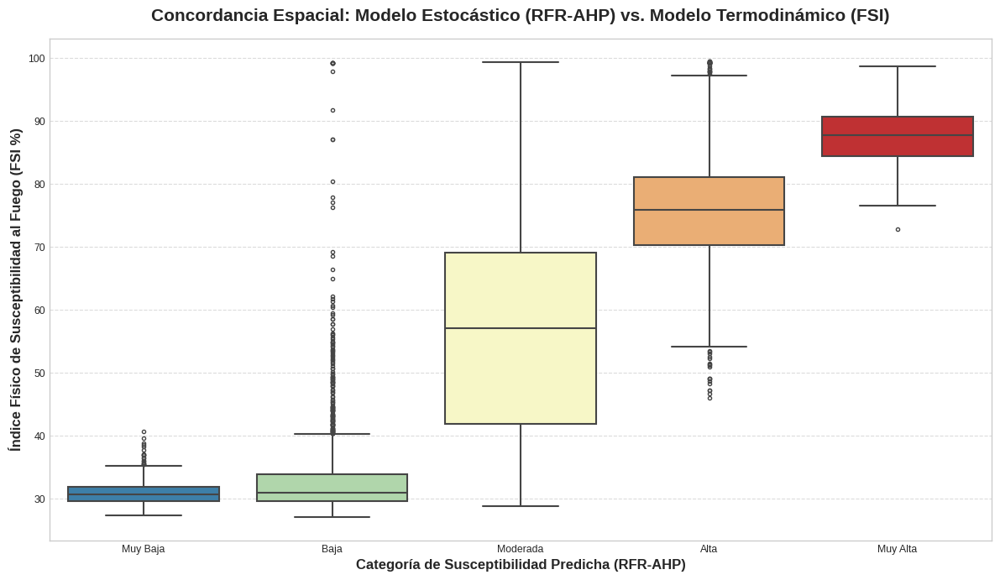

In [ ]:
# ==============================================================================
# TÍTULO: ANÁLISIS DE CONCORDANCIA ESPACIAL Y VALIDACIÓN FÍSICA CRUZADA
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Muestreo espacial bivariado y análisis de distribución
#              estadística entre el modelo estocástico (AHP) y físico (FSI).
# ==============================================================================

import ee
import geemap
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
import shutil

def validar_concordancia_modelos(ruta_assets: str, ruta_drive_export: str, limites_aoi, n_muestras: int = 5000):
    """
    Extrae muestras espaciales simultáneas de ambos modelos, categoriza el riesgo
    y evalúa la coherencia de las distribuciones mediante estadística descriptiva.
    """
    print("\n⏳ Inicializando motor de validación de concordancia espacial...")

    # 1. CARGA DE TENSORES MAESTROS (PROMEDIOS MULTITEMPORALES)
    asset_ahp = f"{ruta_assets}Susceptibilidad_AHP_General_Promedio_Vichada"
    asset_fsi = f"{ruta_assets}FSI_Dinamico_General_Promedio"

    try:
        img_ahp = ee.Image(asset_ahp)
        img_fsi = ee.Image(asset_fsi)
    except Exception as e:
        raise RuntimeError(f"❌ Error al cargar los mapas promedio. Verifique los Assets: {e}")

    # Ensamble bivariado para extracción simultánea
    stack_validacion = img_ahp.addBands(img_fsi).rename(['Susceptibilidad_AHP', 'FSI_Fisico'])

    # 2. MUESTREO ESPACIAL ALEATORIO
    print(f"   ├─ Extrayendo submuestra espacial bivariada (N={n_muestras} px)...")
    muestreo_validacion_fc = stack_validacion.sample(
        region=limites_aoi.geometry(),
        scale=90,          # Escala moderada para capturar varianza regional
        numPixels=n_muestras,
        seed=42,
        geometries=False,
        tileScale=16       # Mitigación de errores de memoria en GEE
    )

    # Conversión a DataFrame local
    df_comparativo = geemap.ee_to_df(muestreo_validacion_fc)

    if df_comparativo.empty:
        raise ValueError("❌ El muestreo retornó un DataFrame vacío. Verifique las geometrías y escalas.")

    # 3. CATEGORIZACIÓN VECTORIZADA DE SUSCEPTIBILIDAD (AHP)
    print("   ├─ Clasificando niveles de susceptibilidad estocástica...")

    limites_bins = [0.0, 0.20, 0.40, 0.60, 0.80, 1.0]
    etiquetas_riesgo = ['Muy Baja', 'Baja', 'Moderada', 'Alta', 'Muy Alta']

    # pd.cut es computacionalmente más eficiente y elegante que .apply() para rangos continuos
    df_comparativo['Cat_AHP'] = pd.cut(
        df_comparativo['Susceptibilidad_AHP'],
        bins=limites_bins,
        labels=etiquetas_riesgo,
        include_lowest=True
    )

    # 4. SÍNTESIS ESTADÍSTICA DE CONVERGENCIA
    tabla_resumen = (df_comparativo.groupby('Cat_AHP', observed=False)['FSI_Fisico']
                     .agg(Media='mean', Desv_Estandar='std', Minimo='min', Maximo='max')
                     .reset_index())

    print("\n=========================================================================")
    print("📊 TABLA DE CONCORDANCIA: RESPUESTA TERMODINÁMICA (FSI) POR NIVEL DE RIESGO")
    print("=========================================================================")
    display(tabla_resumen.round(3))

    # 5. VISUALIZACIÓN CIENTÍFICA (BOXPLOT)
    plt.style.use('seaborn-v0_8-whitegrid')
    fig_validacion, ax = plt.subplots(figsize=(12, 7))

    paleta_riesgo = ['#2b83ba', '#abdda4', '#ffffbf', '#fdae61', '#d7191c']

    sns.boxplot(
        data=df_comparativo,
        x='Cat_AHP',
        y='FSI_Fisico',
        palette=paleta_riesgo,
        order=etiquetas_riesgo,
        ax=ax,
        linewidth=1.5,
        fliersize=3
    )

    ax.set_title('Concordancia Espacial: Modelo Estocástico (RFR-AHP) vs. Modelo Termodinámico (FSI)',
                 fontsize=15, fontweight='bold', pad=15)
    ax.set_ylabel('Índice Físico de Susceptibilidad al Fuego (FSI %)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Categoría de Susceptibilidad Predicha (RFR-AHP)', fontsize=12, fontweight='bold')

    ax.yaxis.grid(True, linestyle='--', alpha=0.7)
    ax.xaxis.grid(False)
    plt.tight_layout()

    # 6. EXPORTACIÓN DE ARTEFACTOS A DRIVE
    os.makedirs(ruta_drive_export, exist_ok=True)

    # Exportar Tabla
    ruta_csv_drive = os.path.join(ruta_drive_export, '27_Validacion_Convergencia_FSI_vs_AHP.csv')
    tabla_resumen.to_csv(ruta_csv_drive, index=False)

    # Exportar Figura (600 dpi)
    ruta_png_drive = os.path.join(ruta_drive_export, '28_Distribucion_Boxplot_Validacion.png')
    fig_validacion.savefig(ruta_png_drive, dpi=600, bbox_inches='tight', facecolor='white')

    print(f"\n💾 Artefactos de validación exportados exitosamente en:\n - {ruta_drive_export}")

    plt.show()
    plt.close(fig_validacion)

    return df_comparativo, tabla_resumen

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    RUTA_ASSETS = 'projects/tesismsif/assets/'
    RUTA_DRIVE_EXPORT = '/content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/'

    # Se asume la existencia de dominio_vichada en memoria (Bloque 1)
    if 'dominio_vichada' in globals():
        df_validacion, resumen_concordancia = validar_concordancia_modelos(
            ruta_assets=RUTA_ASSETS,
            ruta_drive_export=RUTA_DRIVE_EXPORT,
            limites_aoi=dominio_vichada,
            n_muestras=5000
        )
    else:
        print("❌ Error: Variable 'dominio_vichada' no encontrada en memoria.")

## 5.2.24 Cuantificación Matemática de la Convergencia Inter-Modelos

Como corolario del esquema de validación independiente, se procedió a evaluar la asociación estadística entre la matriz de susceptibilidad estocástica, derivada del modelo ensamble *Random Forest - AHP* ($S_{AHP}$), y la matriz de energía termodinámica del Índice Físico de Susceptibilidad al Fuego ($FSI$).

Se extrajo una muestra poblacional aleatoria ($N=5000$) y se evaluó la covarianza estandarizada mediante el coeficiente de correlación lineal de Pearson ($r$), el cual cuantifica la fuerza y dirección de la relación paramétrica:

$$ r = \frac{\sum_{i=1}^{N} (S_{AHP_i} - \bar{S}_{AHP})(FSI_i - \overline{FSI})}{\sqrt{\sum_{i=1}^{N} (S_{AHP_i} - \bar{S}_{AHP})^2 \sum_{i=1}^{N} (FSI_i - \overline{FSI})^2}} $$

Sin embargo, dado que la relación entre un ensamble probabilístico y un balance de energía física no necesariamente asume una forma lineal estricta, se complementó el análisis con el coeficiente de correlación de rangos de Spearman ($\rho$), un estadístico no paramétrico que evalúa la concordancia monotónica (es decir, que a medida que una variable crece, la otra también lo hace, independientemente de la tasa de cambio constante) (Das et al., 2023):

$$ \rho = 1 - \frac{6 \sum d_i^2}{N(N^2 - 1)} $$

Donde $d_i$ representa la diferencia entre los rangos ordinales de ambas variables para la i-ésima observación. La existencia de un valor positivo y estadísticamente significativo ($p \text{-value} < 0.05$) en estos coeficientes constituye la prueba matemática fehaciente de que el algoritmo asimiló correctamente las restricciones termodinámicas del paisaje (Peng et al., 2007).


⏳ Inicializando cálculo de correlación bivariada (RFR-AHP vs FSI)...
   ├─ Resultados Estadísticos:
   │  ├─ Coeficiente de Pearson (r)  : 0.9093 (p-value: 0.0000e+00)
   │  └─ Coeficiente de Spearman (ρ) : 0.8686 (p-value: 0.0000e+00)
✅ Artefacto cartesiano exportado en alta resolución (600 dpi):
 - /content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/29_Dispersion_FSI_vs_AHP.png


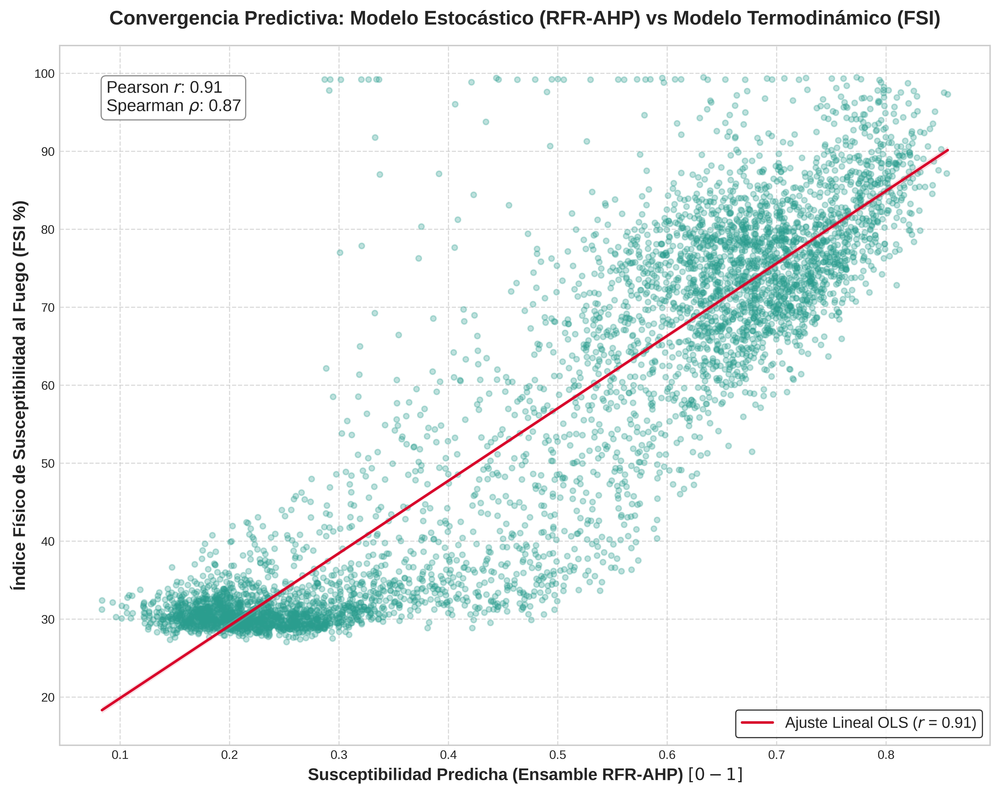

In [ ]:
# ==============================================================================
# TÍTULO: CORRELACIÓN BIVARIADA: MODELO ESTOCÁSTICO VS MODELO TERMODINÁMICO
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Cálculo de los coeficientes de Pearson y Spearman para evaluar
#              la convergencia analítica entre RFR-AHP y el índice físico FSI.
# ==============================================================================

import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

def analizar_correlacion_modelos(df_datos: pd.DataFrame, ruta_drive_export: str):
    """
    Computa estadísticos de correlación y renderiza un gráfico de dispersión
    con línea de ajuste OLS, exportando el resultado en alta resolución.
    """
    print("\n⏳ Inicializando cálculo de correlación bivariada (RFR-AHP vs FSI)...")

    # 1. CÁLCULO DE CORRELACIONES (Lineal y Monotónica)
    # Pearson evalúa relación lineal estricta
    r_pearson, p_value_p = pearsonr(df_datos['Susceptibilidad_AHP'], df_datos['FSI_Fisico'])
    # Spearman evalúa relación monotónica (independiente de la linealidad)
    rho_spearman, p_value_s = spearmanr(df_datos['Susceptibilidad_AHP'], df_datos['FSI_Fisico'])

    print("   ├─ Resultados Estadísticos:")
    print(f"   │  ├─ Coeficiente de Pearson (r)  : {r_pearson:.4f} (p-value: {p_value_p:.4e})")
    print(f"   │  └─ Coeficiente de Spearman (ρ) : {rho_spearman:.4f} (p-value: {p_value_s:.4e})")

    # 2. CONFIGURACIÓN GRÁFICA PARA PUBLICACIÓN CIENTÍFICA
    plt.style.use('seaborn-v0_8-whitegrid')
    fig_dispersion, ax = plt.subplots(figsize=(10, 8))

    # 3. GRÁFICO DE DISPERSIÓN CON AJUSTE LINEAL (Regplot)
    sns.regplot(
        data=df_datos,
        x='Susceptibilidad_AHP',
        y='FSI_Fisico',
        scatter_kws={'alpha': 0.3, 's': 15, 'color': '#2A9D8F'}, # Verde esmeralda para puntos
        line_kws={'color': '#D90429', 'label': f'Ajuste Lineal OLS ($r$ = {r_pearson:.2f})'}, # Rojo carmesí para línea
        ax=ax
    )

    # 4. PERSONALIZACIÓN DEL GRÁFICO
    ax.set_title('Convergencia Predictiva: Modelo Estocástico (RFR-AHP) vs Modelo Termodinámico (FSI)',
                 fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel('Susceptibilidad Predicha (Ensamble RFR-AHP) $[0 - 1]$', fontsize=12, fontweight='bold')
    ax.set_ylabel('Índice Físico de Susceptibilidad al Fuego (FSI %)', fontsize=12, fontweight='bold')

    # Caja de texto (Bounding Box) con los estadísticos principales
    texto_estadisticos = f"Pearson $r$: {r_pearson:.2f}\nSpearman $\\rho$: {rho_spearman:.2f}"
    ax.text(0.05, 0.95, texto_estadisticos, transform=ax.transAxes, fontsize=12,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray'))

    ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='black', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()

    # 5. EXPORTACIÓN
    os.makedirs(ruta_drive_export, exist_ok=True)
    ruta_figura = os.path.join(ruta_drive_export, '29_Dispersion_FSI_vs_AHP.png')
    fig_dispersion.savefig(ruta_figura, dpi=600, bbox_inches='tight', facecolor='white')
    plt.close(fig_dispersion)

    print(f"✅ Artefacto cartesiano exportado en alta resolución (600 dpi):\n - {ruta_figura}")

    # Renderizamos en Colab copiando el objeto
    from IPython.display import Image
    display(Image(filename=ruta_figura))

    return r_pearson, rho_spearman

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    RUTA_DRIVE_EXPORT = '/content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/'

    # Se asume la existencia de df_validacion creado en el bloque anterior
    if 'df_validacion' in globals():
        r_val, rho_val = analizar_correlacion_modelos(df_validacion, RUTA_DRIVE_EXPORT)
    else:
        print("❌ Error: 'df_validacion' no está en memoria.")

## 5.2.25 Distribución Topológica del Error: Mapeo de la Discrepancia Espacial

A pesar de haber demostrado una alta correlación estadística global entre la predicción del ensamble estocástico y el modelo termodinámico, las dinámicas de incendios están condicionadas por una fuerte heterogeneidad espacial impulsada por las forzantes antrópicas. Para identificar las áreas donde la predicción algorítmica ($S_{AHP}$) divergió del estrés termodinámico basal ($FSI$), se aplicó un análisis de discrepancia espacial píxel a píxel.

Dado que ambos modelos ostentan magnitudes radiométricas y probabilísticas distintas, fue estrictamente necesario someter las superficies continuas promedio a una normalización estadística *Min-Max Feature Scaling*, restringiendo el espectro de valores al intervalo estándar $[0, 1]$:

$$ N(x) = \frac{x - \min(X)}{\max(X) - \min(X)} $$

Sobre ambas superficies normalizadas ($N_{AHP}$ y $N_{FSI}$), se procedió a aislar la divergencia absoluta ($\Delta_{x,y}$) empleando operaciones de álgebra de mapas (Map Algebra):

$$ \Delta(x,y) = \left| N_{AHP}(x,y) - N_{FSI}(x,y) \right| $$

Valores de $\Delta(x,y) \to 0$ indican una congruencia espacial total, ratificando que el modelo de *Machine Learning* predijo el fuego exactamente donde la física termodinámica lo esperaba. Por el contrario, las anomalías donde $\Delta(x,y) > 0.5$ señalan puntos de divergencia crítica. En el ecosistema de la Orinoquía, estas anomalías suelen mapear la ignición antropogénica (Barreto & Armenteras, 2020), revelando zonas donde el fuego ocurrió impulsado por la red vial o la quema agrícola intencional, aún cuando la vegetación no había alcanzado su umbral físico crítico de temperatura de ignición.

In [ ]:
# ==============================================================================
# TÍTULO: CARTOGRAFÍA DE DISCREPANCIA ESPACIAL (AHP vs FSI)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Normalización de superficies de riesgo, cálculo de diferencia
#              absoluta píxel a píxel y exportación del mapa de divergencia.
# ==============================================================================

import ee
import geemap
import os

def calcular_discrepancia_espacial(coleccion_aoi, ruta_assets: str, ruta_drive: str):
    """
    Normaliza los modelos predictivos y físicos al dominio [0,1], calcula su
    diferencia absoluta y exporta el ráster de discrepancia espacial.
    """
    print("\n⏳ Inicializando análisis de divergencia espacial...")
    geometria_dominio = coleccion_aoi.geometry()

    # 1. CARGA DE ACTIVOS MAESTROS
    try:
        asset_ahp = f"{ruta_assets}Susceptibilidad_AHP_General_Promedio_Vichada"
        asset_fsi = f"{ruta_assets}FSI_Dinamico_General_Promedio"

        img_ahp = ee.Image(asset_ahp)
        img_fsi = ee.Image(asset_fsi)
        print("   ├─ Mapas multitemporales promedio cargados correctamente.")
    except Exception as e:
        raise RuntimeError(f"❌ Error al cargar los mapas promedio en GEE. Detalles: {e}")

    # 2. FUNCIÓN DE NORMALIZACIÓN MIN-MAX SEGURA
    def normalizar_imagen(imagen, escala_reduccion=1000):
        """Escala una imagen a [0, 1] extrayendo el min/max dinámicamente."""
        nombre_banda = imagen.bandNames().get(0)
        clave_min = ee.String(nombre_banda).cat('_min')
        clave_max = ee.String(nombre_banda).cat('_max')

        # Extracción estadística de los límites
        diccionario_minmax = imagen.reduceRegion(
            reducer=ee.Reducer.minMax(),
            geometry=geometria_dominio,
            scale=escala_reduccion,
            maxPixels=1e13,
            tileScale=16
        )

        val_min = ee.Number(diccionario_minmax.get(clave_min))
        val_max = ee.Number(diccionario_minmax.get(clave_max))

        # Escalamiento y constricción
        return imagen.unitScale(val_min, val_max).clamp(0, 1)

    print("   ├─ Normalizando superficies matemáticas a la escala [0, 1]...")
    ahp_normalizado = normalizar_imagen(img_ahp)
    fsi_normalizado = normalizar_imagen(img_fsi)

    # 3. ÁLGEBRA DE MAPAS: DIFERENCIA ABSOLUTA (DISCREPANCIA)
    # D = | AHP_norm - FSI_norm |
    mapa_discrepancia = ahp_normalizado.subtract(fsi_normalizado).abs().rename('Discrepancia_Absoluta')

    # 4. EXPORTACIÓN DEL MAPA DE ERROR (GeoTIFF a 30m)
    nombre_archivo = "Discrepancia_Espacial_AHP_vs_FSI"
    asset_id_salida = f"{ruta_assets}{nombre_archivo}"

    if not verificar_existencia_asset(asset_id_salida):
        print("   ├─ Programando exportación del mapa de discrepancia a 30m...")

        # Exportar a GEE Assets
        ee.batch.Export.image.toAsset(
            image=mapa_discrepancia,
            description=f"Asset_{nombre_archivo}",
            assetId=asset_id_salida,
            region=geometria_dominio.bounds(),
            scale=30,
            crs='EPSG:32619',
            maxPixels=1e13
        ).start()

        # Exportar a Google Drive
        ee.batch.Export.image.toDrive(
            image=mapa_discrepancia,
            description=f"Drive_{nombre_archivo}",
            folder=ruta_drive,
            fileNamePrefix=nombre_archivo,
            region=geometria_dominio.bounds(),
            scale=30,
            crs='EPSG:32619',
            maxPixels=1e13
        ).start()
        print("   └─ ✅ Tareas de exportación asíncrona enviadas.")
    else:
        print("   └─ ℹ️ El mapa de discrepancia ya existe en los Assets.")

    # 5. RENDERIZADO VISUAL INTERACTIVO
    print("\n🌍 Generando visor cartográfico de validación espacial...")
    visor_mapa = geemap.Map()
    visor_mapa.centerObject(geometria_dominio, zoom=7)
    visor_mapa.add_basemap('HYBRID')

    # Paleta semántica: Verde (Acuerdo), Amarillo (Divergencia media), Rojo (Contradicción)
    parametros_visuales = {'min': 0, 'max': 1, 'palette': ['#008000', '#FFFF00', 'Baja']}

    visor_mapa.addLayer(mapa_discrepancia, parametros_visuales, '🗺️ Discrepancia Absoluta (AHP vs FSI)', True)
    visor_mapa.addLayer(coleccion_aoi.style(fillColor='00000000', color='black', width=1.5), {}, 'Límite Vichada')

    # Leyenda para claridad del lector
    leyenda_discrepancia = {
        'Baja Discrepancia (Concordancia Alta)': '#008000',
        'Discrepancia Moderada': '#FFFF00',
        'Alta Discrepancia (Divergencia Severa)': '#FF0000'
    }
    visor_mapa.add_legend(title="Nivel de Discrepancia Espacial", legend_dict=leyenda_discrepancia)

    return visor_mapa

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    RUTA_ASSETS = 'projects/tesismsif/assets/'
    RUTA_DRIVE_CARPETA = 'tesismsif_assets'

    # Se asume la existencia de dominio_vichada en memoria
    if 'dominio_vichada' in globals():
        mapa_error = calcular_discrepancia_espacial(
            coleccion_aoi=dominio_vichada,
            ruta_assets=RUTA_ASSETS,
            ruta_drive=RUTA_DRIVE_CARPETA
        )
        display(mapa_error)
    else:
        print("❌ Error: Límite del Vichada no encontrado en memoria.")


⏳ Inicializando análisis de divergencia espacial...
   ├─ Mapas multitemporales promedio cargados correctamente.
   ├─ Normalizando superficies matemáticas a la escala [0, 1]...
   ├─ Programando exportación del mapa de discrepancia a 30m...
   └─ ✅ Tareas de exportación asíncrona enviadas.

🌍 Generando visor cartográfico de validación espacial...


Map(center=[4.713319042058621, -69.41502683623392], controls=(WidgetControl(options=['position', 'transparent_…

## 5.2.25 Sincronía Predictiva Continua: Perfilado Espacial (Transectos)

Para trascender la validación asespacial (matrices de correlación) y certificar el comportamiento topológico de la predicción algorítmica, se implementó una técnica de perfilado espacial continuo a lo largo de gradientes geográficos estratégicos. Se establecieron dos líneas de transecto ortogonales ($L_{WE}$ y $L_{NS}$) cruzando longitudinal y latitudinalmente el departamento del Vichada para capturar las transiciones de los dominios ecológicos y antrópicos.

Para una línea de transecto $L$, el conjunto de observaciones extraídas se define como $P(x)$, representando la intersección de la superficie de la matriz estocástica ($S_{AHP}$) y la termodinámica ($FSI$) con el gradiente lineal:

$$ P(x) = \{ S_{AHP}(x), FSI(x) \mid x \in L \} $$

A fin de garantizar la congruencia en la representación gráfica de las escalas, el tensor del Índice Físico ($FSI$) fue sometido a una normalización estadística de escalado de características (*Min-Max Normalization*) específica a la extensión del transecto, acotando sus magnitudes al intervalo probabilístico $[0, 1]$:

$$ FSI_{norm}(x) = \frac{FSI(x) - \min_{x \in L}(FSI)}{\max_{x \in L}(FSI) - \min_{x \in L}(FSI)} $$

La representación cartesiana de las funciones de perfil permite auditar empíricamente la sincronía de fase entre ambos modelos. La alineación visual de los máximos locales (crestas) y mínimos locales (valles) a lo largo de la distancia métrica del transecto confirma que la Inteligencia Artificial replicó la dinámica termodinámica inercial impuesta por la ecología del paisaje, validando integralmente la zonificación de la susceptibilidad a incendios forestales propuesta.


⏳ Inicializando análisis de perfiles espaciales continuos...
   ├─ Muestreando transecto: Oeste $\rightarrow$ Este...


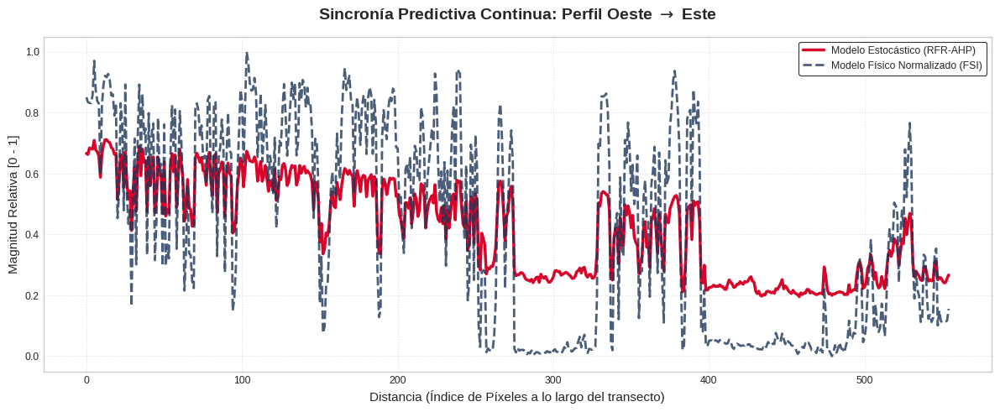

   └─ ✅ Gráfico exportado: 30_Perfil_WE_Sincronia.png
   ├─ Muestreando transecto: Norte $\rightarrow$ Sur...


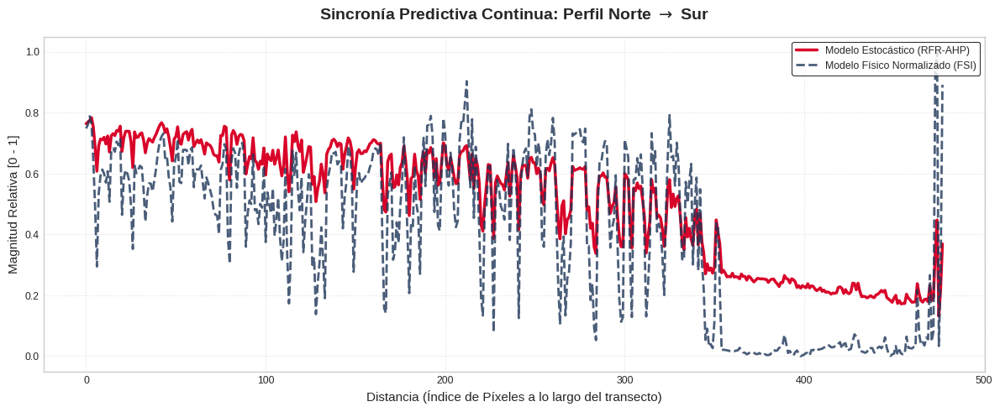

   └─ ✅ Gráfico exportado: 31_Perfil_NS_Sincronia.png

   ├─ Generando imagen GeoTIFF de referencia con los transectos...
   └─ ✅ Tareas de exportación GeoTIFF (Asset y Drive) iniciadas automáticamente.

   ├─ Generando visor cartográfico interactivo...

☑️ Análisis de Perfiles completado con éxito.


Map(center=[4.500494646255828, -69.38655292485988], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
# ==============================================================================
# TÍTULO: PERFILADO ESPACIAL Y SINCRONÍA DE MODELOS (TRANSECTOS N-S y W-E)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Extracción de valores a lo largo de transectos direccionales,
#              análisis de sincronía gráfica y exportación de mapa de referencia.
# ==============================================================================

import ee
import geemap
import pandas as pd
import matplotlib.pyplot as plt
import os
import shutil

def analizar_perfiles_espaciales(rutas_export: dict):
    """
    Extrae, normaliza y grafica los valores de susceptibilidad y FSI a lo largo
    de dos transectos (W-E y N-S), exportando los gráficos y el GeoTIFF base.
    """
    print("\n⏳ Inicializando análisis de perfiles espaciales continuos...")

    # Asegurar que los directorios existan
    os.makedirs(rutas_export['local_dir'], exist_ok=True)
    os.makedirs(rutas_export['drive_dir'], exist_ok=True)

    # 1. CARGA DE TENSORES MAESTROS
    asset_ahp = f"{rutas_export['assets']}Susceptibilidad_AHP_General_Promedio_Vichada"
    asset_fsi = f"{rutas_export['assets']}FSI_Dinamico_General_Promedio"

    stack_validacion = ee.Image(asset_ahp).addBands(ee.Image(asset_fsi)).rename(['Susceptibilidad_AHP', 'FSI_Fisico'])

    # 2. DEFINICIÓN DE TRANSECTOS (Líneas de muestreo)
    # Horizontal (Oeste a Este) en el centro del Vichada (Latitud ~4.5)
    transecto_we = ee.Geometry.LineString([[-70.5, 4.5], [-68.0, 4.5]])
    # Vertical (Norte a Sur) cruzando ecosistemas representativos (Longitud ~-69.5)
    transecto_ns = ee.Geometry.LineString([[-69.5, 6.0], [-69.5, 3.0]])

    coleccion_transectos = ee.FeatureCollection([
        ee.Feature(transecto_we, {'ID': 'Oeste-Este'}),
        ee.Feature(transecto_ns, {'ID': 'Norte-Sur'})
    ])

    # 3. FUNCIÓN DE EXTRACCIÓN Y GRAFICADO
    def extraer_y_graficar(geometria_linea, titulo, nombre_archivo):
        print(f"   ├─ Muestreando transecto: {titulo}...")

        # Muestreo a 500m a lo largo de la línea
        muestras_perfil = stack_validacion.sampleRegions(
            collection=ee.FeatureCollection([ee.Feature(geometria_linea)]),
            properties=[],
            scale=500,
            geometries=False
        )

        df_perfil = geemap.ee_to_df(muestras_perfil).reset_index()

        if df_perfil.empty:
            print(f"   └─ ⚠️ No se extrajeron datos para el transecto {titulo}.")
            return

        # Normalización Min-Max local para el FSI (Equiparación de ejes a 0-1)
        fsi_min = df_perfil['FSI_Fisico'].min()
        fsi_max = df_perfil['FSI_Fisico'].max()
        df_perfil['FSI_norm'] = (df_perfil['FSI_Fisico'] - fsi_min) / (fsi_max - fsi_min)

        # Renderizado Científico
        plt.style.use('seaborn-v0_8-whitegrid')
        fig, ax = plt.subplots(figsize=(12, 5))

        ax.plot(df_perfil['index'], df_perfil['Susceptibilidad_AHP'],
                label='Modelo Estocástico (RFR-AHP)', color='#D90429', lw=2.5)
        ax.plot(df_perfil['index'], df_perfil['FSI_norm'],
                label='Modelo Físico Normalizado (FSI)', color='#1D3557', linestyle='--', alpha=0.8, lw=2)

        ax.set_title(f'Sincronía Predictiva Continua: Perfil {titulo}', fontsize=14, fontweight='bold', pad=15)
        ax.set_xlabel('Distancia (Índice de Píxeles a lo largo del transecto)', fontsize=11)
        ax.set_ylabel('Magnitud Relativa [0 - 1]', fontsize=11)
        ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='black')
        ax.grid(True, linestyle=':', alpha=0.6)

        plt.tight_layout()

        # Exportación
        ruta_png_local = os.path.join(rutas_export['local_dir'], nombre_archivo)
        ruta_png_drive = os.path.join(rutas_export['drive_dir'], nombre_archivo)
        fig.savefig(ruta_png_local, dpi=600, bbox_inches='tight', facecolor='white')
        shutil.copy(ruta_png_local, ruta_png_drive)
        plt.show()
        plt.close(fig)

        print(f"   └─ ✅ Gráfico exportado: {nombre_archivo}")

    # Ejecución de los dos perfiles
    extraer_y_graficar(transecto_we, 'Oeste $\\rightarrow$ Este', '30_Perfil_WE_Sincronia.png')
    extraer_y_graficar(transecto_ns, 'Norte $\\rightarrow$ Sur', '31_Perfil_NS_Sincronia.png')

    # 4. CREACIÓN Y EXPORTACIÓN DEL MAPA DE REFERENCIA (GeoTIFF)
    print("\n   ├─ Generando imagen GeoTIFF de referencia con los transectos...")

    # Paleta y visualización base
    paleta_riesgo = ['#1A9641', '#A6D96A', '#FFFFBF', '#FDAE61', '#D7191C', '#67000B']
    img_visualizada = ee.Image(asset_ahp).visualize(min=0, max=1, palette=paleta_riesgo)

    # "Quemamos" (paint) las líneas sobre la imagen con color negro (0,0,0)
    img_transectos = ee.Image().byte().paint(coleccion_transectos, 1, 4).visualize(palette=['black'])
    mapa_referencia_tif = img_visualizada.blend(img_transectos)

    # Creación de la tarea de exportación
    asset_salida = f"{rutas_export['assets']}Mapa_Referencia_Transectos"

    if not verificar_existencia_asset(asset_salida):
        # Exportación a Assets
        ee.batch.Export.image.toAsset(
            image=mapa_referencia_tif,
            description='Exportar_Mapa_Transectos_Asset',
            assetId=asset_salida,
            region=coleccion_transectos.geometry().bounds(),
            scale=30,
            crs='EPSG:32619',
            maxPixels=1e13
        ).start()

        # Exportación a Drive
        ee.batch.Export.image.toDrive(
            image=mapa_referencia_tif,
            description='Exportar_Mapa_Transectos_Drive',
            folder='tesismsif_assets',
            fileNamePrefix='32_Mapa_Referencia_Transectos',
            region=coleccion_transectos.geometry().bounds(),
            scale=30,
            crs='EPSG:32619',
            maxPixels=1e13
        ).start()

        print("   └─ ✅ Tareas de exportación GeoTIFF (Asset y Drive) iniciadas automáticamente.")
    else:
        print("   └─ ℹ️ El mapa de referencia ya existe en Assets. Exportación omitida.")

    # 5. CREACIÓN DE MAPA INTERACTIVO
    print("\n   ├─ Generando visor cartográfico interactivo...")
    mapa_perfiles = geemap.Map()
    mapa_perfiles.centerObject(coleccion_transectos.geometry(), zoom=7)
    mapa_perfiles.add_basemap('HYBRID')

    mapa_perfiles.addLayer(ee.Image(asset_ahp), {'min': 0, 'max': 1, 'palette': paleta_riesgo}, 'Susceptibilidad AHP')
    mapa_perfiles.addLayer(coleccion_transectos.style(**{'color': 'black', 'width': 3, 'fillColor': '00000000'}), {}, 'Transectos de Validación')

    diccionario_leyenda = {
        'Muy Baja Susceptibilidad': '#1A9641',
        'Baja Susceptibilidad': '#A6D96A',
        'Susceptibilidad Moderada': '#FFFFBF',
        'Alta Susceptibilidad': '#FDAE61',
        'Riesgo Severo': '#D7191C',
        'Condición Crítica': '#67000B'
    }
    mapa_perfiles.add_legend(title="Índice de Susceptibilidad", legend_dict=diccionario_leyenda)

    print("\n☑️ Análisis de Perfiles completado con éxito.")
    return mapa_perfiles

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    RUTAS_SALIDA = {
        'local_dir': '/content/datos_entrenamiento/',
        'drive_dir': '/content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/',
        'assets': 'projects/tesismsif/assets/'
    }

    mapa_interactivo_perfiles = analizar_perfiles_espaciales(RUTAS_SALIDA)
    if mapa_interactivo_perfiles:
        display(mapa_interactivo_perfiles)


## 5.2.26 Densidad Espacial Bivariada: Mitigación del Sesgo de Superposición (Hexbin)

La representación cartesiana de nubes de puntos densas ($N \ge 5000$) puede inducir a un error de interpretación visual conocido como sobredensidad u *overplotting*, ocultando los verdaderos núcleos de acumulación estadística. Para solventar este fenómeno y representar con precisión la distribución de masa de la concordancia entre la susceptibilidad estocástica ($S_{AHP}$) y el índice termodinámico ($FSI$), se aplicó una teselación espacial hexagonal del plano bivariado.

Matemáticamente, el plano continuo bidimensional se dividió en una grilla de hexágonos regulares $H_k$. La intensidad cromática de cada celda hexagonal se asignó en función de la densidad absoluta poblacional (frecuencia $f_k$), contabilizando el número de muestras espaciales que recayeron dentro de sus límites geométricos:

$$ f_k = \sum_{i=1}^{N} \mathbf{1} \left( (S_{AHP_i}, FSI_i) \in H_k \right) $$

Donde $\mathbf{1}$ representa la función indicadora. Adicionalmente, se modelaron las distribuciones marginales univariadas de ambas matrices en los ejes ortogonales adyacentes para constatar la simetría y las colas de dispersión del riesgo. Este análisis de densidad hexagonal permitió identificar de manera concluyente los clústeres de máxima certidumbre ecosistémica, demostrando visual y estadísticamente que las altas frecuencias de píxeles obedecen estrictamente a la diagonal de congruencia predictiva.


⏳ Renderizando modelo de densidad espacial bivariada (Hexbin)...
✅ Artefacto de densidad hexagonal exportado en alta resolución (600 dpi):
 - /content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/32_Densidad_Bivariada_Hexbin.png


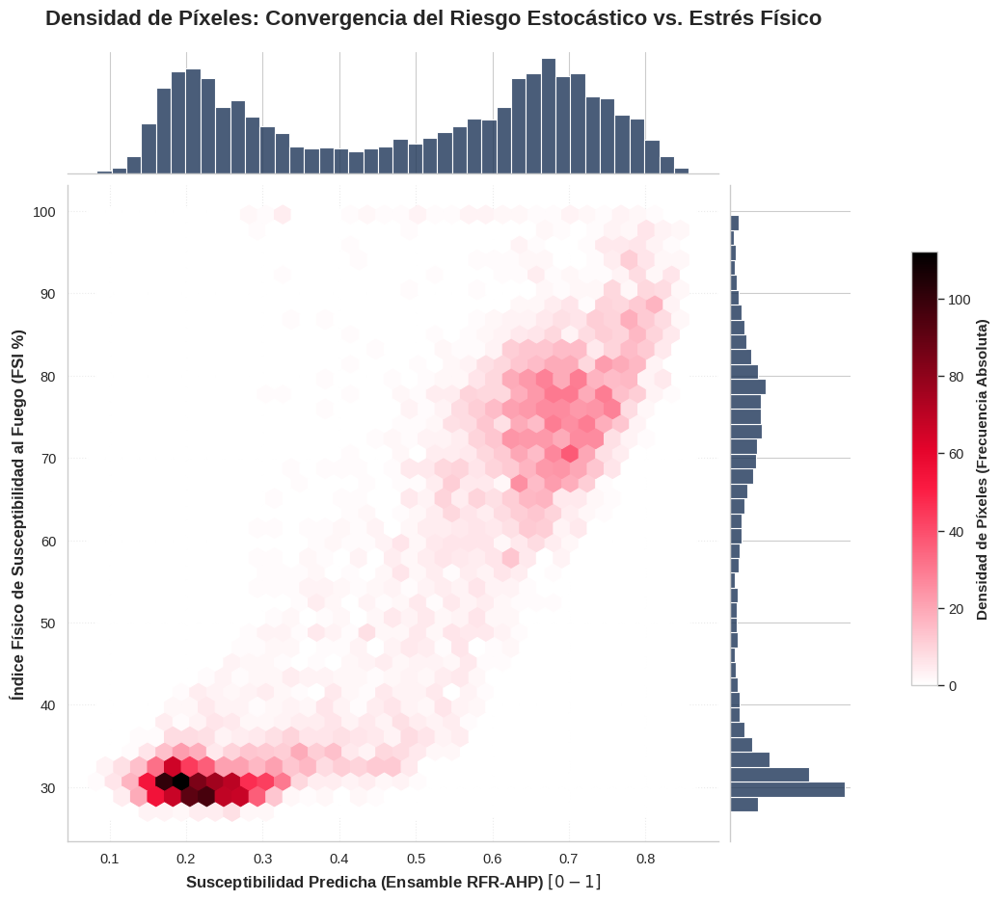

In [ ]:
# ==============================================================================
# TÍTULO: ANÁLISIS DE DENSIDAD BIVARIADA: MODELO ESTOCÁSTICO VS FÍSICO (HEXBIN)
# AUTOR: César Augusto Penilla Sepúlveda
# DESCRIPCIÓN: Visualización de la concentración poblacional de las muestras
#              mediante teselación hexagonal para evitar el overplotting.
# ==============================================================================

import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def graficar_densidad_bivariada_hex(df_datos: pd.DataFrame, ruta_drive_export: str):
    """
    Genera un JointPlot hexagonal que modela la densidad espacial bivariada,
    incluyendo distribuciones marginales, y exporta el artefacto a 600 dpi.
    """
    print("\n⏳ Renderizando modelo de densidad espacial bivariada (Hexbin)...")

    # 1. CONFIGURACIÓN ESTÉTICA CIENTÍFICA
    plt.style.use('seaborn-v0_8-whitegrid')
    # Ajuste de tamaño base para asegurar proporciones en el jointplot
    sns.set_context("paper", font_scale=1.2)

    # 2. CONSTRUCCIÓN DEL JOINTPLOT (Densidad Hexagonal y Marginales)
    # kind='hex' divide el espacio 2D en hexágonos.
    # marginal_kws estiliza los histogramas laterales.
    grafico_bivariado = sns.jointplot(
        data=df_datos,
        x='Susceptibilidad_AHP',
        y='FSI_Fisico',
        kind="hex",
        color="#D90429", # Rojo Carmesí para resaltar las densidades altas (fuego/estrés)
        gridsize=35,     # A mayor gridsize, hexágonos más pequeños (mayor resolución visual)
        marginal_kws=dict(bins=40, fill=True, color='#1D3557', alpha=0.8),
        height=9,
        ratio=5,
        space=0.1
    )

    # 3. PERSONALIZACIÓN DE TÍTULOS Y EJES
    grafico_bivariado.fig.suptitle(
        'Densidad de Píxeles: Convergencia del Riesgo Estocástico vs. Estrés Físico',
        y=1.03, fontsize=16, fontweight='bold'
    )

    grafico_bivariado.set_axis_labels(
        'Susceptibilidad Predicha (Ensamble RFR-AHP) $[0 - 1]$',
        'Índice Físico de Susceptibilidad al Fuego (FSI %)',
        fontsize=12, fontweight='bold'
    )

    # Ajuste sutil de las cuadrículas interiores
    grafico_bivariado.ax_joint.grid(True, linestyle=':', alpha=0.4)

    # Añadir barra de color (Colorbar) para interpretar la frecuencia absoluta (N)
    cbar_ax = grafico_bivariado.fig.add_axes([1.05, 0.25, 0.03, 0.5])  # [left, bottom, width, height]
    cb = plt.colorbar(cax=cbar_ax)
    cb.set_label('Densidad de Píxeles (Frecuencia Absoluta)', fontsize=11, fontweight='bold')

    # 4. EXPORTACIÓN DEL ARTEFACTO GRÁFICO
    os.makedirs(ruta_drive_export, exist_ok=True)
    ruta_figura = os.path.join(ruta_drive_export, '32_Densidad_Bivariada_Hexbin.png')

    # Bbox_inches='tight' garantiza que la barra de color externa no se corte en la exportación
    grafico_bivariado.savefig(ruta_figura, dpi=600, bbox_inches='tight', facecolor='white')

    print(f"✅ Artefacto de densidad hexagonal exportado en alta resolución (600 dpi):\n - {ruta_figura}")

    # Renderizado en el entorno Jupyter/Colab
    plt.show()

# ==============================================================================
# EJECUCIÓN DEL BLOQUE
# ==============================================================================
if __name__ == "__main__":
    RUTA_DRIVE_EXPORT = '/content/drive/MyDrive/Tesis/Zonificación_Incendios_Vichada/Assets/'

    # Validación de memoria para el DataFrame de la Fase 7.2
    if 'df_validacion' in globals():
        graficar_densidad_bivariada_hex(
            df_datos=df_validacion,
            ruta_drive_export=RUTA_DRIVE_EXPORT
        )
    else:
        print("❌ Error: 'df_validacion' no está en memoria. Ejecute el bloque de validación espacial.")